---
title: "TSM v4: alcohol consumption transitions harmonized with the EPS engine"
subtitle: "Rounds 7–11, five states (C3plus), whole-person bootstrap and cross-check against EPS"
author: "Andres Gonzalez Santa Cruz"
lang: en
format:
  html:
    theme: journal
    css: [_lib/styles.css, _lib/prediction_metrics_compact.css]
    toc: true
    toc-location: left
    toc-depth: 2
    number-sections: false
    code-fold: true
    code-summary: "Show R code"
    code-tools: true
    embed-resources: true
    self-contained: true
    html-math-method: mathml
execute:
  echo: true
  warning: false
  error: false
---

**Quick orientation:** the same people are followed across five rounds of the Termómetro de la Salud Mental (TSM), rounds 7 to 11, and their drinking category at one round is used to predict the category at the next. The computation is the EPS transition engine ported to this panel: the same states (five since 2026-10-26, with C3 and C4 merged into C3plus), the same models, the same person-blocked validation and the same annual layer. What changes is the data layer, because TSM has short intervals, no survey design variables and alcohol items without a recall window. Every result in this notebook comes from the saved tables; the text explains how to read them and does not restate numbers.

## What changed in version 4

Version 4 (2026-10-26) keeps the version 3 engine and changes three things, recorded in `__andres_control/decision_categorias_who_12g_2026-10-26.md`:

1. **Five states.** C3 and C4 are always one state, C3plus, at origin and destination, as in Puka et al. (2022) and Kilian et al. (2025): the top WHO category is too sparse to be a state of its own. Version 3 estimated six states and merged them only in a side table.
2. **WHO borders without gaps.** The exact border value goes to the lower class. No TSM value falls exactly on a border, so no label changes.
3. **A two-year link tolerance chosen from the data.** Version 3 widened the strict EPS age bounds by one year. Version 4 widens them by two, because pairs one or two years outside the strict bounds disagree on education about as often as strict pairs, while the few pairs further out disagree about twice as often.

**Can there be five states when TSM cannot always tell a former drinker from a lifetime abstainer?** Yes, with a caveat. FD is not asked; it is built from the panel: a current non-drinker is FD when drinking was observed at an earlier compatible interview. So FD is well defined, but N0 is a mixture: it contains lifetime abstainers and former drinkers whose drinking happened before the panel started (everyone who does not drink at round 7 is N0). The two non-drinking states therefore mean "no drinking seen in the panel" (N0) and "stopped within the panel" (FD), not "never" and "ever". The destination classes do not depend on this split: every model predicts NC, C1, C2 or C3plus, and NC is divided into N0 or FD afterwards by the origin history. Puka et al. merge lifetime abstainers and former drinkers into one non-drinker state for the same reason; here the split is kept as a covariate and for comparability with EPS, whose 2009 history (EPS version 4) identifies former drinkers far better.

**Added on 2026-10-27:** an exploratory section on the persistence of heavy episodic drinking beyond volume. It evaluates the engine's assumed yearly correlation of 0.8 against the panel and separates what the data support from what remains a scenario; it does not change any state, model or matrix above.

The executed version 3 notebook (`TSM_ENPG_v3_EN.ipynb`, outputs in `tsm_markov_outputs/`) is kept unchanged as history; version 4 writes to `tsm_markov_outputs_v4/`.

## How this notebook relates to version 2 and to the EPS engine

Version 2 of the TSM analysis was built on its own conventions. Version 3 kept its data reading and linking, which are checked against the version 2 counts, and replaced everything downstream with the EPS engine so that the two Chilean panels produce matrices that can be read side by side; version 4 keeps that design. The crosswalk below lists each decision in the three vocabularies.

| Decision | TSM v2 | TSM v4 (this notebook) | EPS engine |
|---|---|---|---|
| States | ND_unknown, FD, cat1–cat4 | N0, FD, C1, C2, C3plus | N0, FD, C1–C4 (v1/v2); N0, FD, C1, C2, C3plus (v4) |
| Destination classes | six states | NC, C1, C2, C3plus (NC splits into N0/FD by origin history) | NC, C1–C4 (v1/v2); NC, C1, C2, C3plus (v4) |
| Sex labels | Male, Female | Men, Women | Men, Women |
| Age groups | continuous age and age squared | 18–29, 30–44, 45–59, 60–65 at origin | same |
| Intervals | four adjacent links, wave term | R7→R8, R8→R9, R9→R10, R10→R11, each with its elapsed months | VI→VII, VII→VIII, each with its elapsed years |
| Link rule | same `IdPanel` | same `IdPanel`, same sex, age change within the EPS bounds widened by two years (chosen from the data, see the link section), because TSM ages are roster values corrected sporadically; strict EPS bounds as sensitivity | same `folio`, same sex, age change compatible with the elapsed years (v4: widened by three years) |
| Former-drinker (FD) rule | drinking observed in any earlier wave | drinking observed earlier and carried along the chain of compatible consecutive interviews; past-only | same chain, plus direct links to every earlier wave; over multi-year links, so EPS FD has abstained for years while TSM FD drank at a compatible interview months earlier |
| Education | reached level (three levels) | completion-based level inferred from level, last grade approved and attendance; strict and reached variants as sensitivities | completion-based level from the EPS items |
| HED signal | 6+ item or typical-quantity band | typical-quantity signal as auxiliary; 6+ item reported separately | typical-quantity signal from beverage quantities |
| Conversion | lookup, drinks × grams per drink | same lookup; 12 g primary, 15.7 g sensitivity, upper band sensitivity | beverage frequency × quantity; 12 g primary, 15.7 g sensitivity |
| Weights | origin `Fact_Exp` × follow-up IPW | origin `Fact_Exp` × three-stage IPW with two constant stages; floor, clipping, fixed period mass | official or cross-sectional weight × three-stage IPW |
| Models | empirical, Gamma, lognormal, ordinal | EPS set: A, Multinomial, Gamma, Lognormal, two-part ordinal, non-proportional two-part, single ordinal, JRT reference, education variants, plus a TSM-extras lognormal | same set without the TSM extras |
| Validation | five person folds | five person folds, three repeats, inner tuning of shrinkage, paired contrasts with person clusters | same with PSU/strata clusters |
| Uncertainty | pair and person bootstrap | whole-person bootstrap only, IPW refitted | JKn design replicates primary, person bootstrap as sensitivity |
| Annual layer | none | continuous-time generator fitted to the four intervals jointly | generator fitted to the two intervals jointly |

The first code cell sets the session. The cells that follow it define every function the notebook uses, each with a short explanation, so the notebook is self-contained: the only file it sources is the data decryptor `_tools/acc_data.R`. Since 2026-10-27 this notebook is the single source of the analysis and is edited directly; the builder and R section files it was first built from were deleted on 2026-10-27 and remain in the git history. `tsm_markov_data.R` and `tsm_markov_models.R` are still used by other scripts, so a change to their functions must be mirrored here.


## Saved results: quick reading

- **Best average score:** Lognormal by log loss; Ordinal_single by Brier. Lognormal minus A in log loss: -0.0209 [-0.0353, -0.0065]; the two models differ by a mean 4.06 percentage points per class probability.
- **Education:** covariate, interaction and stratification alternatives are compared. Some contrasts differ; inspect their intervals.
- **Uncertainty:** whole-person bootstrap with 1,000 replicates and refitted IPW; no design variables exist in TSM.
- **Exploratory annualization:** for A, restarts at the primary penalty change an individual annual probability by up to 0.2 percentage points; exploring penalties as well raises this to 3.1. This is not yet a stable annual engine.
- **EPS cross-check (annual staying probabilities, external consistency only; EPS C3 and C4 merged with origin-pair weights):**
  - A: TSM N0 0.590 [0.515, 0.661; observed, n=1613]; EPS N0 0.913 [0.903, 0.922]; TSM C1 0.738 [0.702, 0.771; observed, n=2103]; EPS C1 0.819 [0.793, 0.841]; TSM C3plus 0.007 [0.000, 1.000; sparse, n=6]; EPS C3plus 0.499 [no interval, no interval]
  - Gamma: TSM N0 0.589 [0.515, 0.660; observed, n=1613]; EPS N0 0.911 [0.901, 0.921]; TSM C1 0.740 [0.705, 0.772; observed, n=2103]; EPS C1 0.811 [0.786, 0.834]; TSM C3plus 0.006 [0.000, 1.000; sparse, n=6]; EPS C3plus 0.330 [no interval, no interval]
  - Lognormal: TSM N0 0.588 [0.514, 0.659; observed, n=1613]; EPS N0 0.911 [0.901, 0.920]; TSM C1 0.736 [0.701, 0.768; observed, n=2103]; EPS C1 0.816 [0.786, 0.843]; TSM C3plus 0.007 [0.000, 1.000; sparse, n=6]; EPS C3plus 0.399 [no interval, no interval]
- **HED persistence beyond volume (exploratory):** adjacent latent correlation 0.33 [0.14, 0.46]; supported effective one-year correlation r(1) 0.24 to 0.36; yearly retention phi 0.67 to 1.00 (weakly identified). The current engine (0.8, 0.8) is outside the 95% region; correlations beyond 24 months are scenarios.

This summary is generated from verified tables after notebook execution.

In [1]:
#| label: tsm-session-setup
.t0 <- Sys.time()
ts_lang <- "en"
if (.Platform$OS.type == "windows") invisible(Sys.setlocale("LC_ALL", "English_United States.utf8")) else invisible(Sys.setlocale("LC_CTYPE", ""))
suppressMessages(here::i_am("__andres_control/TSM_ENPG_v4_EN.ipynb"))
required <- c("survey","haven","nnet","MASS","ggplot2","jsonlite","IRdisplay","htmltools","knitr")
stopifnot(all(vapply(required, requireNamespace, logical(1), quietly = TRUE)))
ts_checks <- list(); ts_warnings <- character()
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.03 minutes


## Function definitions, explained

Every function the notebook uses is defined in the cells below, each preceded by a short explanation, so the analysis can be audited here without opening other files. They were taken on 2026-10-26 from the data layer `tsm_markov_data.R` and the model layer `tsm_markov_models.R`, split into chunks that concatenated back to the two files byte for byte; since 2026-10-27 the notebook is the source and those files are history. The only file sourced is `_tools/acc_data.R`, which decrypts the data bundle.

**Constants and small helpers.** Seed, bootstrap and cross-validation sizes, the five origin states (`ts_ST`: N0, FD, C1, C2, C3plus) and four destination classes (`ts_Y`: NC, C1, C2, C3plus), age groups, the approximate fieldwork month of each round and the elapsed months of each interval. `ts_check` stops on a failed assertion and records it in `ts_checks`; `ts_save` writes aggregate CSVs only; `ts_show`/`ts_fig` display tables and figures; `ts_warn` collects warnings; `ts_age`, `ts_key` and `ts_wquant` build age groups, group keys and weighted quantiles.

In [2]:
#| label: tsm-def-constants
.t0 <- Sys.time()
.t0 <- Sys.time()
# TSM version 4 data layer (version 3 plus five states, WHO borders and a two-year link tolerance, 2026-10-26): the v2 loader, observed history and adjacent pairs ported to the EPS engine conventions.
# Contract: __andres_control/tsm_v3_plan_2026-10-19.md (decisions 1-9, 18, 19). Row-level objects stay in memory;
# only aggregates are written. The notebook setup cell creates ts_checks (list) and ts_warnings (character).
ts_seed <- 1240138L
# Dry-run hooks: TSM_B and TSM_REPEATS shrink the bootstrap and the CV repeats; the verifier requires the defaults.
ts_B <- as.integer(Sys.getenv("TSM_B", "1000"))
ts_repeats <- as.integer(Sys.getenv("TSM_REPEATS", "3"))
ts_K <- 5L
# Wider than EPS (10-1000): TSM cells are sparser and the tuned value reached the EPS boundary in the dry run.
ts_kgrid <- c(10, 30, 100, 300, 1000, 3000, 10000)
# C3 and C4 are always merged into C3plus (decision 2026-10-26; too sparse for two states, as in Puka 2022 and Kilian 2025).
ts_ST <- c("N0", "FD", "C1", "C2", "C3plus")
ts_Y <- c("NC", "C1", "C2", "C3plus")
ts_ages <- c("18-29", "30-44", "45-59", "60-65")
ts_periods <- c("R7_R8", "R8_R9", "R9_R10", "R10_R11")
ts_edu_levels <- c("Primary completed or less", "Secondary completed or less", "Tertiary completed or higher")
ts_palette <- c(blue = "#216A83", rust = "#B16031", olive = "#637A44", grey = "#777777",
                light = "#F4F7F8", heat = "#679CAC", pale = "#E8EFF1")
# Approximate fieldwork months (decision 3; R11 unverified) and the elapsed months of every interval.
ts_round_months <- data.frame(wave = 7:11, year_month = c("2023-04", "2023-12", "2024-04", "2024-11", "2025-04"))
ts_round_months$months <- 12 * (as.integer(substr(ts_round_months$year_month, 1, 4)) - 2023) +
  as.integer(substr(ts_round_months$year_month, 6, 7)) - 4
ts_months <- function(from, to) ts_round_months$months[match(to, ts_round_months$wave)] -
  ts_round_months$months[match(from, ts_round_months$wave)]
ts_time <- data.frame(period = ts_periods, from = 7:10, to = 8:11)
ts_time$months <- ts_months(ts_time$from, ts_time$to)
ts_time$years <- ts_time$months / 12
ts_time$min_years <- (ts_time$months - 1) / 12
ts_time$max_years <- (ts_time$months + 1) / 12
ts_check <- function(ok, label) {
  stopifnot(isTRUE(ok))
  ts_checks[[label]] <<- TRUE
  invisible(TRUE)
}
ts_warn <- function(expr) withCallingHandlers(expr, warning = function(w) {
  ts_warnings <<- c(ts_warnings, conditionMessage(w))
  invokeRestart("muffleWarning")
})
ts_theme <- function() ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(panel.grid.minor = ggplot2::element_blank(), legend.position = "bottom",
                 plot.title = ggplot2::element_text(face = "bold"))
ts_save <- function(x, name) utils::write.csv(x, file.path(ts_out, paste0(name, ".csv")),
                                           row.names = FALSE, na = "", fileEncoding = "UTF-8")
ts_show <- function(x, caption, digits = 3) {
  IRdisplay::display_html(as.character(htmltools::div(style = "overflow-x:auto;max-height:640px;overflow-y:auto",
    htmltools::HTML(knitr::kable(x, format = "html", digits = digits, row.names = FALSE, caption = caption)))))
}
ts_fig <- function(p, name, w = 10, h = 6) {
  dest <- file.path(ts_out, "en")
  dir.create(dest, showWarnings = FALSE, recursive = TRUE)
  ggplot2::ggsave(file.path(dest, paste0(name, ".png")), p, width = w, height = h, dpi = 170, bg = "white")
  ggplot2::ggsave(file.path(dest, paste0(name, ".pdf")), p, width = w, height = h,
                 device = grDevices::cairo_pdf, bg = "white")
  IRdisplay::display_png(file = file.path(dest, paste0(name, ".png")))
}
ts_age <- function(a) factor(as.character(cut(a, c(18, 30, 45, 60, 66), right = FALSE,
                                             labels = ts_ages)), levels = ts_ages)
ts_key <- function(d, v) if (length(v)) do.call(paste, c(lapply(d[v], as.character), sep = "|")) else rep("All", nrow(d))
ts_wquant <- function(x, w, p) {
  i <- order(x); xx <- x[i]; ww <- w[i]; cp <- cumsum(ww) / sum(ww)
  vapply(p, function(pp) xx[which(cp >= pp)[1]], 1)
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Link rule and drinking categories.** `ts_compatible` accepts a record as the same person when sex agrees and the age change lies within the bounds implied by the months elapsed, widened by `ts_link_tolerance` = 2 years (chosen from the data; see the link audit below). `ts_cat` applies the WHO borders without gaps, the exact border value going to the lower class, with C3 and C4 merged into C3plus (above 40 g/day for women, 60 for men). `ts_signal` builds the typical-quantity signal and `ts_education` the three education rules.

In [3]:
#| label: tsm-def-link-categories
.t0 <- Sys.time()
# Rule 4: same sex and an age change inside [floor((m - 1) / 12), ceiling((m + 1) / 12)] for m elapsed months.
# Primary link tolerance (review 2026-10-19): the TSM age (a3) is a household-roster value that interviewers revise
# only when they notice it, so a +2 change over a few months marks a corrected age of the same person, and the strict
# EPS bounds would drop pairs that start drinking more often than the retained ones. The EPS bounds are therefore
# widened by ts_link_tolerance years on both sides; the strict EPS bounds (tolerance 0) are a sensitivity.
# Tolerance 2 (data-based, 2026-10-26, same criterion as EPS v4): pairs 1-2 years beyond the strict bounds disagree on
# education about as often as strict pairs (15.1% and 11.4% vs 10.5%); beyond 2 years 3 of 14 disagree and only 4 pairs are gained.
ts_link_tolerance <- 2L
ts_compatible <- function(sex_a, sex_b, age_a, age_b, months, tolerance = ts_link_tolerance) {
  gap <- age_b - age_a
  (sex_a == sex_b & gap >= floor((months - 1) / 12) - tolerance & gap <= ceiling((months + 1) / 12) + tolerance) %in% TRUE
}
ts_cat <- function(current, g, sex) {
  lo <- ifelse(sex == "Women", 20, 40); hi <- ifelse(sex == "Women", 40, 60)
  # WHO borders without gaps (decision 2026-10-26): the exact border value goes to the LOWER class. No TSM observation
  # falls exactly on 20/40/60 g/day, so this changes no label relative to the earlier lower-borders-up rule.
  # C3 and C4 merged: C3plus is above 40 g/day (women) or 60 g/day (men).
  ans <- rep(NA_character_, length(g)); ok <- current %in% 1 & is.finite(g) & g > 0
  ans[ok & g <= lo] <- "C1"; ans[ok & g > lo & g <= hi] <- "C2"; ans[ok & g > hi] <- "C3plus"
  ans
}
# Decision 8: typical-quantity signal (1 = band lower bound of at least 5 drinks) and the ambiguous women-in-band-2 flag.
ts_signal <- function(current, qty, sex) {
  cur <- current %in% 1
  data.frame(signal = ifelse(cur, ifelse(qty %in% 3:5, 1, ifelse(qty %in% 1:2, 0, NA_real_)), NA_real_),
             ambiguous = cur & sex == "Women" & qty %in% 2)
}
# Decision 7: EPS completion-based levels; returns the level string or NA (Missing).
ts_education <- function(b4a, b4b, b1, rule = c("lenient", "strict", "reached")) {
  rule <- match.arg(rule)
  b4a <- as.numeric(b4a); b4b <- as.numeric(b4b); attending <- as.numeric(b1) %in% 1
  level <- rep(NA_real_, length(b4a))
  level[b4a %in% 1:4] <- 1
  if (rule == "reached") {
    level[b4a %in% 5:6] <- 2; level[b4a %in% 7:9] <- 3
  } else {
    tec <- if (rule == "strict") 3 else 2; uni <- if (rule == "strict") 5 else 4
    level[b4a %in% 5:6] <- 1; level[b4a %in% 7:8] <- 2; level[b4a %in% 9] <- 3   # level reached but not completed
    # An unknown last grade leaves completion unknown (Missing), as in EPS; this does not occur in R7-R11.
    level[b4a %in% 5:8 & !attending & is.na(b4b)] <- NA
    done <- !attending & !is.na(b4b)   # b1 == 1: b4b is the current grade, so the level is not completed
    level[b4a %in% 5:6 & done & b4b >= 4] <- 2
    level[b4a %in% 7 & done & b4b >= tec] <- 3
    level[b4a %in% 8 & done & b4b >= uni] <- 3
  }
  ts_edu_levels[level]
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Reading the data.** `ts_load` decrypts the TSM bundle into a temporary folder through `_tools/acc_data.R` (the only file sourced), checks every SAV file against the md5 sidecar, keeps the panel respondent of each household, validates the codes used later and exports the input manifest and the variable dictionary. Nothing person-level is written.

In [4]:
#| label: tsm-def-load
.t0 <- Sys.time()
ts_load <- function() {
  source(here::here("_tools", "acc_data.R"))
  ts_out <<- here::here(Sys.getenv("TSM_MARKOV_OUTPUT", "__andres_control/tsm_markov_outputs_v4"))
  dir.create(file.path(ts_out, "en"), showWarnings = FALSE, recursive = TRUE)
  bundle <- "_tsm/tsm.tar.xz.enc"
  ts_root <<- acc_data(bundle)   # decrypted once per session into tempdir(); never into the repository
  files <- file.path(ts_root, paste0("TSM Ronda ", 7:11, ".sav"))
  sidecar <- utils::read.csv(here::here(paste0(bundle, ".md5.csv")), stringsAsFactors = FALSE)
  expected <- sidecar$md5[match(paste0("tsm/", basename(files)), sidecar$file)]
  observed <- unname(tools::md5sum(files))
  if (anyNA(expected) || !identical(observed, expected)) stop("SAV md5 mismatch against ", bundle, ".md5.csv")
  raw <- lapply(files, haven::read_sav)
  ts_raw <<- stats::setNames(lapply(raw, function(x) as.data.frame(x[x$Entrevistado %in% 1, ])), 7:11)
  for (p in ts_raw) stopifnot(!anyNA(p$IdPanel), !anyDuplicated(p$IdPanel), all(p$e3a1 %in% 1:5),
    all(p$a2 %in% 1:2), !anyNA(p$a3), all(p$e3a2[p$e3a1 > 1] %in% 1:5), all(p$e3a3[p$e3a1 > 1] %in% 1:5),
    all(is.finite(p$Fact_Exp) & p$Fact_Exp > 0), all(p$f15a %in% 1:4), all(p$f15b %in% 1:4), all(p$IdRegion %in% 1:16))
  manifest <- data.frame(file = c(bundle, paste0(bundle, " > tsm/", basename(files))), wave = c(NA, 7:11),
    bytes = c(file.size(here::here(bundle)), file.size(files)),
    md5 = c(unname(tools::md5sum(here::here(bundle))), observed), md5_sidecar = c(NA, expected),
    household_rows = c(NA, vapply(raw, nrow, 1L)), respondents = c(NA, vapply(ts_raw, nrow, 1L)))
  ts_save(manifest, "input_manifest")
  vars <- c("IdPanel", "IdEncuesta", "IdPersona", "Entrevistado", "Fact_Exp", "IdRegion",
    "a2", "a3", "a4", "a6", "a7", "a8", "a9", "a9a", "a10", "a12", "a12b",
    "b1", "b4a", "b4b", "b5", "c1", "c2", "c3", "c10", "c11", "d1", "d1m",
    "d5", "d5m", "f1", paste0("f15", letters[1:9]), "e3a1", "e3a2", "e3a3", "e3b")
  dictionary <- do.call(rbind, lapply(7:11, function(w) {
    x <- raw[[w - 6L]]
    do.call(rbind, lapply(intersect(vars, names(x)), function(v) {
      lab <- attr(x[[v]], "label"); val <- attr(x[[v]], "labels")
      data.frame(wave = w, variable = v, label = if (is.null(lab)) "" else lab,
        codes = if (length(val)) paste(paste0(unname(val), "=", names(val)), collapse = "; ") else "Numeric or text; no value labels")
    }))
  }))
  ts_save(dictionary, "variable_dictionary")
  invisible(manifest)
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Wave table, history and adjacent pairs.** `ts_waves` converts the frequency and quantity bands to grams per day, assigns the category and builds the past-only drinking history: the flag travels along the chain of compatible interviews, so FD means drinking observed at an earlier compatible interview. `ts_make_risk` pairs each origin respondent aged 18-65 with the next round, keeps the destination only when the link is compatible and defines the model variables.

In [5]:
#| label: tsm-def-waves
.t0 <- Sys.time()
ts_waves <- function(grams = 12, top_quantity = 10, education_rule = "lenient", tolerance = ts_link_tolerance) {
  stopifnot(education_rule %in% c("lenient", "strict", "reached"))
  W <- do.call(rbind, lapply(7:11, function(w) {
    p <- ts_raw[[as.character(w)]]
    num <- function(v) as.numeric(p[[v]])
    freq <- num("e3a1"); qty <- num("e3a2"); hed <- num("e3a3")
    qty[!qty %in% 1:5] <- NA; hed[!hed %in% 1:5] <- NA
    current <- as.numeric(freq > 1)   # e3a1 is the current-drinking answer even when a skip was not applied
    # Decision 6: drinks/day = days per week x typical drinks / 7, months of 30.4375 days, open band at top_quantity.
    days_week <- c(0, .5 * 7 / 30.4375, 3 * 7 / 30.4375, 2.5, 5.5)[freq]
    drinks <- c(1, 3.5, 5.5, 8, top_quantity)[qty]
    g <- ifelse(current == 1, grams * days_week * drinks / 7, 0)
    sex <- ifelse(num("a2") == 1, "Men", "Women")
    sg <- ts_signal(current, qty, sex)
    region <- num("IdRegion"); c1 <- num("c1"); c2 <- num("c2"); c3 <- num("c3")
    data.frame(id = as.character(p$IdPanel), wave = w, age = num("a3"), sex = sex,
      edu_lenient = ts_education(p$b4a, p$b4b, p$b1, "lenient"), edu_strict = ts_education(p$b4a, p$b4b, p$b1, "strict"),
      edu_reached = ts_education(p$b4a, p$b4b, p$b1, "reached"), weight_xs = num("Fact_Exp"),
      current = current, grams = g, cat = ts_cat(current, g, sex), signal = sg$signal, signal_ambiguous = sg$ambiguous,
      hed6 = as.numeric(current == 1 & hed %in% 2:5), e3a1 = freq, e3a2 = num("e3a2"), e3a3 = num("e3a3"),
      b1 = num("b1"), b4a = num("b4a"), b4b = num("b4b"), phq2 = num("f15a") + num("f15b") - 2,
      region = ifelse(region == 13, "RM", ifelse(region %in% c(1:4, 15), "North", ifelse(region %in% 5:7, "Centre", "South"))),
      employment = ifelse(c1 %in% 1 | c2 %in% 1 | c3 %in% 1:9, "Yes", ifelse(c3 %in% 10, "No", "Unknown")),
      partnered = as.numeric(num("a6") %in% 1:2), owner = as.numeric(num("f1") %in% 2), freq = freq, qty = qty,
      stringsAsFactors = FALSE)
  }))
  W$education <- W[[paste0("edu_", education_rule)]]
  stopifnot(!anyNA(W$grams), all(W$grams[W$current == 1] > 0), all(W$grams[W$current == 0] == 0),
            !anyNA(W$phq2), all(W$phq2 >= 0 & W$phq2 <= 6), !anyNA(W$cat[W$current == 1]))
  # Decision 5, past-only history. prior_use (used): the flag travels along the person's observed trajectory, from each
  # interview to the next observed one, when that link is compatible by rule 4 with the months between the two rounds.
  # EPS ORs the flag over every compatible link to an earlier wave (chain and direct, each with its own bounds); TSM keeps
  # only the chain through the nearest observed earlier interview, the only variant with zero N0/FD map violations here
  # (strict bounds, linked pairs: chain 0, EPS rule 2, direct links only 16). prior_use_direct (direct links only),
  # prior_use_eps (EPS rule) and prior_use_any (v2, no compatibility) are kept for the audits.
  W$n_prior <- stats::ave(W$wave, W$id, FUN = function(x) rank(x) - 1)
  W$first_wave <- stats::ave(W$wave, W$id, FUN = min)
  W$prior_use <- FALSE; W$prior_use_direct <- FALSE; W$prior_use_any <- FALSE; W$prior_use_eps <- FALSE
  for (w in 8:11) {
    ii <- which(W$wave == w); prev <- rep(NA_integer_, length(ii))
    for (v in (w - 1):7) {
      a <- which(W$wave == v); ix <- match(W$id[ii], W$id[a]); drank <- W$current[a][ix] %in% 1
      hit <- is.na(prev) & !is.na(ix); prev[hit] <- a[ix[hit]]
      comp <- !is.na(ix) & ts_compatible(W$sex[a][ix], W$sex[ii], W$age[a][ix], W$age[ii], ts_months(v, w), tolerance)
      W$prior_use_any[ii] <- W$prior_use_any[ii] | drank
      W$prior_use_direct[ii] <- W$prior_use_direct[ii] | (drank & comp)
      # EPS emulation: the flag travels along every compatible link to an earlier wave (chain and direct).
      W$prior_use_eps[ii] <- W$prior_use_eps[ii] | (comp & (drank | W$prior_use_eps[a][ix] %in% TRUE))
    }
    ok <- !is.na(prev); ii <- ii[ok]; prev <- prev[ok]
    W$prior_use[ii] <- (W$current[prev] == 1 | W$prior_use[prev]) &
      ts_compatible(W$sex[prev], W$sex[ii], W$age[prev], W$age[ii], ts_months(W$wave[prev], w), tolerance)
  }
  W$state <- ifelse(W$current == 1, W$cat, ifelse(W$prior_use, "FD", "N0"))
  rownames(W) <- NULL
  W
}
ts_make_risk <- function(W, tolerance = ts_link_tolerance) {
  out <- lapply(seq_len(nrow(ts_time)), function(k) {
    tm <- ts_time[k, ]; a <- W[W$wave == tm$from & W$age >= 18 & W$age <= 65, ]; b <- W[W$wave == tm$to, ]
    j <- match(a$id, b$id); z <- b[j, ]; present <- !is.na(j)
    compatible <- present & ts_compatible(a$sex, z$sex, a$age, z$age, tm$months, tolerance)
    data.frame(id = a$id, period = tm$period, age = a$age, sex = a$sex, edu = a$education, wbase = a$weight_xs,
      years = tm$years, state0 = a$state, state1 = ifelse(compatible, z$state, NA_character_), linked = compatible,
      grams0 = a$grams, grams1 = ifelse(compatible, z$grams, NA_real_),
      signal0 = a$signal, signal1 = ifelse(compatible, z$signal, NA_real_),
      hed6_0 = a$hed6, hed6_1 = ifelse(compatible, z$hed6, NA_real_),
      phq2 = a$phq2, region = a$region, employment = a$employment, partnered = a$partnered, owner = a$owner,
      log_history = log1p(a$n_prior), after_R7 = as.numeric(a$first_wave > 7), freq = a$freq, qty = a$qty,
      destination_present = present, compatible = compatible, stringsAsFactors = FALSE)
  })
  d <- do.call(rbind, out)
  d$period <- factor(d$period, levels = ts_periods); d$sex <- factor(d$sex, levels = c("Men", "Women"))
  d$age_group <- ts_age(d$age)
  d$edu_missing <- as.numeric(is.na(d$edu)); d$edu_num <- match(d$edu, ts_edu_levels) - 1
  d$edu_num[is.na(d$edu_num)] <- 0
  d$edu <- factor(ifelse(is.na(d$edu), "Missing", d$edu), levels = c(ts_edu_levels, "Missing"))
  d$state0 <- factor(d$state0, levels = ts_ST)
  d$current0 <- as.numeric(d$state0 %in% ts_ST[-(1:2)])
  d$lg0 <- ifelse(d$current0 == 1 & d$grams0 > 0, log(d$grams0), 0)
  d$s0 <- !is.na(d$state0); d$s1 <- d$linked & !is.na(d$state1); d$complete <- d$s0 & d$linked & d$s1
  d$y1 <- factor(ifelse(d$state1 %in% c("N0", "FD"), "NC", d$state1), levels = ts_Y)
  d$row_id <- paste(d$id, d$period, sep = ":")
  d$mult <- 1
  d$region <- factor(d$region, levels = c("RM", "North", "Centre", "South"))
  d$employment <- factor(d$employment, levels = c("No", "Yes", "Unknown"))
  d$signal0f <- factor(ifelse(d$current0 == 0, "Noncurrent", as.character(d$signal0)), levels = c("Noncurrent", "0", "1"))
  d <- d[c("id", "period", "age", "sex", "edu", "edu_num", "edu_missing", "wbase", "years", "state0", "state1", "linked",
    "grams0", "grams1", "signal0", "signal1", "hed6_0", "hed6_1", "age_group", "current0", "lg0", "s0", "s1", "complete",
    "y1", "row_id", "mult", "phq2", "region", "employment", "partnered", "owner", "log_history", "after_R7", "freq", "qty",
    "signal0f", "destination_present", "compatible")]
  rownames(d) <- NULL
  d
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Attrition weights.** `ts_x` builds design matrices with a fixed column set; `ts_binary_fit`/`ts_binary_prob` fit weighted logistic models. `ts_ipw_fit` and `ts_ipw_apply` give each complete pair its cross-sectional weight times an inverse-probability-of-linkage weight, trimmed at fixed percentiles and renormalised to the number of complete pairs of each interval.

In [6]:
#| label: tsm-def-ipw
.t0 <- Sys.time()
ts_x <- function(d, formula, terms_keep = NULL) {
  x <- stats::model.matrix(formula, d)
  stopifnot(nrow(x) == nrow(d))   # a missing covariate would silently drop rows
  if (!is.null(terms_keep)) x <- x[, terms_keep, drop = FALSE]
  x
}
ts_binary_fit <- function(d, y, formula, w) {
  X <- ts_x(d, formula); keep <- w > 0 & is.finite(y) & stats::complete.cases(X)
  if (!any(keep)) stop("No usable training rows in binary model")
  if (length(unique(y[keep])) == 1L) return(list(constant = y[keep][1]))
  X <- X[keep, , drop = FALSE]; ww <- w[keep] / mean(w[keep])
  q <- qr(X * sqrt(ww)); cols <- sort(q$pivot[seq_len(q$rank)])
  fit <- ts_warn(stats::glm.fit(X[, cols, drop = FALSE], y[keep], weights = ww,
    family = stats::quasibinomial(), control = stats::glm.control(maxit = 80)))
  if (!isTRUE(fit$converged)) fit <- ts_warn(stats::glm.fit(X[, cols, drop = FALSE], y[keep], weights = ww,
    family = stats::quasibinomial(), control = stats::glm.control(maxit = 250), start = fit$coefficients))
  stopifnot(isTRUE(fit$converged), all(is.finite(fit$coefficients)))
  list(coef = fit$coefficients, formula = formula, columns = colnames(X)[cols], converged = fit$converged)
}
ts_binary_prob <- function(o, d) {
  if (!is.null(o$constant)) return(rep(o$constant, nrow(d)))
  as.numeric(stats::plogis(ts_x(d, o$formula, o$columns) %*% o$coef))
}
# Decision 9: stage a (origin classified) and stage c (destination classified given linked) are constant 1 in TSM;
# stage b is one quasibinomial fit with period as a factor; caps and masses are per period.
ts_ipw_formula <- list(base = ~ sex + age_group + edu_num + edu_missing,
  link = ~ period + state0 + sex + age_group + edu_num + edu_missing + lg0 + signal0f + hed6_0 + phq2 + region +
    employment + partnered + owner + log_history + after_R7)
ts_ipw_fit <- function(r) {
  w <- r$wbase * r$mult
  a <- ts_binary_fit(r, as.numeric(r$s0), ts_ipw_formula$base, w)
  i <- r$s0; b <- ts_binary_fit(r[i, ], as.numeric(r$linked[i]), ts_ipw_formula$link, w[i])
  i <- r$s0 & r$linked; c <- ts_binary_fit(r[i, ], as.numeric(r$s1[i]), ts_ipw_formula$link, w[i])
  z <- r[r$complete, ]
  raw <- z$wbase / pmax(ts_binary_prob(a, z) * ts_binary_prob(b, z) * ts_binary_prob(c, z), .02)
  cap <- lapply(stats::setNames(ts_periods, ts_periods), function(p) {
    k <- z$period == p
    if (any(k)) ts_wquant(raw[k], z$mult[k], c(.01, .99)) else NULL
  })
  # shortcut: a period absent from the training rows (interval transport) uses the pooled training caps.
  list(base = a, link = b, final = c, cap = cap, cap_pooled = ts_wquant(raw, z$mult, c(.01, .99)))
}
ts_ipw_apply <- function(r, fit) {
  out <- lapply(ts_periods, function(p) {
    z <- r[r$period == p & r$complete, ]; if (!nrow(z)) return(NULL)
    cap <- if (is.null(fit$cap[[p]])) fit$cap_pooled else fit$cap[[p]]
    z$p_obs <- pmax(ts_binary_prob(fit$base, z) * ts_binary_prob(fit$link, z) * ts_binary_prob(fit$final, z), .02)
    z$untrimmed <- z$wbase / z$p_obs
    z$wcorrected <- pmin(pmax(z$untrimmed, cap[1]), cap[2])
    z$wn <- z$wcorrected * z$mult
    # Each period keeps its observed complete-pair count (ts_period_mass is set by the notebook cell).
    z$wn <- z$wn / sum(z$wn) * ts_period_mass[[p]]
    z
  })
  d <- do.call(rbind, out); rownames(d) <- NULL; d
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Audits.** The link audit counts destination records present, compatible and rejected by sex or age; `ts_link_tolerance_evidence` tabulates, by years outside the strict EPS age bounds, how often the reached education level differs between rounds, which is the evidence for the two-year tolerance. The education, history and FD-tenure audits and the regression against the version 2 counts follow.

In [7]:
#| label: tsm-def-audits
.t0 <- Sys.time()
ts_link_audit <- function(W, risk, tolerance = ts_link_tolerance) {
  do.call(rbind, lapply(seq_len(nrow(ts_time)), function(k) {
    tm <- ts_time[k, ]; r <- risk[risk$period == tm$period, ]; b <- W[W$wave == tm$to, ]; j <- match(r$id, b$id)
    present <- !is.na(j); same_sex <- (b$sex[j] == as.character(r$sex)) %in% TRUE
    lo <- floor(tm$min_years) - tolerance; hi <- ceiling(tm$max_years) + tolerance; gap <- b$age[j] - r$age
    in_bounds <- (gap >= lo & gap <= hi) %in% TRUE
    stopifnot(identical(present, r$destination_present), identical(present & same_sex & in_bounds, r$compatible))
    data.frame(period = tm$period, months = tm$months, age_bounds = sprintf("[%d, %d]", lo, hi), origin_rows = nrow(r),
      destination_present = sum(present), compatible = sum(r$compatible), incompatible = sum(present & !r$compatible),
      incompatible_sex = sum(present & !same_sex), incompatible_age = sum(present & same_sex & !in_bounds),
      age_decrease = sum(present & (gap < 0) %in% TRUE), age_increase_above_bound = sum(present & (gap > hi) %in% TRUE),
      linked_persons = length(unique(r$id[r$linked])))
  }))
}
# Evidence for ts_link_tolerance (same criterion as EPS v4): for every destination-present pair, the years by which the
# age change falls outside the strict EPS bounds, and how often the reached education level differs between the two rounds.
# Pairs that are the same person should disagree on education about as often as strict pairs. Age, sex and education do not
# depend on the tolerance, so any ts_waves() result can be passed.
ts_link_tolerance_evidence <- function(W) {
  z <- do.call(rbind, lapply(seq_len(nrow(ts_time)), function(k) {
    tm <- ts_time[k, ]; a <- W[W$wave == tm$from & W$age >= 18 & W$age <= 65, ]; b <- W[W$wave == tm$to, ]
    j <- match(a$id, b$id); a <- a[!is.na(j), ]; b <- b[j[!is.na(j)], ]
    lo <- floor(tm$min_years); hi <- ceiling(tm$max_years); gap <- b$age - a$age
    ra <- match(a$edu_reached, ts_edu_levels); rb <- match(b$edu_reached, ts_edu_levels)
    data.frame(same_sex = a$sex == b$sex, excess = pmin(ifelse(gap < lo, lo - gap, pmax(gap - hi, 0)), 3),
               known = !is.na(ra) & !is.na(rb), differ = !is.na(ra) & !is.na(rb) & ra != rb)
  }))
  out <- do.call(rbind, lapply(split(z, list(z$same_sex, z$excess), drop = TRUE), function(d) data.frame(
    same_sex = d$same_sex[1], years_outside_strict_bounds = ifelse(d$excess[1] == 3, "3 or more", as.character(d$excess[1])),
    pairs = nrow(d), education_known = sum(d$known), education_differs_pct = 100 * sum(d$differ) / max(1, sum(d$known)),
    compatible_at_tolerance = if (d$same_sex[1]) sum(z$same_sex & z$excess <= d$excess[1]) else NA_integer_)))
  out <- out[order(!out$same_sex, out$years_outside_strict_bounds), ]; rownames(out) <- NULL
  out
}
# Per wave and rule: b4a x b4b x attending -> level counts, plus EPS-style education_mapping_changed rows.
ts_education_audit <- function(W) {
  key <- data.frame(wave = W$wave, b4a = ifelse(is.na(W$b4a), "NA", W$b4a), b4b = ifelse(is.na(W$b4b), "NA", W$b4b),
    attending = as.integer(W$b1 %in% 1), stringsAsFactors = FALSE)
  detail <- do.call(rbind, lapply(c("lenient", "strict", "reached"), function(rule) {
    lev <- W[[paste0("edu_", rule)]]
    k <- cbind(key, level = ifelse(is.na(lev), "Missing", lev), n = 1L)
    a <- stats::aggregate(n ~ wave + b4a + b4b + attending + level, k, sum)
    cbind(rule = rule, a)
  }))
  changed <- do.call(rbind, lapply(split(W, W$wave), function(d) data.frame(rule = "lenient", wave = d$wave[1],
    b4a = NA_character_, b4b = NA_character_, attending = NA_integer_,
    level = c("education_mapping_changed vs reached", "education_mapping_changed vs strict"),
    n = c(sum(d$edu_lenient != d$edu_reached, na.rm = TRUE), sum(d$edu_lenient != d$edu_strict, na.rm = TRUE)))))
  out <- rbind(detail, changed)[c("wave", "rule", "b4a", "b4b", "attending", "level", "n")]
  out <- out[order(out$wave, out$rule, is.na(out$b4a), out$b4a, out$b4b, out$attending), ]
  rownames(out) <- NULL
  out
}
ts_history_audit <- function(W) {
  do.call(rbind, lapply(split(W, W$wave), function(d) data.frame(wave = d$wave[1], respondents = nrow(d),
    first_observed = sum(d$n_prior == 0), with_prior_interview = sum(d$n_prior > 0), current = sum(d$current %in% 1),
    N0 = sum(d$state %in% "N0"), FD = sum(d$state %in% "FD"),
    FD_direct_rule = sum(d$current %in% 0 & d$prior_use_direct),
    FD_eps_rule = sum(d$current %in% 0 & d$prior_use_eps),
    FD_any_history = sum(d$current %in% 0 & d$prior_use_any),
    FD_lost_to_incompatible_links = sum(d$current %in% 0 & d$prior_use_any & !d$prior_use))))
}
# FD depends on panel tenure: non-drinkers by number of earlier interviews, and FD rows by months since the last
# observed drinking interview (TSM FD means drinking reported months earlier, not the multi-year EPS former drinker).
ts_fd_tenure_audit <- function(W) {
  nd <- W[W$current %in% 0, ]
  tenure <- do.call(rbind, lapply(sort(unique(nd$n_prior)), function(k) { z <- nd[nd$n_prior == k, ]
    data.frame(table = "non_drinkers_by_earlier_interviews", key = k, non_drinkers = nrow(z),
      N0 = sum(z$state == "N0"), FD = sum(z$state == "FD")) }))
  fd <- nd[nd$state == "FD", ]
  last <- vapply(seq_len(nrow(fd)), function(i) {
    e <- W$wave[W$id == fd$id[i] & W$wave < fd$wave[i] & W$current %in% 1]
    if (length(e)) ts_months(max(e), fd$wave[i]) else NA_real_ }, numeric(1))
  months <- as.data.frame(table(last), stringsAsFactors = FALSE)
  months <- data.frame(table = "FD_by_months_since_last_observed_drinking", key = as.numeric(months$last),
    non_drinkers = NA_integer_, N0 = NA_integer_, FD = months$Freq)
  rbind(tenure, months)
}
# Decision 19: v3 counts before rule 4 against the version 2 aggregates in _tsm/notes/v2_outputs/.
ts_v2_regression <- function(W, risk) {
  v2 <- function(f) utils::read.csv(here::here("_tsm", "notes", "v2_outputs", f), stringsAsFactors = FALSE)
  wd <- v2("weight_diagnostics.csv"); pf <- v2("panel_followup.csv")
  ct <- v2("counts_age_sex_education_HED_category.csv"); ct <- ct[ct$grams == 12, ]
  adult <- W[W$age >= 18 & W$age <= 65, ]; present <- risk$destination_present
  reached <- ifelse(is.na(adult$edu_reached), "Missing", adult$edu_reached)
  state_any <- ifelse(adult$current == 1, adult$cat, ifelse(adult$prior_use_any, "FD", "N0"))
  v2_edu <- c(Basic = ts_edu_levels[1], Secondary = ts_edu_levels[2], Higher = ts_edu_levels[3], Unknown = "Missing")
  v2_sex <- c(Men = "Male", Women = "Female")
  v2_state <- c(ND_unknown = "N0", FD = "FD", cat1 = "C1", cat2 = "C2", cat3 = "C3plus", cat4 = "C3plus")
  row <- function(quantity, v3, baseline, source) data.frame(quantity = quantity, v3 = as.numeric(v3),
    v2_baseline = as.numeric(baseline), source = source)
  pf$period <- gsub("-", "_", pf$interval)
  out <- rbind(
    row("Wave rows (respondents, R7-R11)", nrow(W), 13085, "tsm_v2_sections.R stopifnot; _tsm/README.md respondents"),
    row("Rows aged 18-65", nrow(adult), sum(ct$n), "counts_age_sex_education_HED_category.csv"),
    row("Origin rows (R7-R10, aged 18-65)", nrow(risk), wd$origin_rows, "weight_diagnostics.csv"),
    row("Destination-present pairs", sum(present), wd$observed_pairs, "weight_diagnostics.csv"),
    row("People with a destination-present pair", length(unique(risk$id[present])), wd$observed_ids, "weight_diagnostics.csv"),
    do.call(rbind, lapply(seq_len(nrow(pf)), function(k) rbind(
      row(paste("Origin rows", pf$period[k]), sum(risk$period == pf$period[k]), pf$origin_rows[k], "panel_followup.csv"),
      row(paste("Destination-present pairs", pf$period[k]), sum(present & risk$period == pf$period[k]), pf$observed_pairs[k], "panel_followup.csv")))),
    do.call(rbind, lapply(names(v2_edu), function(e) row(paste0("Rows aged 18-65, reached rule: ", v2_edu[[e]]),
      sum(reached == v2_edu[[e]]), sum(ct$n[ct$education == e]), paste0("counts_age_sex_education_HED_category.csv (", e, ")")))),
    do.call(rbind, lapply(setdiff(names(v2_state), c("cat3", "cat4")), function(s) row(paste0("Rows aged 18-65 in ", v2_state[[s]], " (any-history FD, 12 g)"),
      sum(state_any == v2_state[[s]]), sum(ct$n[ct$state == s]), paste0("counts_age_sex_education_HED_category.csv (", s, ")")))),
    # The v2 baseline closes women's C3 at 100 g/day; v3 merges C3 and C4 (2026-10-26). C3plus is cut-invariant:
    # v2 cat3 + cat4 (>= 40 g women, >= 60 g men) equals v3 C3plus because no TSM value falls exactly on a border.
    do.call(rbind, lapply(c("Men", "Women"), function(s) row(paste(s, "aged 18-65 in C3plus (any-history FD, 12 g)"),
        sum(state_any %in% "C3plus" & adult$sex == s), sum(ct$n[ct$state %in% c("cat3", "cat4") & ct$sex == v2_sex[[s]]]),
        paste0("counts_age_sex_education_HED_category.csv (cat3 + cat4, ", v2_sex[[s]], ")")))))
  out$match <- out$v3 == out$v2_baseline
  out[c("quantity", "v3", "v2_baseline", "match", "source")]
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


Elapsed: 0.00 minutes


**Model formulas and amount models.** `ts_states` lists the origin states implied by the destination classes; `ts_formula` builds the right-hand side (origin state, sex x age, period, log grams at origin, education, optional history and TSM extras). `ts_matrix_fit` fits the amount of drinking among destination drinkers: a Gamma GLM with a BFGS fallback and a weighted shape, or a weighted lognormal.

In [8]:
#| label: tsm-def-model-forms
.t0 <- Sys.time()
.t0 <- Sys.time()
# tsm_markov_models.R -- model layer of TSM v4 (v3 engine, five states): port of the EPS engine (eps_markov_core.R) to the TSM risk set.
# Port rules: same algorithms, numerical conventions and output column names as the ep_* functions; four TSM
# periods with their own interval lengths; no survey design (the whole-person bootstrap is the primary
# uncertainty); destination and state vectors are parameters (defaults ts_Y / ts_ST: five states with C3 and C4
# merged into C3plus since 2026-10-26). All confidential row-level objects stay in memory.
#
# Expected globals (defined by the data layer tsm_markov_data.R or by the notebook sections before use):
#   constants : ts_seed, ts_B, ts_repeats, ts_K, ts_kgrid, ts_ST, ts_Y, ts_ages, ts_periods, ts_edu_levels,
#               ts_time (period, from, to, months, years, min_years, max_years),
#               ts_round_months (wave, year_month, months since R7)
#   primitives: ts_binary_fit(d, y, formula, w), ts_binary_prob(o, d), ts_ipw_fit(r), ts_ipw_apply(r, fit),
#               ts_wquant(x, w, p), ts_save(x, name), ts_show, ts_fig(p, name, w, h), ts_check(ok, label),
#               ts_warn(expr), ts_theme(), ts_palette, ts_age(a), ts_key(d, v),
#               ts_compatible(sex_a, sex_b, age_a, age_b, months)
#   data      : ts_risk (schema in the plan), ts_d (after IPW: p_obs, untrimmed, wcorrected, wn),
#               ts_period_mass, ts_W (id, wave, age, sex, current, grams, state, ...), ts_out, ts_checks, ts_warnings
#   model run : ts_k (tuned shrinkage c(A, A_education)), ts_fits, ts_cvtab
#   plots     : ts_rank_tab, ts_pool_tab, ts_counts, ts_contrasts, ts_cal, ts_cal_cells, ts_ci, ts_sensitivity,
#               ts_cross (result of ts_crosscheck_eps)
# ts_x is defined here (contract) with the same row guard as the data layer, so sourcing order cannot drop it.
ts_x <- function(d, formula, terms_keep = NULL) {
  x <- stats::model.matrix(formula, d)
  stopifnot(nrow(x) == nrow(d))   # a NA covariate would silently drop rows and misalign predictions
  if (!is.null(terms_keep)) x <- x[, terms_keep, drop = FALSE]
  x
}
# Origin states implied by a destination vector: N0, FD, then the drinking categories.
ts_states <- function(Y = ts_Y) c("N0", "FD", Y[-1])
ts_formula <- function(education = "ordinal", history = FALSE, literal_jrt = FALSE, extras = FALSE) {
  if (literal_jrt) return(~ state0 * age_group + state0 * sex + sex * age_group + period)
  ed <- switch(education, none = "", ordinal = " + edu_num + edu_missing",
    interaction = " + edu_num * (current0 + sex + age_group) + edu_missing",
    categorical = " + edu")
  stats::as.formula(paste0("~ state0 + sex * age_group + period + lg0", ed,
                           if (history) " + earlier_state + earlier_lg" else "",
                           if (extras) " + signal0f + hed6_0 + phq2 + region + employment + log_history" else ""))
}
ts_matrix_fit <- function(d, formula, y, family) {
  X <- ts_x(d, formula); w <- d$wn / mean(d$wn[d$wn > 0]); keep <- w > 0
  q <- qr(X[keep, , drop = FALSE] * sqrt(w[keep])); cols <- sort(q$pivot[seq_len(q$rank)])
  XX <- X[, cols, drop = FALSE]; positive <- y > 0 & keep
  if (family == "gamma") {
    fit <- ts_warn(tryCatch(stats::glm.fit(XX[positive, , drop = FALSE], y[positive], weights = w[positive],
      family = stats::Gamma("log"), control = stats::glm.control(maxit = 100)), error = function(e) list(converged = FALSE)))
    XXp <- XX[positive, , drop = FALSE]
    if (!isTRUE(fit$converged) || any(!is.finite(fit$coefficients))) {
      # IRLS can fail on sparse TSM folds and resamples; the v2 Desktop fallback minimises the same convex Gamma
      # log-mean objective. Columns collinear among the positive rows are dropped first (the returned columns follow).
      ww0 <- w[positive] / sum(w[positive]); ly <- log(y[positive])
      q2 <- qr(XXp * sqrt(ww0)); keep2 <- sort(q2$pivot[seq_len(q2$rank)]); XXp <- XXp[, keep2, drop = FALSE]; cols <- cols[keep2]
      objective <- function(beta) { eta <- as.numeric(XXp %*% beta); sum(ww0 * (eta + exp(ly - eta))) }
      gradient <- function(beta) { eta <- as.numeric(XXp %*% beta); as.numeric(crossprod(XXp, ww0 * (1 - exp(ly - eta)))) }
      beta <- stats::lm.wfit(XXp, ly, ww0)$coefficients
      for (attempt in 1:5) {
        opt <- stats::optim(beta, objective, gradient, method = "BFGS", control = list(maxit = 5000, reltol = 1e-14))
        beta <- opt$par
        if (max(abs(gradient(beta))) < 1e-4) break
      }
      stopifnot(all(is.finite(beta)), max(abs(gradient(beta))) < 1e-4)
      fit <- list(coefficients = stats::setNames(beta, colnames(XXp)), converged = TRUE)
      ts_warnings <<- c(ts_warnings, "Gamma amount model fitted by BFGS fallback after IRLS nonconvergence")
    }
    mu <- as.numeric(exp(XXp %*% fit$coefficients))
    ratio <- y[positive] / mu; ww <- w[positive] / sum(w[positive])
    # Survey weights are frequency importance weights, not inverse residual variances.
    loss <- function(a) { sh <- exp(a); -sum(ww * (sh * log(sh) - lgamma(sh) + (sh - 1) * log(ratio) - sh * ratio)) }
    shape <- exp(stats::optimize(loss, c(log(.03), log(1000)))$minimum)
    list(coef = fit$coefficients, formula = formula, columns = colnames(X)[cols], shape = shape, kind = family)
  } else {
    fit <- stats::lm.wfit(XX[positive, , drop = FALSE], log(y[positive]), w[positive])
    sigma <- sqrt(sum(w[positive] * fit$residuals^2) / sum(w[positive]))
    list(coef = fit$coefficients, formula = formula, columns = colnames(X)[cols], sigma = sigma, kind = family)
  }
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Class models and model A.** `ts_class_fit`/`ts_class_prob` fit proportional-odds or multinomial models over the destination classes. Model A is a shrunken empirical matrix: each sex x age (x education) cell of each period is pulled toward its sex matrix, which is pulled toward the period matrix, with strength `k` chosen by inner cross-validation.

In [9]:
#| label: tsm-def-class-models
.t0 <- Sys.time()
ts_class_fit <- function(d, formula, kind, positive = FALSE, Y = ts_Y) {
  cls <- if (positive) Y[-1] else Y
  y <- factor(as.character(d$y1), levels = cls, ordered = kind == "ordinal")
  good <- d$wn > 0 & !is.na(y); d <- d[good, ]; y <- droplevels(y[good])
  w <- d$wn / mean(d$wn)
  if (nlevels(y) == 1) return(list(constant = levels(y), classes = cls))
  X <- ts_x(d, formula)
  X <- X[, colnames(X) != "(Intercept)", drop = FALSE]
  q <- qr(cbind(1, X) * sqrt(w)); keep <- setdiff(sort(q$pivot[seq_len(q$rank)]), 1) - 1
  cols <- colnames(X)[keep]; XX <- X[, keep, drop = FALSE]
  dat <- data.frame(y = y, XX, w = w, check.names = FALSE)
  names(dat)[seq_along(cols) + 1] <- paste0("x", seq_along(cols))
  f <- stats::as.formula(paste("y ~", paste(paste0("x", seq_along(cols)), collapse = " + ")))
  if (kind == "ordinal" && nlevels(y) > 2) {
    fit <- tryCatch(ts_warn(MASS::polr(f, data = dat, weights = w,
      method = "logistic", Hess = FALSE, control = list(maxit = 500))), error = identity)
    valid <- !inherits(fit, "error") && isTRUE(fit$convergence == 0) && all(is.finite(stats::coef(fit)))
    if (!valid) {
      # Sparse samples can make polr's binary-GLM starting values nonfinite.
      # Weighted marginal thresholds with zero slopes give a finite ordered start.
      mass <- as.numeric(tapply(w, y, sum)); cuts <- stats::qlogis(head(cumsum(mass) / sum(mass), -1))
      stopifnot(all(is.finite(cuts)), all(diff(cuts) > 0))
      fit <- ts_warn(MASS::polr(f, data = dat, weights = w, method = "logistic", Hess = FALSE,
        start = c(rep(0, length(cols)), cuts), control = list(maxit = 1000)))
      ts_warnings <<- c(ts_warnings, "Ordinal fit restarted from weighted marginal thresholds")
    }
  } else fit <- ts_warn(nnet::multinom(f, data = dat, weights = w, decay = .1, trace = FALSE, maxit = 500))
  if (!is.null(fit$convergence)) stopifnot(fit$convergence == 0)
  stopifnot(all(is.finite(stats::coef(fit))))
  list(fit = fit, formula = formula, columns = cols, classes = cls, observed = levels(y))
}
ts_class_prob <- function(o, d) {
  ans <- matrix(0, nrow(d), length(o$classes), dimnames = list(NULL, o$classes))
  if (!is.null(o$constant)) { ans[, o$constant] <- 1; return(ans) }
  x <- ts_x(d, o$formula, o$columns); nd <- as.data.frame(x); names(nd) <- paste0("x", seq_len(ncol(nd)))
  p <- ts_warn(stats::predict(o$fit, nd, type = "probs"))
  if (is.null(dim(p))) {
    if (nrow(d) == 1 && length(p) == length(o$observed)) p <- matrix(p, 1, dimnames = list(NULL, o$observed))
    # cbind() names the columns "" and "p"; the two observed classes must be set explicitly (latent in the EPS core).
    else if (length(o$observed) == 2) { p <- cbind(1 - p, p); colnames(p) <- o$observed }
    else stop("Unexpected probability dimensions")
  }
  if (is.null(colnames(p))) colnames(p) <- o$observed
  stopifnot(all(colnames(p) %in% o$classes))
  ans[, colnames(p)] <- p
  ans
}
ts_Afit <- function(d, k = 100, education = FALSE, Y = ts_Y) {
  ST <- ts_states(Y); by <- c("sex", "age_group", if (education) "edu")
  count <- function(z) {
    t <- tapply(z$wn, list(factor(z$state0, ST), factor(z$y1, Y)), sum)
    t[is.na(t)] <- 0; t
  }
  shrink <- function(x, p, k) (x + k * p) / (rowSums(x) + k)
  global <- shrink(count(d), matrix(1 / length(Y), length(ST), length(Y)), .5)
  per <- lapply(split(d, d$period, drop = TRUE), function(dp) {
    pg <- shrink(count(dp), global, k)
    ps <- lapply(split(dp, dp$sex, drop = TRUE), function(ds) shrink(count(ds), pg, k))
    cells <- lapply(split(dp, ts_key(dp, by)), function(z) shrink(count(z), ps[[as.character(z$sex[1])]], k))
    list(global = pg, sex = ps, cells = cells)
  })
  list(per = per, global = global, by = by, k = k, classes = Y)
}
ts_Aprob <- function(o, d) {
  keys <- ts_key(d, o$by); Y <- if (is.null(o$classes)) ts_Y else o$classes
  ans <- matrix(NA_real_, nrow(d), length(Y), dimnames = list(NULL, Y))
  for (i in seq_len(nrow(d))) {
    op <- o$per[[as.character(d$period[i])]]
    mat <- if (is.null(op)) o$global else if (!is.null(op$cells[[keys[i]]])) op$cells[[keys[i]]] else op$global
    ans[i, ] <- mat[as.character(d$state0[i]), ]
  }
  ans
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Model catalogue, fitting and prediction.** `ts_models` lists every candidate; `ts_fit` fits participation plus amount, a class model, or A. `ts_prob` returns destination probabilities: for Gamma and lognormal it integrates the amount distribution between the WHO cuts (20 and 40 g/day for women, 40 and 60 for men), so the top class C3plus is everything above the second cut.

In [10]:
#| label: tsm-def-fit-predict
.t0 <- Sys.time()
ts_models <- list(
  A = list(kind = "matrix", education = FALSE), A_education = list(kind = "matrix", education = TRUE),
  Multinomial = list(kind = "multinomial", education = "ordinal"),
  Gamma = list(kind = "gamma", education = "ordinal"),
  Lognormal = list(kind = "lognormal", education = "ordinal"),
  Ordinal_two_part = list(kind = "ordinal", education = "ordinal"),
  NonPO_two_part = list(kind = "nonpo", education = "ordinal"),
  Ordinal_single = list(kind = "single", education = "ordinal"),
  JRT_reference = list(kind = "jrt", education = "none"),
  Gamma_no_education = list(kind = "gamma", education = "none"),
  Gamma_education_interaction = list(kind = "gamma", education = "interaction"),
  Lognormal_education_interaction = list(kind = "lognormal", education = "interaction"),
  Lognormal_tsm_extras = list(kind = "lognormal", education = "ordinal", extras = TRUE))
ts_main_models <- c("A", "Multinomial", "Gamma", "Lognormal", "Ordinal_two_part", "Ordinal_single", "JRT_reference")
ts_fit <- function(d, name, k = 100, history = FALSE, Y = ts_Y) {
  spec <- ts_models[[name]]
  if (spec$kind == "matrix") return(list(kind = "matrix", amount = ts_Afit(d, k, spec$education, Y), classes = Y))
  f <- ts_formula(spec$education, history = history, literal_jrt = spec$kind == "jrt", extras = isTRUE(spec$extras))
  if (spec$kind %in% c("single", "jrt", "multinomial")) return(list(kind = "class",
    amount = ts_class_fit(d, f, if (spec$kind == "multinomial") "multinomial" else "ordinal", FALSE, Y), classes = Y))
  p <- ts_binary_fit(d, as.numeric(d$y1 != "NC"), f, d$wn)
  dc <- d[d$y1 != "NC", ]
  amount <- if (spec$kind %in% c("ordinal", "nonpo")) ts_class_fit(dc, f, if (spec$kind == "ordinal") "ordinal" else "multinomial", TRUE, Y) else ts_matrix_fit(dc, f, dc$grams1, spec$kind)
  list(kind = spec$kind, participation = p, amount = amount, classes = Y)
}
ts_prob <- function(o, d) {
  Y <- if (is.null(o$classes)) ts_Y else o$classes
  if (o$kind == "matrix") p <- ts_Aprob(o$amount, d)
  else if (o$kind == "class") p <- ts_class_prob(o$amount, d)
  else {
    pc <- ts_binary_prob(o$participation, d)
    if (o$kind %in% c("ordinal", "nonpo")) pa <- ts_class_prob(o$amount, d)
    else {
      a <- o$amount; eta <- as.numeric(ts_x(d, a$formula, a$columns) %*% a$coef)
      cuts <- cbind(ifelse(d$sex == "Women", 20, 40), ifelse(d$sex == "Women", 40, 60), ifelse(d$sex == "Women", 60, 100))[, seq_len(length(Y) - 2), drop = FALSE]
      F <- if (o$kind == "gamma") stats::pgamma(cuts, shape = a$shape, scale = exp(eta) / a$shape) else
        stats::pnorm((log(cuts) - eta) / a$sigma)
      pa <- cbind(F[, 1], if (ncol(F) > 1) F[, -1, drop = FALSE] - F[, -ncol(F), drop = FALSE], 1 - F[, ncol(F)])
    }
    p <- cbind(1 - pc, pc * pa); colnames(p) <- Y
  }
  p <- pmax(p, 0); p <- p / rowSums(p)
  stopifnot(all(is.finite(p)), max(abs(rowSums(p) - 1)) < 1e-10, identical(colnames(p), Y))
  p
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Scores and cross-validation.** Log loss (with one numerical floor), Brier and accuracy; person-blocked folds; the inner tuning of A's shrinkage; repeated person-blocked cross-validation with the IPW refitted inside every training fold; score tables and paired contrasts with person-cluster Taylor intervals.

In [11]:
#| label: tsm-def-cv
.t0 <- Sys.time()
ts_loss <- function(P, y) {
  # One numerical floor and one scoring implementation for scores AND paired contrasts.
  Q <- pmax(P, 1e-8); Q <- Q / rowSums(Q)
  Y <- diag(ncol(P))[as.integer(y), , drop = FALSE]
  data.frame(logloss = -log(Q[cbind(seq_len(nrow(Q)), as.integer(y))]),
    brier = rowSums((P - Y)^2), correct = max.col(P, ties.method = "first") == as.integer(y))
}
ts_fold <- function(ids, k = 5, seed = ts_seed) {
  set.seed(seed); uu <- sort(unique(ids)); stats::setNames(sample(rep(seq_len(k), length.out = length(uu))), uu)
}
ts_tune <- function(r, education = FALSE, seed = ts_seed, Y = ts_Y) {
  f <- ts_fold(r$id, 3, seed); loss <- matrix(0, 3, length(ts_kgrid)); mass <- numeric(3)
  for (j in 1:3) {
    tr <- r[f[r$id] != j, ]; te <- r[f[r$id] == j, ]; nu <- ts_ipw_fit(tr)
    a <- ts_ipw_apply(tr, nu); b <- ts_ipw_apply(te, nu)
    mass[j] <- sum(b$wn)
    for (k in seq_along(ts_kgrid)) {
      pr <- ts_Aprob(ts_Afit(a, ts_kgrid[k], education, Y), b)
      loss[j, k] <- sum(b$wn * ts_loss(pr, b$y1)$logloss)
    }
  }
  s <- colSums(loss) / sum(mass)
  list(k = ts_kgrid[which.min(s)], scores = data.frame(k = ts_kgrid, logloss = s, education = education))
}
ts_cv <- function(r, model_names = names(ts_models), repeats = ts_repeats, K = ts_K, d = ts_d, Y = ts_Y) {
  ids <- d$row_id; N <- length(ids); nY <- length(Y)
  pred <- lapply(model_names, function(z) array(NA_real_, c(N, nY, repeats)))
  names(pred) <- model_names; weights <- matrix(NA_real_, N, repeats); audits <- list(); tunes <- list(); kk <- 0
  tune_edu <- "A_education" %in% model_names
  for (rep in seq_len(repeats)) {
    folds <- ts_fold(r$id, K, ts_seed + rep)
    for (f in seq_len(K)) {
      tr <- r[folds[r$id] != f, ]; te <- r[folds[r$id] == f, ]
      ts_check(!length(intersect(tr$id, te$id)), paste0("Disjoint persons CV ", rep, ":", f))
      nu <- ts_ipw_fit(tr); a <- ts_ipw_apply(tr, nu); b <- ts_ipw_apply(te, nu)
      ix <- match(b$row_id, ids); weights[ix, rep] <- b$wcorrected
      ka <- ts_tune(tr, FALSE, ts_seed + 100 * rep + f, Y = Y)
      ke <- if (tune_edu) ts_tune(tr, TRUE, ts_seed + 100 * rep + f, Y = Y) else NULL
      kk <- kk + 1
      tunes[[kk]] <- rbind(data.frame(rep = rep, fold = f, ka$scores), if (tune_edu) data.frame(rep = rep, fold = f, ke$scores))
      audits[[kk]] <- data.frame(rep = rep, fold = f, train_persons = length(unique(tr$id)), test_persons = length(unique(te$id)),
        test_pairs = nrow(b), overlap = 0L, IPW_training_only = TRUE, k_A = ka$k, k_A_education = if (tune_edu) ke$k else NA_real_)
      for (nm in model_names) pred[[nm]][ix, , rep] <- ts_prob(ts_fit(a, nm, if (nm == "A_education") ke$k else ka$k, Y = Y), b)
      cat(sprintf("CV repeat %d/%d, fold %d/%d complete\n", rep, repeats, f, K))
    }
    # Undo fold-specific normalisation in scores by fixing period totals, not equal fold totals.
    for (p in ts_periods) { ii <- d$period == p; weights[ii, rep] <- weights[ii, rep] / sum(weights[ii, rep]) * ts_period_mass[[p]] }
  }
  ts_check(all(vapply(pred, function(x) all(is.finite(x)), TRUE)), "Every held-out prediction is finite")
  list(pred = pred, weights = weights, audit = do.call(rbind, audits), tuning = do.call(rbind, tunes))
}
ts_cv_tables <- function(cv, d = ts_d, Y = ts_Y) {
  scores <- list(); losses <- list(); means <- list()
  for (nm in names(cv$pred)) {
    ar <- cv$pred[[nm]]; lr <- lapply(seq_len(dim(ar)[3]), function(j) ts_loss(ar[, , j], d$y1))
    losses[[nm]] <- Reduce("+", lapply(seq_along(lr), function(j) as.matrix(lr[[j]]) * cv$weights[, j])) /
      rowSums(cv$weights)
    means[[nm]] <- Reduce("+", lapply(seq_len(dim(ar)[3]), function(j) ar[, , j] * cv$weights[, j])) / rowSums(cv$weights)
    colnames(means[[nm]]) <- Y
    for (j in seq_along(lr)) scores[[length(scores) + 1]] <- data.frame(model = nm, repeat_id = j,
      logloss = stats::weighted.mean(lr[[j]]$logloss, cv$weights[, j]),
      brier = stats::weighted.mean(lr[[j]]$brier, cv$weights[, j]),
      accuracy = stats::weighted.mean(lr[[j]]$correct, cv$weights[, j]))
  }
  s <- do.call(rbind, scores); summary <- stats::aggregate(cbind(logloss, brier, accuracy) ~ model, s, mean)
  summary <- summary[order(summary$logloss), ]; rownames(summary) <- NULL
  list(scores = s, summary = summary, loss = losses, prob = means, w = rowMeans(cv$weights))
}
ts_score_contrasts <- function(cvtab, d = ts_d) {
  d$wcv <- cvtab$w
  ds <- survey::svydesign(ids = ~id, weights = ~wcv, data = d)
  # EPS contrasts first (same order), then the remaining pairs among the main models (JRT as reference),
  # the EPS education contrasts and the TSM-only extras contrast. Pairs absent from cvtab are skipped.
  pairs <- list(c("Lognormal", "Gamma"), c("Gamma", "A"), c("Lognormal", "A"),
    c("NonPO_two_part", "Ordinal_two_part"),
    c("Ordinal_two_part", "Gamma"), c("Ordinal_single", "Gamma"), c("Multinomial", "Gamma"),
    c("Multinomial", "A"), c("Ordinal_two_part", "A"), c("Ordinal_single", "A"),
    c("Multinomial", "Lognormal"), c("Ordinal_two_part", "Lognormal"), c("Ordinal_single", "Lognormal"),
    c("Ordinal_two_part", "Multinomial"), c("Ordinal_single", "Multinomial"), c("Ordinal_single", "Ordinal_two_part"),
    c("A", "JRT_reference"), c("Multinomial", "JRT_reference"), c("Gamma", "JRT_reference"), c("Lognormal", "JRT_reference"),
    c("Ordinal_two_part", "JRT_reference"), c("Ordinal_single", "JRT_reference"),
    c("A_education", "A"), c("Gamma", "Gamma_no_education"), c("Gamma_education_interaction", "Gamma"),
    c("Lognormal_education_interaction", "Lognormal"), c("Lognormal_tsm_extras", "Lognormal"))
  pairs <- Filter(function(z) all(z %in% names(cvtab$loss)), pairs)
  crit <- stats::qt(.975, survey::degf(ds))
  out <- lapply(pairs, function(z) {
    ds$variables$difference <- cvtab$loss[[z[1]]][, "logloss"] - cvtab$loss[[z[2]]][, "logloss"]
    m <- survey::svymean(~difference, ds); se <- sqrt(stats::vcov(m)[1, 1]); v <- as.numeric(stats::coef(m))
    data.frame(model = z[1], reference = z[2], difference = v, se_person = se, lower = v - crit * se, upper = v + crit * se,
      relative_geometric_probability_gain_pct = 100 * (exp(-v) - 1),
      mean_absolute_class_probability_change_pp = 100 * stats::weighted.mean(rowMeans(abs(cvtab$prob[[z[1]]] - cvtab$prob[[z[2]]])), cvtab$w),
      interval_basis = "person-cluster Taylor; conditional on fitted OOF predictions")
  })
  do.call(rbind, out)
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Transition matrices.** `ts_matrices` averages the predicted destination probabilities within period x sex x age x origin (or any grouping), splits NC into N0 or FD by origin history, and flags unobserved and sparse origins and structural zeros. `ts_targets`, `ts_vector` and `ts_coef` collect the quantities the bootstrap re-estimates; `ts_quantities` gives drinking, escalation from C1 and the C3plus share.

In [12]:
#| label: tsm-def-matrices
.t0 <- Sys.time()
ts_matrices <- function(d, P, model, by = c("period", "sex", "age_group"), Y = ts_Y) {
  ST <- ts_states(Y); nS <- length(ST); nY <- length(Y)
  groups <- split(seq_len(nrow(d)), ts_key(d, by))
  rows <- lapply(groups, function(ii) {
    z <- d[ii, ]; out <- lapply(ST, function(st) {
      ix <- ii[as.character(z$state0) == st]; n <- sum(d$mult[ix] > 0)
      p5 <- if (length(ix) && sum(d$wn[ix]) > 0) colSums(P[ix, , drop = FALSE] * d$wn[ix]) / sum(d$wn[ix]) else rep(NA_real_, nY)
      p6 <- rep(0, nS); p6[3:nS] <- p5[-1]; p6[if (st == "N0") 1 else 2] <- p5[1]
      structural <- !(ST %in% c(if (st == "N0") "N0" else "FD", ST[3:nS]))
      data.frame(model = model, group = ts_key(z[1, ], by), z[rep(1, nS), by, drop = FALSE],
        from = st, to = ST, n_origin = n, estimate = if (n) p6 else NA_real_, structural = structural,
        support = if (n == 0) "unobserved origin" else if (n < 30) "sparse" else "observed", row.names = NULL)
    })
    do.call(rbind, out)
  })
  do.call(rbind, rows)
}
ts_targets <- function(d, fits) {
  tabs <- lapply(names(fits), function(nm) {
    p <- ts_prob(fits[[nm]], d)
    ts_matrices(d, p, nm, Y = colnames(p))
  })
  do.call(rbind, tabs)
}
ts_vector <- function(tab) {
  k <- paste(tab$model, tab$group, tab$from, tab$to, sep = "::")
  stats::setNames(tab$estimate, k)
}
ts_coef <- function(fits) {
  out <- list()
  for (nm in c("Gamma", "Lognormal")) {
    o <- fits[[nm]]
    for (part in c("participation", "amount")) {
      b <- o[[part]]$coef
      out[[length(out) + 1]] <- data.frame(model = nm, component = part, term = names(b), estimate = as.numeric(b))
    }
    v <- if (nm == "Gamma") o$amount$shape else o$amount$sigma
    out[[length(out) + 1]] <- data.frame(model = nm, component = "amount", term = if (nm == "Gamma") "shape" else "sigma", estimate = v)
  }
  do.call(rbind, out)
}
# The three summary probabilities of the EPS conversion_sensitivity table from a probability matrix.
ts_quantities <- function(pr, d) {
  c1 <- d$state0 == "C1"; nc <- ncol(pr)
  c(Drinking_t1 = stats::weighted.mean(1 - pr[, 1], d$wn),
    Escalation_from_C1 = stats::weighted.mean(rowSums(pr[c1, 3:nc, drop = FALSE]), d$wn[c1]),
    C3_C4_t1 = stats::weighted.mean(rowSums(pr[, 4:nc, drop = FALSE]), d$wn))
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Whole-person bootstrap.** Each replicate resamples people (all their pairs together), refits the IPW and every model, and recomputes matrices, coefficients and optionally the annual layer. `ts_interval` turns the replicate SDs into normal intervals, on the logit scale for probabilities; `ts_bootstrap_stability` checks how the SEs settle as replicates are added; `ts_calibration_cells` compares held-out predicted and observed shares by origin x sex x age.

In [13]:
#| label: tsm-def-bootstrap
.t0 <- Sys.time()
ts_person_mult <- function(master) {
  mult <- tabulate(sample.int(length(master), length(master), replace = TRUE), nbins = length(master))
  stats::setNames(mult, master)
}
ts_replicate <- function(mult, model_names = ts_main_models, annual = FALSE) {
  master <- sort(unique(ts_risk$id)); r <- ts_risk; r$mult <- as.numeric(mult)[match(r$id, master)]
  ip <- ts_ipw_fit(r); d <- ts_ipw_apply(r, ip)
  fits <- lapply(stats::setNames(model_names, model_names), function(nm) ts_fit(d, nm, ts_k[[if (nm == "A_education") 2 else 1]]))
  # Targets by period x sex x age group (as EPS) plus the pooled sex x age group and "All" matrices, so the
  # pooled tables also get person intervals; keys never collide (group "R7_R8|Men|18-29" vs "Men|18-29" vs "All").
  dd <- d; dd$pooled <- "All"
  target <- unlist(lapply(model_names, function(nm) {
    P <- ts_prob(fits[[nm]], d); Y <- colnames(P)
    c(ts_vector(ts_matrices(d, P, nm, Y = Y)), ts_vector(ts_matrices(d, P, nm, by = c("sex", "age_group"), Y = Y)),
      ts_vector(ts_matrices(dd, P, nm, by = "pooled", Y = Y)))
  }))
  co <- if (all(c("Gamma", "Lognormal") %in% model_names)) ts_coef(fits) else NULL
  ans <- list(target = target, coefficients = if (!is.null(co)) stats::setNames(co$estimate,
    paste(co$model, co$component, co$term, sep = "::")) else NULL)
  if (annual) {
    am <- intersect(c("A", "Gamma", "Lognormal"), model_names)
    ans$annual <- unlist(lapply(fits[am], function(f) as.vector(ts_annual(d, f, starts = .05)$P)))
  }
  ans
}
ts_bootstrap_person <- function(model_names = c("A", "Gamma", "Lognormal", "Ordinal_single"), annual = TRUE, B = ts_B) {
  set.seed(ts_seed + 600L)
  master <- sort(unique(ts_risk$id)); ans <- vector("list", B); audits <- vector("list", B)
  for (b in seq_len(B)) {
    m <- ts_person_mult(master)
    ans[[b]] <- tryCatch(ts_replicate(as.numeric(m), model_names = model_names, annual = annual), error = function(e) list(error = conditionMessage(e)))
    audits[[b]] <- data.frame(replicate = b, success = is.null(ans[[b]]$error),
      error = if (is.null(ans[[b]]$error)) "" else ans[[b]]$error)
    if (b %% 100 == 0 || b == B) cat(sprintf("Person bootstrap %d/%d; IPW refitted\n", b, B))
  }
  audit <- do.call(rbind, audits); ts_save(audit, "person_bootstrap_audit")
  if (!all(audit$success)) stop("Person bootstrap failures: inspect person_bootstrap_audit.csv; no incomplete-bootstrap CI")
  ans
}
ts_interval <- function(point, reps, probability = TRUE) {
  # EPS ep_interval(method = "person"): bootstrap SD, normal critical value, logit scale for probabilities.
  good <- is.finite(point) & apply(reps, 2, function(x) all(is.finite(x)))
  s <- apply(reps, 2, stats::sd); crit <- stats::qnorm(.975)
  if (probability) {
    lo <- hi <- rep(NA_real_, length(point))
    interior <- which(good & point > 0 & point < 1)
    # Keep the actual centre, including very small tail probabilities.
    p <- point[interior]; step <- crit * s[interior] / pmax(p * (1 - p), .Machine$double.xmin)
    lo[interior] <- stats::plogis(stats::qlogis(p) - step)
    hi[interior] <- stats::plogis(stats::qlogis(p) + step)
    boundary <- which(good & (point == 0 | point == 1))
    lo[boundary] <- pmax(0, point[boundary] - crit * s[boundary])
    hi[boundary] <- pmin(1, point[boundary] + crit * s[boundary])
  } else { lo <- point - crit * s; hi <- point + crit * s }
  lo[!good] <- hi[!good] <- NA_real_
  ts_check(all(lo[good] <= point[good] + 1e-14 & hi[good] >= point[good] - 1e-14),
           "Every available interval includes its point estimate")
  data.frame(se = s, lower = lo, upper = hi, valid_replicates = colSums(is.finite(reps)),
    interval_status = ifelse(good, "available", "origin unsupported in at least one replicate"))
}
ts_bootstrap_stability <- function(mat, sizes = c(100, 250, 500, 1000)) {
  # Port of the EPS ep_mc block; the reference SD uses every replicate in mat (ts_B in the real run).
  sizes <- sort(unique(c(sizes[sizes < nrow(mat)], nrow(mat))))
  ref <- apply(mat, 2, stats::sd)
  do.call(rbind, lapply(sizes, function(B) {
    s <- apply(mat[seq_len(B), , drop = FALSE], 2, stats::sd); good <- is.finite(s) & is.finite(ref) & ref > 0
    data.frame(replicates = B, median_SE_ratio_to_1000 = stats::median(s[good] / ref[good]),
      p90_absolute_relative_difference = as.numeric(stats::quantile(abs(s[good] / ref[good] - 1), .9)))
  }))
}
ts_calibration_cells <- function(cvtab, d = ts_d,
                                 models = c("A", "Gamma", "Lognormal", "Ordinal_two_part", "Ordinal_single", "Multinomial")) {
  models <- intersect(models, names(cvtab$prob)); w <- cvtab$w
  cells <- split(seq_len(nrow(d)), ts_key(d, c("state0", "sex", "age_group")))
  out <- lapply(models, function(nm) {
    P <- cvtab$prob[[nm]]; Y <- colnames(P)
    do.call(rbind, lapply(cells, function(ii) {
      z <- d[ii[1], ]; sw <- sum(w[ii])
      obs <- vapply(Y, function(s) sum(w[ii] * (d$y1[ii] == s)) / sw, 1); pred <- colSums(P[ii, , drop = FALSE] * w[ii]) / sw
      data.frame(model = nm, state0 = as.character(z$state0), sex = as.character(z$sex), age_group = as.character(z$age_group),
        destination = Y, n_origin = length(ii), observed = unname(obs), predicted = unname(pred),
        difference = unname(pred - obs), absolute_difference = unname(abs(pred - obs)),
        relative_difference = unname(ifelse(obs > 0, (pred - obs) / obs, NA_real_)), sparse = length(ii) < 30, row.names = NULL)
    }))
  })
  do.call(rbind, out)
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Annual layer.** A continuous-time generator with free rates N0->C, FD->C, C->FD and C->C is fitted to the model-predicted interval matrices of the four periods (each with its own length), with exact gradients and a weak fixed ridge; `ts_annual` returns the one-year matrix exp(Q). It is a model-derived scenario, not an observed annual transition.

In [14]:
#| label: tsm-def-annual
.t0 <- Sys.time()
# Continuous-time generator: free rates N0->C, FD->C, C->FD and C->C; annual rows remain model-derived scenarios.
ts_ij_fun <- function(n) rbind(cbind(1, 3:n), cbind(2, 3:n), cbind(3:n, 2),
                               do.call(rbind, lapply(3:n, function(i) cbind(i, setdiff(3:n, i)))))
ts_ij <- ts_ij_fun(length(ts_ST))
ts_Q <- function(theta, ij = ts_ij) {
  n <- max(ij); q <- matrix(0, n, n); q[ij] <- exp(pmin(pmax(theta, -14), 2)); diag(q) <- -rowSums(q); q
}
ts_expm <- function(A) {
  s <- max(0, ceiling(log2(max(abs(A), 1e-12))) + 1); a <- A / 2^s; E <- diag(nrow(a)); term <- E
  for (k in 1:22) { term <- term %*% a / k; E <- E + term }
  if (s > 0) for (k in seq_len(s)) E <- E %*% E
  E
}
ts_generator <- function(targets, total, lambda = 5e-5, starts = c(.02, .05, .1), check_gradient = FALSE) {
  # targets: list of list(P = n x (n-1) matrix with NC first, n = row masses, delta = years); roww = n / total.
  n <- nrow(targets[[1]]$P); ij <- ts_ij_fun(n)
  # Exact Frechet derivative in an eigensystem avoids numerical gradients in every replicate.
  # A fixed weak ridge is disclosed and remains fixed in bootstrap replicates.
  last <- NULL; cache <- NULL
  evaluate <- function(th) {
    if (!is.null(last) && identical(th, last)) return(cache)
    q <- ts_Q(th, ij); eig <- eigen(q); V <- eig$vectors; S <- solve(V); ev <- eig$values
    value <- 0; grad <- numeric(length(th))
    for (z in targets) {
      evexp <- exp(ev * z$delta); pp <- Re(V %*% diag(evexp, n) %*% S)
      p5 <- cbind(pp[, 1] + pp[, 2], pp[, 3:n, drop = FALSE]); err <- p5 - z$P; roww <- z$n / total
      value <- value + sum(roww * rowSums(err^2))
      den <- outer(ev, ev, "-"); num <- outer(evexp, evexp, "-")
      F <- num / den; equal <- abs(den) < 1e-8
      lim <- z$delta * exp(outer(ev, ev, "+") * z$delta / 2); F[equal] <- lim[equal]
      for (k in seq_along(th)) {
        i <- ij[k, 1]; j <- ij[k, 2]
        E <- outer(S[, i], V[j, ] - V[i, ]) * exp(th[k])
        dp <- Re(V %*% (F * E) %*% S); dp5 <- cbind(dp[, 1] + dp[, 2], dp[, 3:n, drop = FALSE])
        grad[k] <- grad[k] + 2 * sum(roww * rowSums(err * dp5))
      }
    }
    penalty <- lambda * mean((th - log(.05))^2)
    last <<- th; cache <<- list(value = value + penalty, gradient = grad + 2 * lambda * (th - log(.05)) / length(th), raw = value)
    cache
  }
  loss <- function(th) evaluate(th)$value
  gradient <- function(th) evaluate(th)$gradient
  gradient_error <- NA_real_
  if (check_gradient) {
    th <- rep(log(.05), nrow(ij)); analytic <- gradient(th)
    numerical <- vapply(seq_along(th), function(j) { a <- b <- th; a[j] <- a[j] + 1e-5; b[j] <- b[j] - 1e-5; (loss(a) - loss(b)) / 2e-5 }, 1)
    gradient_error <- max(abs(analytic - numerical)); stopifnot(gradient_error < 1e-6)
  }
  fits <- lapply(starts, function(x) {
    z <- stats::optim(rep(log(x), nrow(ij)), loss, gr = gradient, method = "L-BFGS-B", lower = -14, upper = 2,
                      control = list(maxit = 150, factr = 1e8))
    if (z$convergence != 0) z <- stats::optim(z$par, loss, gr = gradient, method = "L-BFGS-B", lower = -14, upper = 2, control = list(maxit = 500, factr = 1e8))
    z
  })
  vals <- vapply(fits, function(x) x$value, 1); best <- fits[[which.min(vals)]]
  stopifnot(best$convergence == 0)
  q <- ts_Q(best$par, ij); p <- ts_expm(q)
  list(P = p, Q = q, rmse = sqrt(evaluate(best$par)$raw), convergence = best$convergence,
    start_objective_range = diff(range(vals)), gradient_error = gradient_error,
    semigroup_error = max(abs(ts_expm(q * 2) - p %*% p)), ij = ij)
}
ts_annual <- function(d, fit, lambda = 5e-5, starts = c(.02, .05, .1), check_gradient = FALSE, levels = ts_ST) {
  P <- ts_prob(fit, d); n <- length(levels)
  targets <- lapply(ts_periods, function(p) {
    t <- matrix(0, n, n - 1); nr <- numeric(n)
    for (j in 1:n) {
      ii <- d$period == p & as.character(d$state0) == levels[j]
      nr[j] <- sum(d$wn[ii]); if (nr[j] > 0) t[j, ] <- colSums(P[ii, , drop = FALSE] * d$wn[ii]) / nr[j]
    }
    list(P = t, n = nr, delta = ts_time$years[match(p, ts_time$period)])
  })
  ts_generator(targets, total = sum(d$wn), lambda = lambda, starts = starts, check_gradient = check_gradient)
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Diagnostics.** Leave-one-interval-out transport; comonotone rank coupling of the margins (the category form of JRT rank matching) against the panel; whether the state one round earlier adds information; a descriptive Chapman-Kolmogorov comparison; and the regression of the typical-quantity signal on the destination class.

In [15]:
#| label: tsm-def-diagnostics
.t0 <- Sys.time()
ts_transport <- function(risk = ts_risk, models = ts_main_models) {
  # Leave-one-interval-out: IPW is fitted per period on training persons (stage b needs the held-out period's
  # rows, as in EPS); outcome models use the other three periods; held-out rows take the period level of the
  # training period closest in elapsed months (proxy_period), as EPS assigned the source period.
  rows <- list(); coverage <- list(); folds <- ts_fold(risk$id, 5, ts_seed + 900)
  months <- ts_time$months[match(ts_periods, ts_time$period)]
  for (held in ts_periods) {
    train_periods <- setdiff(ts_periods, held)
    dm <- abs(months[match(train_periods, ts_periods)] - months[match(held, ts_periods)]); proxy <- train_periods[which(dm == min(dm))[1]]
    for (f in 1:5) {
      trainrisk <- risk[folds[risk$id] != f, ]; test <- risk[folds[risk$id] == f, ]
      nu <- ts_ipw_fit(trainrisk); a <- ts_ipw_apply(trainrisk, nu); b <- ts_ipw_apply(test, nu)
      a <- a[a$period %in% train_periods, ]; b <- b[b$period == held, ]
      ts_check(!length(intersect(a$id, b$id)), paste0("Transport IDs disjoint ", held, " ", f))
      state_ok <- as.character(b$state0) %in% as.character(unique(a$state0))
      age_ok <- b$age >= max(18, min(a$age)) & b$age <= min(65, max(a$age)); supported <- state_ok & age_ok
      coverage[[length(coverage) + 1]] <- data.frame(held_out = held, train_periods = paste(train_periods, collapse = "+"),
        proxy_period = proxy, fold = f, candidate_pairs = nrow(b), common_support = sum(supported),
        excluded_FD = sum(!supported & b$state0 == "FD"), excluded_state = sum(!state_ok), excluded_age = sum(state_ok & !age_ok))
      b <- b[supported, ]; b$period <- factor(proxy, levels = ts_periods)
      for (nm in models) {
        # Prespecified transport shrinkage avoids using held-out outcomes for tuning.
        fit <- ts_fit(a, nm, 100); P <- ts_prob(fit, b); loss <- ts_loss(P, b$y1)
        rows[[length(rows) + 1]] <- data.frame(held_out = held, proxy_period = proxy, fold = f, model = nm,
          logloss = stats::weighted.mean(loss$logloss, b$wcorrected), brier = stats::weighted.mean(loss$brier, b$wcorrected),
          weight_sum = sum(b$wcorrected), n = nrow(b))
      }
    }
  }
  list(scores = do.call(rbind, rows), coverage = do.call(rbind, coverage))
}
ts_coupling <- function(from, to, w, Y = ts_Y) {
  a <- vapply(Y, function(s) sum(w[from == s]), 1); b <- vapply(Y, function(s) sum(w[to == s]), 1)
  a <- a / sum(a); b <- b / sum(b); ca <- c(0, cumsum(a)); cb <- c(0, cumsum(b)); n <- length(Y)
  M <- matrix(0, n, n, dimnames = list(Y, Y))
  for (i in 1:n) for (j in 1:n) M[i, j] <- max(0, min(ca[i + 1], cb[j + 1]) - max(ca[i], cb[j]))
  stopifnot(max(abs(rowSums(M) - a)) < 1e-10, max(abs(colSums(M) - b)) < 1e-10)
  M
}
ts_rank <- function(d) {
  n <- length(ts_Y)
  out <- lapply(ts_periods, function(p) {
    x <- d[d$period == p, ]; x$from <- ifelse(x$state0 %in% c("N0", "FD"), "NC", as.character(x$state0))
    M <- matrix(0, n, n, dimnames = list(ts_Y, ts_Y))
    for (ii in split(seq_len(nrow(x)), ts_key(x, c("sex", "age_group")))) {
      z <- x[ii, ]; M <- M + ts_coupling(z$from, as.character(z$y1), z$wn) * sum(z$wn)
    }
    real <- tapply(x$wn, list(factor(x$from, ts_Y), factor(x$y1, ts_Y)), sum); real[is.na(real)] <- 0
    ts_check(max(abs(rowSums(M) - rowSums(real))) < 1e-7 && max(abs(colSums(M) - colSums(real))) < 1e-7,
             paste("Rank matching preserves both weighted margins", p))
    do.call(rbind, lapply(c("Observed_panel", "Rank_matching"), function(nm) {
      X <- if (nm == "Observed_panel") real else M
      X <- X / ifelse(rowSums(X) > 0, rowSums(X), NA)
      data.frame(period = p, source = nm, from = rep(ts_Y, each = n), to = rep(ts_Y, n), probability = as.vector(t(X)))
    }))
  })
  do.call(rbind, out)
}
# Earlier-wave history of each pair: the record at the wave before the origin (w-1), compatible by the link rule.
ts_wave_of <- function(period) as.integer(sub("^R([0-9]+)_R[0-9]+$", "\\1", as.character(period)))
ts_months_between <- function(w1, w2) ts_round_months$months[match(w2, ts_round_months$wave)] -
  ts_round_months$months[match(w1, ts_round_months$wave)]
ts_earlier <- function(r, W = ts_W) {
  w <- ts_wave_of(r$period); j <- match(paste(r$id, w - 1L), paste(W$id, W$wave))
  ok <- !is.na(j) & ts_compatible(W$sex[j], r$sex, W$age[j], r$age, ts_months_between(w - 1L, w))
  r$history_available <- ok %in% TRUE & !is.na(W$state[j])
  r$earlier_state <- factor(W$state[j], levels = ts_ST)
  r$earlier_lg <- ifelse(W$current[j] %in% 1 & W$grams[j] > 0, log(W$grams[j]), 0)
  r
}
ts_history_check <- function(risk = ts_risk, W = ts_W, models = c("Gamma", "Gamma_education_interaction")) {
  r <- ts_earlier(risk, W); r <- r[r$history_available, ]
  f <- ts_fold(r$id, 5, ts_seed + 1000); result <- list()
  for (k in 1:5) {
    trids <- r$id[f[r$id] != k]; teids <- r$id[f[r$id] == k]
    nu <- ts_ipw_fit(risk[!risk$id %in% teids, ])
    weighted <- ts_ipw_apply(risk, nu); d <- weighted[weighted$row_id %in% r$row_id, ]
    j <- match(d$row_id, r$row_id); d$earlier_state <- r$earlier_state[j]; d$earlier_lg <- r$earlier_lg[j]
    tr <- d[d$id %in% trids, ]; te <- d[d$id %in% teids, ]
    for (nm in models) {
      p0 <- ts_prob(ts_fit(tr, nm, history = FALSE), te); p1 <- ts_prob(ts_fit(tr, nm, history = TRUE), te)
      result[[length(result) + 1]] <- data.frame(id = te$id, model = nm, w = te$wcorrected,
        diff = ts_loss(p1, te$y1)$logloss - ts_loss(p0, te$y1)$logloss)
    }
  }
  all <- do.call(rbind, result)
  do.call(rbind, lapply(split(all, all$model), function(z) {
    ds <- survey::svydesign(ids = ~id, weights = ~w, data = z)
    v <- survey::svymean(~diff, ds); ci <- stats::confint(v, df = survey::degf(ds))
    data.frame(model = z$model[1], n_pairs = nrow(z), n_persons = length(unique(z$id)),
      difference_history_minus_current = as.numeric(stats::coef(v)), lower = ci[1], upper = ci[2],
      population = "pairs with a compatible earlier wave; person-cluster Taylor; conditional OOF comparison")
  }))
}
ts_ck <- function(d = ts_d, W = ts_W, B = 200, seed = ts_seed + 700L) {
  d <- ts_earlier(d, W); d <- d[d$history_available, ]
  collapse <- function(s) factor(ifelse(s %in% c("N0", "FD"), "NC", ifelse(s %in% c("C1", "C2"), "C1-C2", "C3plus")),
                                 levels = c("NC", "C1-C2", "C3plus"))
  d$a <- collapse(as.character(d$earlier_state)); d$b <- collapse(as.character(d$state0)); d$c <- collapse(d$state1)
  calc <- function(z, w) {
    mat <- function(x, y) { m <- tapply(w, list(x, y), sum); m[is.na(m)] <- 0; m / rowSums(m) }
    zero <- function(m) { m[!is.finite(m)] <- 0; m }   # an unobserved origin row has no mass: it contributes nothing
    p <- mat(z$a, z$c); ab <- mat(z$a, z$b); product <- zero(ab) %*% zero(mat(z$b, z$c))
    product[!is.finite(ab[, 1]), ] <- NA_real_         # the diagnostic is undefined for an unobserved earlier state
    list(p = p, product = product, diff = as.vector(p - product))
  }
  set.seed(seed); ids <- sort(unique(d$id))
  mults <- vapply(seq_len(B), function(b) as.numeric(ts_person_mult(ids)), numeric(length(ids)))
  strata <- c("All", as.character(unique(d$period)))
  do.call(rbind, lapply(strata, function(s) {
    z <- if (s == "All") d else d[d$period == s, ]; point <- calc(z, z$wn)
    rr <- t(vapply(seq_len(B), function(b) calc(z, z$wn * mults[match(z$id, ids), b])$diff, numeric(9)))
    ci <- ts_interval(point$diff, rr, probability = FALSE)
    data.frame(period = s, from = rep(levels(d$a), 3), to = rep(levels(d$a), each = 3), n_pairs = nrow(z),
      observed = as.vector(point$p), chained = as.vector(point$product), difference = point$diff, ci,
      note = "Marginal composition diagnostic, three-wave cohorts; IPW fixed, person bootstrap; no formal conditional Markov test")
  }))
}
ts_hed <- function(d = ts_d) {
  d <- d[d$y1 != "NC" & !is.na(d$signal1), ]; d$y1 <- droplevels(d$y1)
  d$signal0f <- factor(ifelse(d$current0 == 0, "Noncurrent", ifelse(is.na(d$signal0), "Unknown", as.character(d$signal0))))
  ds <- survey::svydesign(ids = ~id, weights = ~wn, data = d)
  fit <- survey::svyglm(signal1 ~ y1 + sex + age_group + signal0f + period, design = ds, family = stats::quasibinomial())
  co <- summary(fit)$coefficients
  tab <- data.frame(term = rownames(co), estimate = co[, 1], se_person_fixed_IPW = co[, 2], row.names = NULL)
  desc <- do.call(rbind, lapply(split(d, ts_key(d, c("y1", "sex"))), function(z)
    data.frame(category = as.character(z$y1[1]), sex = as.character(z$sex[1]), n = nrow(z), signal = stats::weighted.mean(z$signal1, z$wn))))
  list(coef = tab, proportions = desc)
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Cross-check against EPS.** Reads the EPS version 1 aggregate CSVs (six states) and merges C3 and C4 into C3plus: destination columns are summed and the two origin rows averaged with the observed EPS origin pairs. It then compares annual staying probabilities, scores the EPS generator projected to the TSM intervals on TSM pairs, and projects the TSM generator to the EPS interval lengths.

In [16]:
#| label: tsm-def-crosscheck
.t0 <- Sys.time()
ts_crosscheck_eps <- function(d, fits, annual_full, cvtab = NULL, annual_ci = NULL) {
  # External consistency with the EPS aggregates (never validation): annual staying probabilities,
  # EPS generator projected to the TSM intervals and scored on TSM pairs, TSM generator projected to EPS lengths.
  dir <- here::here("__andres_control", "eps_markov_outputs_v4")
  ea <- utils::read.csv(file.path(dir, "annual_pooled_matrices_design_CI.csv"), stringsAsFactors = FALSE)
  et <- utils::read.csv(file.path(dir, "transition_matrices_design_CI.csv"), stringsAsFactors = FALSE)
  eps_years <- c(VI_VII = 3.671, VII_VIII = 4.03); nS <- length(ts_ST)
  models <- intersect(c("A", "Gamma", "Lognormal"), intersect(names(annual_full), unique(ea$model)))
  collapse <- function(pp) { x <- cbind(pp[, 1] + pp[, 2], pp[, 3:nS]); colnames(x) <- ts_Y; x }
  # The EPS v1 engine keeps C3 and C4 apart: merge them into C3plus. Columns are summed; the two rows are averaged with
  # the observed EPS origin pairs as weights (an approximation for an annual matrix; intervals of merged cells are dropped).
  ST6 <- c("N0", "FD", "C1", "C2", "C3", "C4"); m34 <- function(s) ifelse(s %in% c("C3", "C4"), "C3plus", s)
  o <- unique(et[et$model == "A", c("group", "from", "n_origin")]); n34 <- c(sum(o$n_origin[o$from == "C3"]), sum(o$n_origin[o$from == "C4"]))
  eps_P <- function(m) {
    z <- ea[ea$model == m, ]; P <- matrix(NA_real_, 6, 6, dimnames = list(ST6, ST6))
    P[cbind(match(z$from, ST6), match(z$to, ST6))] <- z$estimate
    stopifnot(all(is.finite(P)))
    P[, "C3"] <- P[, "C3"] + P[, "C4"]; P["C3", ] <- (n34[1] * P["C3", ] + n34[2] * P["C4", ]) / sum(n34)
    P <- P[1:5, 1:5]; dimnames(P) <- list(ts_ST, ts_ST); P
  }
  annual <- do.call(rbind, lapply(models, function(m) {
    tsm <- data.frame(source = "TSM", model = m, from = rep(ts_ST, nS), to = rep(ts_ST, each = nS),
      estimate = as.vector(annual_full[[m]]$P), lower = NA_real_, upper = NA_real_)
    if (!is.null(annual_ci)) {
      z <- annual_ci[annual_ci$model == m, ]; j <- match(paste(tsm$from, tsm$to), paste(z$from, z$to))
      tsm$lower <- z$lower[j]; tsm$upper <- z$upper[j]
    }
    z <- ea[ea$model == m, ]; e <- data.frame(source = "EPS", model = m, from = rep(ts_ST, nS), to = rep(ts_ST, each = nS),
      estimate = as.vector(eps_P(m))); j <- match(paste(e$from, e$to), paste(z$from, z$to))
    rbind(tsm, cbind(e, lower = z$lower[j], upper = z$upper[j]))
  }))
  annual$staying <- annual$from == annual$to
  score <- function(loss, w, source, m, extra = NA_real_) {
    one <- function(ii, label) data.frame(source = source, model = m, period = label,
      logloss = stats::weighted.mean(loss$logloss[ii], w[ii]), brier = stats::weighted.mean(loss$brier[ii], w[ii]),
      n = length(ii), recovery_rmse = extra)
    rbind(one(seq_len(nrow(d)), "All"), do.call(rbind, lapply(ts_periods, function(p) one(which(d$period == p), p))))
  }
  mats <- list(); eps_scores <- lapply(models, function(m) {
    P1 <- eps_P(m)
    g <- ts_generator(list(list(P = collapse(P1), n = rep(1, nS), delta = 1)), total = nS)
    per <- lapply(ts_periods, function(p) collapse(ts_expm(g$Q * ts_time$years[match(p, ts_time$period)]))); names(per) <- ts_periods
    mats[[m]] <<- do.call(rbind, lapply(ts_periods, function(p) data.frame(model = m, period = p,
      years = ts_time$years[match(p, ts_time$period)], from = rep(ts_ST, length(ts_Y)), to = rep(ts_Y, each = nS), estimate = as.vector(per[[p]]))))
    P <- matrix(NA_real_, nrow(d), length(ts_Y), dimnames = list(NULL, ts_Y))
    for (p in ts_periods) { ii <- which(d$period == p); P[ii, ] <- per[[p]][as.integer(d$state0[ii]), ] }
    score(ts_loss(P, d$y1), d$wn, "EPS_projection", m, g$rmse)
  })
  own <- lapply(models, function(m) {
    rbind(if (m %in% names(fits)) score(ts_loss(ts_prob(fits[[m]], d), d$y1), d$wn, "TSM_model_insample", m),
          if (!is.null(cvtab) && m %in% names(cvtab$loss)) score(as.data.frame(cvtab$loss[[m]]), cvtab$w, "TSM_model_heldout", m))
  })
  # TSM -> EPS: compare on the five collapsed destinations (NC = N0 + FD), the space the generator is fitted on;
  # the EPS N0 -> FD cell is a structural zero, while a generator distributes within-interval N0 -> C -> FD mass.
  eA <- et[et$model == "A" & is.finite(et$estimate), ]
  eA$period <- as.character(eA$period); den <- unique(eA[c("period", "group", "from", "n_origin")]); den$from <- m34(den$from)
  eA$from <- m34(eA$from); eA$to <- ifelse(eA$to %in% c("N0", "FD"), "NC", m34(eA$to))
  num <- stats::aggregate(cbind(weighted = estimate * n_origin) ~ period + from + to, eA, sum)
  den <- stats::aggregate(n_origin ~ period + from, den, sum)
  pooled <- merge(num, den, by = c("period", "from")); pooled$estimate <- pooled$weighted / pooled$n_origin
  observed_origins <- names(which(table(factor(as.character(d$state0), levels = ts_ST)) > 0))
  cells <- do.call(rbind, lapply(models, function(m) do.call(rbind, lapply(names(eps_years), function(ep) {
    pp <- collapse(ts_expm(annual_full[[m]]$Q * eps_years[[ep]])); rownames(pp) <- ts_ST
    z <- pooled[pooled$period == ep & pooled$from %in% observed_origins, ]
    data.frame(model = m, eps_period = ep, years = eps_years[[ep]], from = z$from, to = z$to, n_origin = z$n_origin,
      eps_observed = z$estimate, tsm_projected = pp[cbind(match(z$from, ts_ST), match(z$to, ts_Y))])
  }))))
  cells$difference <- cells$tsm_projected - cells$eps_observed
  cells$comparable <- cells$from != "FD"   # TSM FD drank months earlier; EPS FD abstained for years: different constructs
  summarise <- function(cc, label) do.call(rbind, lapply(split(cc, paste(cc$model, cc$eps_period)), function(z)
    data.frame(model = z$model[1], eps_period = z$eps_period[1], years = z$years[1], cells_included = label, cells = nrow(z),
      weighted_RMSE = sqrt(sum(z$n_origin * z$difference^2) / sum(z$n_origin)), max_absolute_difference = max(abs(z$difference)))))
  summary <- rbind(summarise(cells, "supported origins"), summarise(cells[cells$comparable, ], "excluding FD origin"))
  rownames(summary) <- NULL
  list(annual = annual, projection_eps_to_tsm = rbind(do.call(rbind, eps_scores), do.call(rbind, own)),
       projection_eps_matrices = do.call(rbind, mats), projection_tsm_to_eps = cells, projection_tsm_to_eps_summary = summary)
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Point sensitivities.** Pooled point estimates for alternative risk sets (education rules, the upper quantity band), with the IPW refitted and each variant's own period masses.

In [17]:
#| label: tsm-def-sensitivity
.t0 <- Sys.time()
ts_point_sensitivity <- function(risks, models, label, k = NULL) {
  # CV-free pooled point estimates for already-built risk sets (education rules, upper band); IPW refitted.
  if (is.null(k)) k <- if (exists("ts_k")) ts_k[[1]] else 100
  out <- lapply(names(risks), function(nm) {
    r <- risks[[nm]]
    # Each variant keeps its own period masses (its complete pairs), as ts_variant_cv does in the notebook.
    old_mass <- ts_period_mass
    ts_period_mass <<- stats::setNames(vapply(ts_periods, function(p) sum(r$period == p & r$complete), 1), ts_periods)
    on.exit(ts_period_mass <<- old_mass, add = TRUE)
    d <- ts_ipw_apply(r, ts_ipw_fit(r)); dd <- d; dd$pooled <- "All"
    res <- lapply(models, function(m) {
      pr <- ts_prob(ts_fit(d, m, k), d); q <- ts_quantities(pr, d)
      s <- data.frame(nm, model = m, quantity = names(q), probability = unname(q)); names(s)[1] <- label
      p <- cbind(stats::setNames(data.frame(nm), label), ts_matrices(dd, pr, m, by = "pooled"))
      list(summary = s, pooled = p)
    })
    list(summary = do.call(rbind, lapply(res, `[[`, "summary")), pooled = do.call(rbind, lapply(res, `[[`, "pooled")))
  })
  list(summary = do.call(rbind, lapply(out, `[[`, "summary")), pooled = do.call(rbind, lapply(out, `[[`, "pooled")))
}
# Both return list(summary, pooled); with no risk sets given they build them through the data layer (ts_waves, ts_make_risk).
ts_education_sensitivity <- function(risks = NULL, models = c("A", "Lognormal")) {
  if (is.null(risks)) risks <- list(lenient = ts_risk, strict = ts_make_risk(ts_waves(education_rule = "strict")),
                                    reached = ts_make_risk(ts_waves(education_rule = "reached")))
  ts_point_sensitivity(risks, models, "rule")
}
ts_upper_band_sensitivity <- function(risk16 = NULL, models = c("A", "Gamma", "Lognormal")) {
  if (is.null(risk16)) risk16 <- ts_make_risk(ts_waves(top_quantity = 16))
  ts_point_sensitivity(list(top_16_drinks = risk16), models, "scenario")
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


**Figures.** Flowcharts, the interval timeline and the result plots; each figure is saved as PNG and PDF in the output folder and displayed.

In [18]:
#| label: tsm-def-figures
.t0 <- Sys.time()
ts_diagram <- function(labels, edges, title, name, cols = 3) {
  n <- length(labels); dat <- data.frame(id = seq_len(n), x = (seq_len(n) - 1) %% cols, y = -((seq_len(n) - 1) %/% cols), label = labels)
  if (name == "fig_flowchart") {
    dat$label <- labels[c(1, 4, 2, 3, 5, 6, 7, 8, 9)]
    dat$x[4:6] <- 2:0
    edges <- cbind(seq_len(n - 1), 2:n)
  }
  ed <- data.frame(x = dat$x[edges[, 1]], y = dat$y[edges[, 1]], xend = dat$x[edges[, 2]], yend = dat$y[edges[, 2]])
  dx <- ed$xend - ed$x; dy <- ed$yend - ed$y
  ed$x <- ed$x + .43 * sign(dx); ed$xend <- ed$xend - .43 * sign(dx)
  ed$y <- ed$y + .2 * sign(dy); ed$yend <- ed$yend - .2 * sign(dy)
  p <- ggplot2::ggplot() + ggplot2::geom_segment(data = ed, ggplot2::aes(x = x, y = y, xend = xend, yend = yend),
    arrow = grid::arrow(length = grid::unit(.15, "inches")), color = ts_palette["grey"], linewidth = .7) +
    ggplot2::geom_rect(data = dat, ggplot2::aes(xmin = x - .43, xmax = x + .43, ymin = y - .2, ymax = y + .2), fill = ts_palette["pale"], color = ts_palette["blue"], linewidth = .5) +
    ggplot2::geom_text(data = dat, ggplot2::aes(x, y, label = label), color = ts_palette["blue"], size = 3.5) + ggplot2::theme_void() +
    ggplot2::labs(title = title) + ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 14, hjust = .5),
      plot.margin = grid::unit(rep(1, 4), "cm")) + ggplot2::coord_cartesian(xlim = c(-.55, cols - .45), ylim = c(min(dat$y) - .45, .45), clip = "off")
  ts_fig(p, name, 12, max(4, 2 * ceiling(n / cols)))
}
ts_intervals_figure <- function() {
  rm <- ts_round_months[order(ts_round_months$wave), ]
  rounds <- data.frame(x = rm$months, label = paste0("R", rm$wave, "\n", rm$year_month))
  tm <- ts_time[match(ts_periods, ts_time$period), ]
  x0 <- rm$months[match(ts_wave_of(tm$period), rm$wave)]
  segs <- data.frame(x = x0, xend = x0 + tm$months, label = paste0(tm$period, "\n", tm$months, " months"))
  p <- ggplot2::ggplot() +
    ggplot2::geom_segment(data = segs, ggplot2::aes(x = x + .3, xend = xend - .3, y = 0, yend = 0),
      arrow = grid::arrow(length = grid::unit(.15, "inches")), color = ts_palette["grey"], linewidth = .7) +
    ggplot2::geom_point(data = rounds, ggplot2::aes(x, 0), size = 6, color = ts_palette["blue"]) +
    ggplot2::geom_text(data = rounds, ggplot2::aes(x, -.25, label = label), color = ts_palette["blue"], size = 3.5) +
    ggplot2::geom_text(data = segs, ggplot2::aes((x + xend) / 2, .25, label = label), color = ts_palette["rust"], size = 3.5) +
    ggplot2::theme_void() + ggplot2::coord_cartesian(ylim = c(-.5, .5), clip = "off") +
    ggplot2::labs(title = "Five TSM rounds, four adjacent intervals; pairs are the same person in consecutive rounds") +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 14, hjust = .5), plot.margin = grid::unit(rep(1, 4), "cm"))
  ts_fig(p, "fig_intervals_pairs", 12, 4)
}
ts_diagrams <- function() {
  ts_diagram(c("TSM rounds R7-R11\nRespondents, Fact_Exp", "Same person\nAdjacent rounds, 4-8 months", "Fact_Exp + link IPW\nPeriod mass fixed",
    "Observed origin states\nN0 / FD / C1, C2, C3plus", "Person-blocked validation\nIPW fit inside training", "Pooled models\nCategory probabilities",
    "Whole-person bootstrap\nOne multiplier per person", "Annual generator\nFour interval lengths", "EPS cross-check\nConsistency, not validation"),
    matrix(c(1, 2, 2, 3, 3, 6, 6, 5, 5, 4, 4, 7, 7, 8, 8, 9), byrow = TRUE, ncol = 2),
    "From survey responses to transition probabilities", "fig_flowchart")
  ts_intervals_figure()
  ts_diagram(c("At t: N0 / FD / C1, C2, C3plus\nSex, age, education, prior grams", "Participation model\nP(drinking at t+1)",
    "Amount if drinking\nGamma / lognormal / ordinal", "Non-drinking\nN0 or FD from past history", "Integrate category cutpoints\nP(C1), P(C2), P(C3plus)", "Next-round distribution\nNot just the predicted mean"),
    matrix(c(1, 2, 2, 3, 2, 4, 3, 5, 4, 6, 5, 6), ncol = 2, byrow = TRUE), "Two-part models", "fig_two_part")
}
ts_plots <- function() {
  pal <- function(n) if (n <= 4) unname(ts_palette[c("blue", "rust", "olive", "grey")])[seq_len(n)] else
    grDevices::colorRampPalette(unname(ts_palette[c("blue", "heat", "olive", "rust", "grey")]))(n)
  heat <- function(z, fill, title, subtitle, facets, name, h = 7) {
    z$from <- factor(z$from, levels = rev(unique(as.character(z$from)))); z$to <- factor(z$to, levels = unique(as.character(z$to)))
    z$value <- z[[fill]]
    p <- ggplot2::ggplot(z, ggplot2::aes(to, from, fill = value)) + ggplot2::geom_tile(color = "white") +
      ggplot2::geom_text(ggplot2::aes(label = ifelse(is.na(value), "NA", sprintf("%.1f", 100 * value))), size = 3.2) +
      ggplot2::facet_grid(facets) + ggplot2::scale_fill_gradient(low = ts_palette["light"], high = ts_palette["heat"], limits = c(0, 1), na.value = "grey85") +
      ggplot2::labs(title = title, subtitle = subtitle, x = "Destination", y = "Origin", fill = "Probability") + ts_theme()
    ts_fig(p, name, 12, h)
  }
  heat(ts_rank_tab, "probability", "Real panel and rank matching (%)",
    "Same people, weights, baseline age groups and endpoint margins", period ~ source, "fig_rank_matching", 12)
  heat(ts_pool_tab, "estimate", "Pooled next-round probabilities (%)",
    "Observed-origin standardisation; actual prior quantity and education", . ~ model, "fig_pooled_matrices", 5)
  s <- ts_counts
  p <- ggplot2::ggplot(s, ggplot2::aes(age_group, state0, fill = pmin(n, 200))) + ggplot2::geom_tile(color = "white") +
    ggplot2::geom_text(ggplot2::aes(label = n), size = 3) + ggplot2::facet_grid(period ~ sex) +
    ggplot2::scale_fill_gradient(low = ts_palette["light"], high = ts_palette["heat"], name = "n (max 200)") + ts_theme() +
    ggplot2::labs(title = "How much information supports each origin?",
      subtitle = "Unweighted observed pairs; zero does not imply a zero transition probability", x = "Age at origin", y = "Origin state")
  ts_fig(p, "fig_sparsity", 10, 10)
  q <- ts_contrasts
  q$comparison <- paste(q$model, "-", q$reference)
  p <- ggplot2::ggplot(q, ggplot2::aes(difference, stats::reorder(comparison, -difference))) + ggplot2::geom_vline(xintercept = 0, linetype = 2, color = ts_palette["grey"]) +
    ggplot2::geom_pointrange(ggplot2::aes(xmin = lower, xmax = upper), color = ts_palette["blue"]) + ts_theme() +
    ggplot2::labs(title = "Do small score differences distinguish models?",
      subtitle = "95% intervals cluster on persons; conditional on held-out predictions",
      x = "Difference in log loss (negative favours the first model)", y = NULL)
  ts_fig(p, "fig_cv_logloss", 12, 9)
  p <- ggplot2::ggplot(ts_cal, ggplot2::aes(predicted, observed, color = model)) + ggplot2::geom_abline(linetype = 2) +
    ggplot2::geom_point(size = 2.5) + ggplot2::facet_wrap(~category, scales = "free") +
    ggplot2::scale_color_manual(values = pal(length(unique(ts_cal$model)))) + ts_theme() +
    ggplot2::labs(title = "Held-out calibration by category", x = "Predicted share", y = "Observed weighted share")
  ts_fig(p, "fig_calibration", 12, 6)
  cc <- ts_cal_cells
  p <- ggplot2::ggplot(cc, ggplot2::aes(predicted, observed, color = state0, shape = sparse)) + ggplot2::geom_abline(linetype = 2) +
    ggplot2::geom_point(size = 2, alpha = .8) + ggplot2::facet_wrap(~model) +
    ggplot2::scale_color_manual(values = pal(length(unique(cc$state0)))) + ggplot2::scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 1)) + ts_theme() +
    ggplot2::labs(title = "Held-out calibration by origin cell (origin x sex x age group x destination)",
      subtitle = "Open symbols: fewer than 30 origin pairs in the cell", x = "Predicted mean probability", y = "Observed weighted share")
  ts_fig(p, "fig_calibration_by_origin", 12, 8)
  b <- ts_ci[ts_ci$model %in% c("Gamma", "Lognormal") & ts_ci$from %in% c("N0", "FD", "C1") & ts_ci$to == "C1", ]
  p <- ggplot2::ggplot(b, ggplot2::aes(age_group, estimate, color = model)) +
    ggplot2::geom_pointrange(ggplot2::aes(ymin = lower, ymax = upper), position = ggplot2::position_dodge(.4), na.rm = TRUE) +
    ggplot2::facet_grid(from ~ period + sex) + ggplot2::scale_color_manual(values = pal(2)) + ts_theme() +
    ggplot2::labs(title = "Uncertainty from the whole-person bootstrap",
      subtitle = "IPW and outcome models refitted in every replicate; no interval for unsupported rows",
      x = "Age at origin", y = "P(C1)")
  ts_fig(p, "fig_person_intervals", 16, 8)
  a <- ts_cross$annual[ts_cross$annual$staying, ]; a$from <- factor(a$from, levels = ts_ST)
  p <- ggplot2::ggplot(a, ggplot2::aes(from, estimate, color = source)) +
    ggplot2::geom_pointrange(ggplot2::aes(ymin = lower, ymax = upper), position = ggplot2::position_dodge(.5), na.rm = TRUE) +
    ggplot2::facet_wrap(~model) + ggplot2::scale_color_manual(values = pal(2)) + ts_theme() +
    ggplot2::labs(title = "Annual staying probabilities: TSM versus EPS (model-derived scenarios)",
      subtitle = "TSM: person bootstrap; EPS: design JKn. External consistency, not validation", x = "State", y = "P(stay one year)")
  ts_fig(p, "fig_annual_tsm_vs_eps", 11, 5)
  p <- ggplot2::ggplot(ts_sensitivity, ggplot2::aes(grams_per_drink, probability, color = model)) + ggplot2::geom_line() + ggplot2::geom_point(size = 2) +
    ggplot2::facet_wrap(~quantity, scales = "free_y") + ggplot2::scale_color_manual(values = pal(length(unique(ts_sensitivity$model)))) + ts_theme() +
    ggplot2::labs(title = "12 versus 15.7 grams per drink", x = "Grams per drink", y = "Probability")
  ts_fig(p, "fig_conversion_sensitivity", 11, 5)
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


Elapsed: 0.00 minutes


## Data, population and states

The alcohol module is answered by one panel respondent per household. The analysis population is respondents aged 18 to 65 at the origin round; the destination age is not restricted. A destination record is accepted as the same person only when it has the same sex and an age change compatible with the months elapsed between the two rounds; otherwise it is treated as not linked and counted in the link audit. The EPS bounds are widened by two years on both sides: the TSM age is a household-roster value that interviewers revise only when they notice it, so an age that jumps by two years between rounds a few months apart marks a corrected age of the same person, and the strict EPS bounds would remove a group that starts drinking more often than the retained pairs. The width comes from the data, with the criterion used for EPS version 4: pairs whose age change falls one or two years outside the strict bounds disagree on education about as often as strict pairs, while the few pairs further out disagree about twice as often and add almost nothing; the table "Why the tolerance is two years" shows the counts. The strict bounds are kept as a sensitivity with its own link audit. The same rule decides which past interviews may inform the drinking history: the flag that drinking was observed travels from each interview of a person to the next observed one when that link is compatible, so an earlier report reaches a later round only through a chain of compatible interviews. EPS also lets the flag travel along direct links to every earlier wave; with TSM's approximate round dates that variant and the direct-only variant both produce a few pairs that contradict the N0/FD map, so the chain is kept, and the EPS-rule and direct-rule counts are exported in the history audit.

**NC means current non-consumption: N0 + FD.** Destinations are modelled in four classes, NC, C1, C2 and C3plus, and the origin history then splits NC into N0 or FD, which gives the five-state matrices. FD is a declared limitation: it requires drinking observed at an earlier compatible interview, so a person whose drinking years precede the panel is N0, and respondents who enter at round 7 are N0 whenever they do not drink. N0 is incomplete history, not lifetime abstention.

| State | Definition |
|---|---|
| N0 | Currently not drinking; no earlier drinking reached this interview through compatible links. |
| FD | Currently not drinking; drinking observed at an earlier interview and carried through compatible links. In TSM this means drinking reported a few months to two years earlier, a different quantity from the multi-year former drinker of EPS; a tenure audit shows how FD grows with the number of earlier interviews. |
| C1 | Women: more than 0 and up to 20 g/day; men: more than 0 and up to 40. |
| C2 | Women: more than 20 and up to 40; men: more than 40 and up to 60. |
| C3plus | Women: more than 40 g/day; men: more than 60 g/day (WHO C3 and C4 merged). |

Borders follow the WHO convention without gaps (decision of 2026-10-26, shared with EPS version 4): the exact border value goes to the lower class. No TSM observation falls exactly on 20, 40 or 60 g/day, so the convention changes no label. **C3 and C4 are always merged into C3plus** (decision of 2026-10-26), as in Puka et al. (2022) and Kilian et al. (2025): the top WHO category is too sparse to be a state of its own. The EPS version 1/2 outputs used in the cross-check keep C3 and C4 apart and are merged there. A Pareto tail, used in EPS version 4, is not estimable here: at 12 g per drink only three destination drinkers exceed the C3plus cut.

**From response bands to grams.** The frequency item gives drinking days per week and the typical-quantity item gives drinks per drinking day; both are banded. Following the frequency × quantity / 7 logic of Calvo and colleagues, average drinks per day and grams per day are

$$
D=\frac{F\times Q}{7},\qquad G=g\,D,\qquad g\in\{12,\ 15.7\}.
$$

The lookup assigns each band a single value: the midpoint of closed bands, half an occasion per month for "monthly or less", five and a half days per week for "four or more per week", and the lower bound for the open "ten or more" band.

| Frequency code | Label | Days per week | Quantity code | Label | Typical drinks |
|---|---|---|---|---|---|
| 1 | Never | 0 | 1 | 0–2 | 1 |
| 2 | Monthly or less | 0.5 × 7 / 30.4375 | 2 | 3–4 | 3.5 |
| 3 | Two to four times a month | 3 × 7 / 30.4375 | 3 | 5–6 | 5.5 |
| 4 | Two to three times a week | 2.5 | 4 | 7–9 | 8 |
| 5 | Four or more times a week | 5.5 | 5 | 10 or more | 10 |

With this lookup the largest reconstructable exposure at 12 g per drink is 94.3 g/day, so C3plus is reachable but nearly empty; the parametric models can still assign probability to it through their tails, and the 15.7 g and upper-band sensitivities show how much the classification moves. The raw codes stay in memory next to the derived variables.

**Education.** EPS classifies people by the level they completed. TSM asks three things: whether the person is currently attending (`b1`), the level reached, worded as "nivel más alto alcanzado o el nivel educacional actual" (`b4a`), and the last grade approved in that level, worded as "último curso que aprobó (para los que no están estudiando), o que cursa actualmente (para los que están estudiando)" (`b4b`). Completion is therefore inferred: a level counts as completed when the last approved grade reaches the length of that level, and a person currently attending has not completed the level in progress, because for them `b4b` is the current grade. Three rules are compared.

| `b4a` level reached | Lenient rule (primary) | Strict rule | Reached rule (v2) |
|---|---|---|---|
| Basic or lower (codes 1–4) | Primary completed or less | same | Primary completed or less |
| Secondary, scientific-humanist or technical (5, 6) | Secondary completed if `b4b` is at least 4, otherwise Primary | same | Secondary completed |
| Higher technical (7) | Tertiary if `b4b` is at least 2, otherwise Secondary | Tertiary if `b4b` is at least 3 | Tertiary |
| University (8) | Tertiary if `b4b` is at least 4, otherwise Secondary | Tertiary if `b4b` is at least 5 | Tertiary |
| Postgraduate (9) | Tertiary | same | Tertiary |
| Attending (`b1` = 1) | the level in progress is not completed: secondary in progress → Primary; higher in progress → Secondary; postgraduate in progress → Tertiary | same | not used |
| None or missing (10, NA) | Missing | Missing | Missing |

Education enters the models as an ordinal score with a separate missing indicator, as in EPS; the level-by-grade counts of every round are exported so the rule can be audited.

**Typical-quantity signal.** EPS carries an auxiliary signal for high typical quantity. In TSM the harmonized signal is positive when a current drinker reports a typical-quantity band whose lower bound is five or more drinks, which lies above both sex-specific thresholds, and zero for the two lowest bands; women in the three-to-four band cannot be separated from the four-drink threshold and are coded zero with an ambiguity flag, so for women the signal is a lower bound and is not comparable with the EPS share. TSM also has a direct item on six or more drinks on one occasion, with no recall window; it is TSM-only, is not a predictor in the main models and is reported separately by destination category. Neither signal is ENPG's 30-day heavy episodic drinking.


period,months,years,risk_set,destination_present,incompatible_links,usable_pairs,persons,age_min,age_max,weight_ESS,main_weight
R7_R8,8,0.667,2123,1001,0,1001,1001,19,65,365.159,Origin Fact_Exp + link IPW (stages a and c constant)
R8_R9,4,0.333,1405,907,1,906,906,18,65,265.217,Origin Fact_Exp + link IPW (stages a and c constant)
R9_R10,7,0.583,2137,1284,8,1276,1276,19,65,447.843,Origin Fact_Exp + link IPW (stages a and c constant)
R10_R11,5,0.417,1672,983,6,977,977,19,65,340.234,Origin Fact_Exp + link IPW (stages a and c constant)


pairs,persons,persons_with_two_or_more_pairs,persons_with_four_pairs
4160,1931,1216,394


quantity,v3,v2_baseline,match,source
"Wave rows (respondents, R7-R11)",13085,13085,TRUE,tsm_v2_sections.R stopifnot; _tsm/README.md respondents
Rows aged 18-65,9060,9060,TRUE,counts_age_sex_education_HED_category.csv
"Origin rows (R7-R10, aged 18-65)",7337,7337,TRUE,weight_diagnostics.csv
Destination-present pairs,4175,4175,TRUE,weight_diagnostics.csv
People with a destination-present pair,1934,1934,TRUE,weight_diagnostics.csv
Origin rows R7_R8,2123,2123,TRUE,panel_followup.csv
Destination-present pairs R7_R8,1001,1001,TRUE,panel_followup.csv
Origin rows R8_R9,1405,1405,TRUE,panel_followup.csv
Destination-present pairs R8_R9,907,907,TRUE,panel_followup.csv
Origin rows R9_R10,2137,2137,TRUE,panel_followup.csv


period,months,age_bounds,origin_rows,destination_present,compatible,incompatible,incompatible_sex,incompatible_age,age_decrease,age_increase_above_bound,linked_persons
R7_R8,8,"[-2, 3]",2123,1001,1001,0,0,0,4,0,1001
R8_R9,4,"[-2, 3]",1405,907,906,1,0,1,4,1,906
R9_R10,7,"[-2, 3]",2137,1284,1276,8,0,8,9,8,1276
R10_R11,5,"[-2, 3]",1672,983,977,6,1,5,5,5,977


same_sex,years_outside_strict_bounds,pairs,education_known,education_differs_pct,compatible_at_tolerance
TRUE,0,3888,3826,10.5,3888
TRUE,1,233,229,14.0,4121
TRUE,2,39,39,10.3,4160
TRUE,3 or more,14,14,21.4,4174
FALSE,0,1,1,0.0,NA


wave,respondents,first_observed,with_prior_interview,current,N0,FD,FD_direct_rule,FD_eps_rule,FD_any_history,FD_lost_to_incompatible_links
7,3012,3012,0,1405,1607,0,0,0,0,0
8,2040,537,1503,853,968,219,219,219,219,0
9,3056,992,2064,1297,1369,390,390,390,392,2
10,2430,126,2304,1187,901,342,342,342,344,2
11,2547,656,1891,1147,996,404,406,406,407,3


table,key,non_drinkers,N0,FD
non_drinkers_by_earlier_interviews,0,2885,2885,0
non_drinkers_by_earlier_interviews,1,1897,1416,481
non_drinkers_by_earlier_interviews,2,1273,847,426
non_drinkers_by_earlier_interviews,3,757,469,288
non_drinkers_by_earlier_interviews,4,384,224,160
FD_by_months_since_last_observed_drinking,4,NA,NA,188
FD_by_months_since_last_observed_drinking,5,NA,NA,203
FD_by_months_since_last_observed_drinking,7,NA,NA,161
FD_by_months_since_last_observed_drinking,8,NA,NA,219
FD_by_months_since_last_observed_drinking,11,NA,NA,80


wave,respondents,aged_18_65,current,N0,FD,C1,C2,C3plus,above_C4_cut,signal_1,signal_0,hed6_1,grams_max,prior_use
7,3012,2123,1405,1607,0,1397,6,2,0,68,1337,364,75.429,0
8,2040,1405,853,968,219,848,5,0,0,44,809,204,42.857,679
9,3056,2137,1297,1369,390,1288,3,6,1,95,1202,342,94.286,1080
10,2430,1672,1187,901,342,1182,5,0,0,60,1127,349,42.857,1295
11,2547,1723,1147,996,404,1138,9,0,0,100,1047,235,51.857,1173


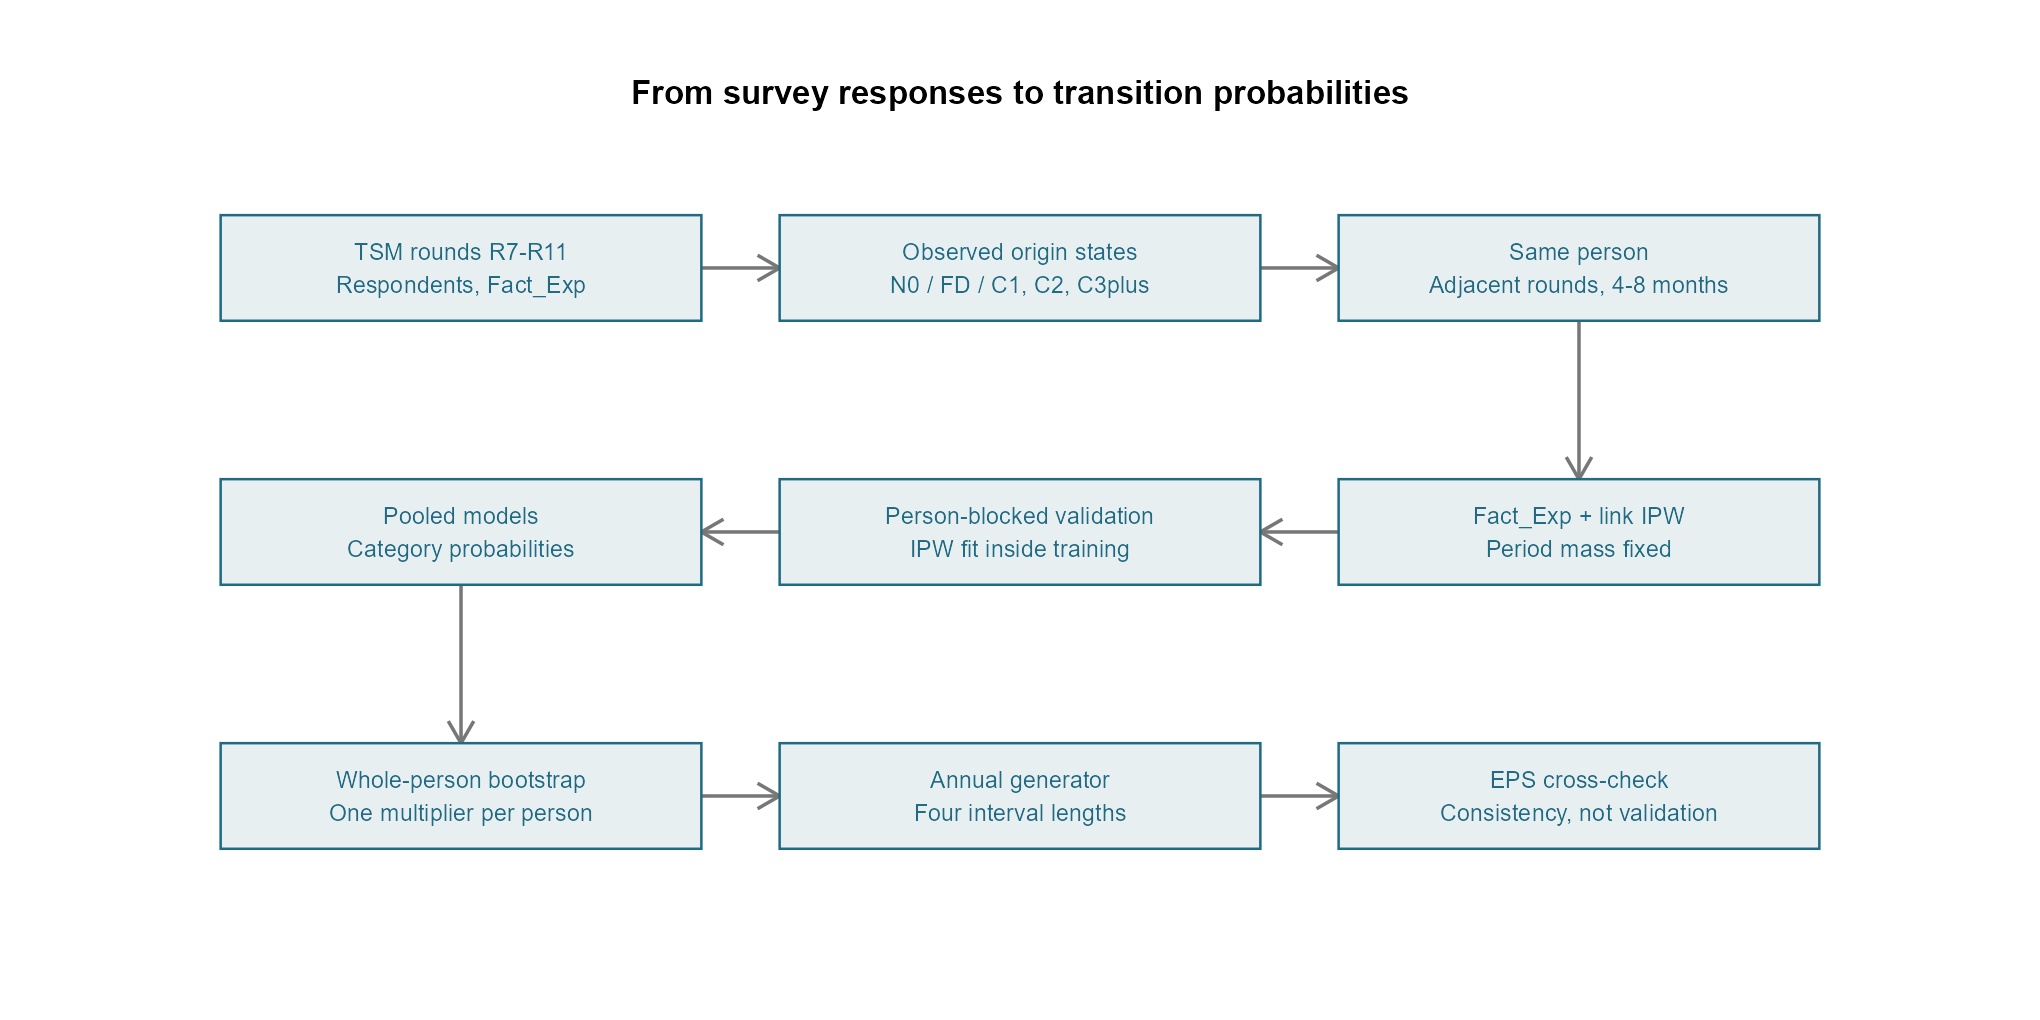

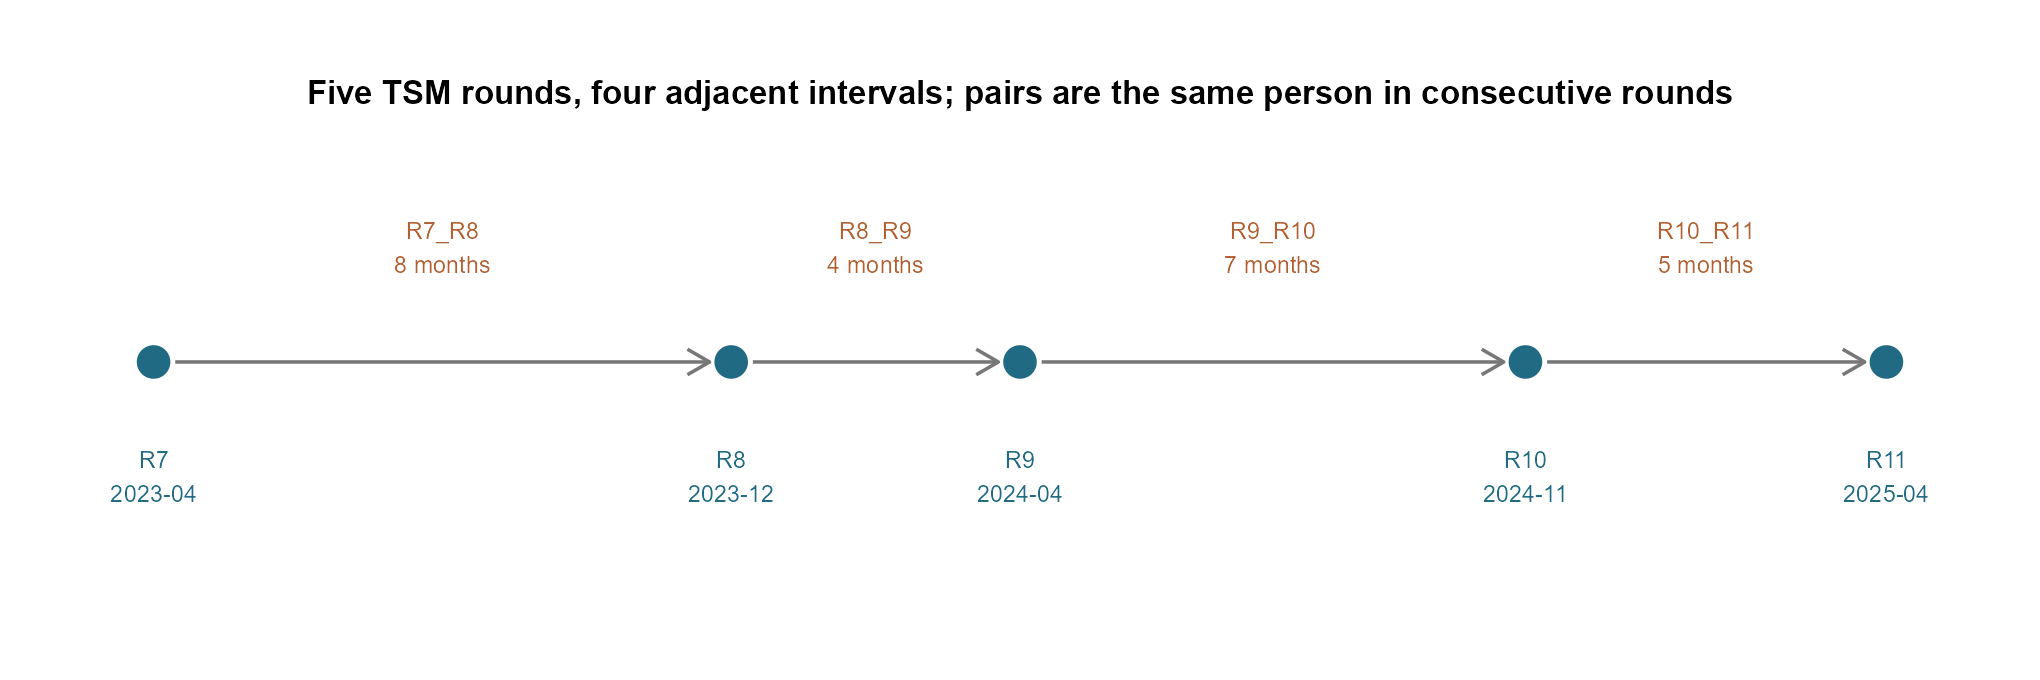

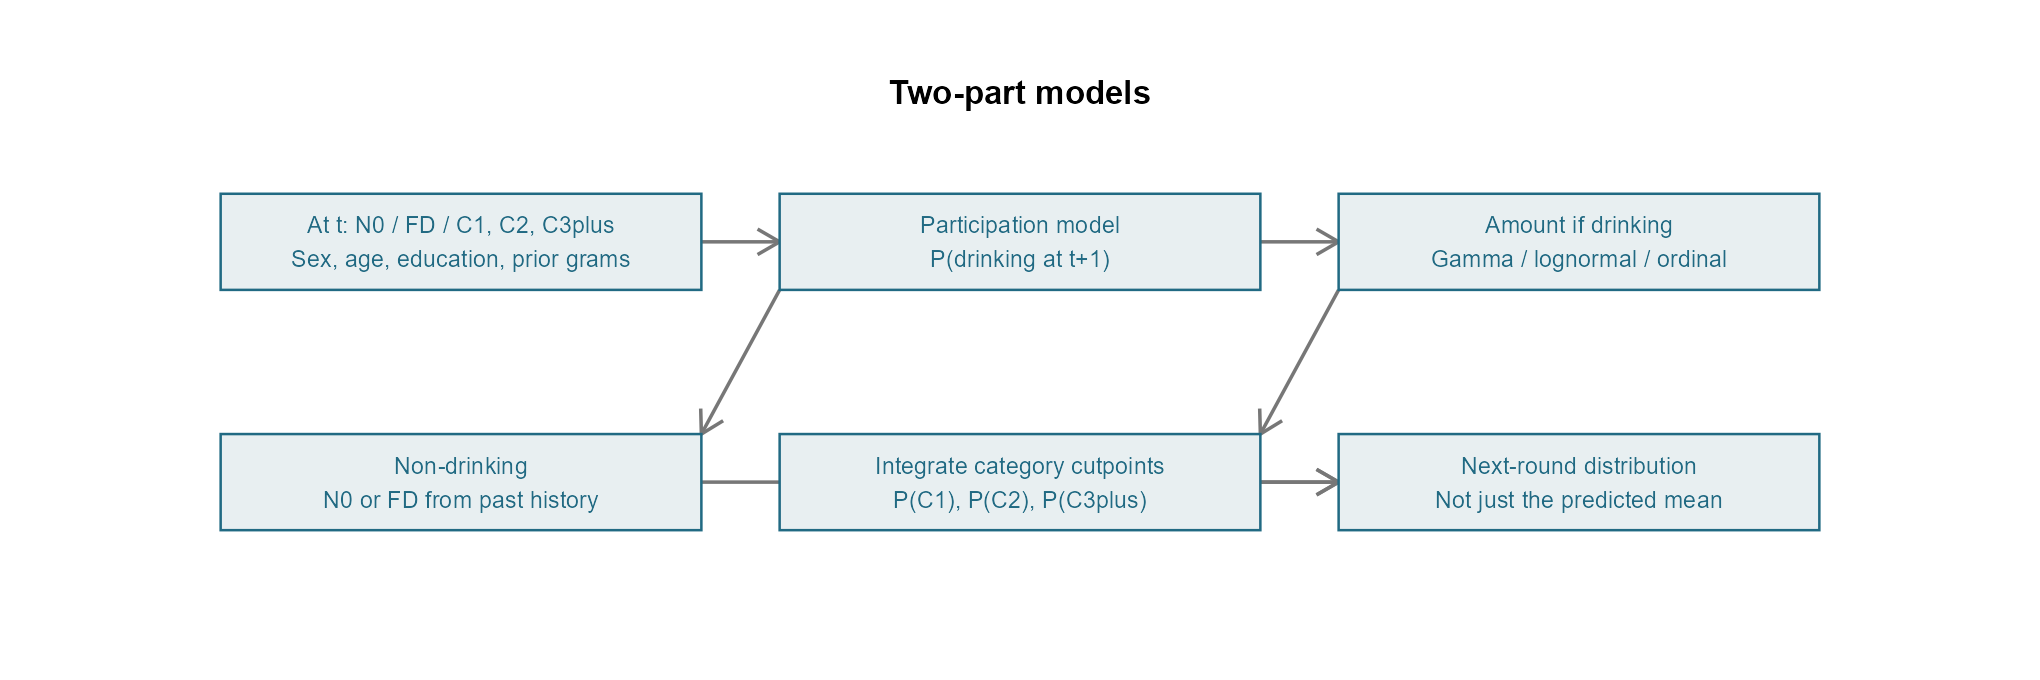

Elapsed: 0.16 minutes


In [19]:
#| label: tsm-data-design
.t0 <- Sys.time()
ts_load()
ts_W <- ts_waves(12)
ts_risk <- ts_make_risk(ts_W)
ts_period_mass <- vapply(ts_periods, function(p) sum(ts_risk$period == p & ts_risk$complete), 1)
names(ts_period_mass) <- ts_periods
ts_ip <- ts_ipw_fit(ts_risk)
ts_d <- ts_ipw_apply(ts_risk, ts_ip)
ts_check(nrow(ts_d) == length(unique(ts_d$row_id)), "One row per person and interval")
ts_check(all(ts_d$wn > 0) && all(is.finite(ts_d$wn)), "Positive finite main weights")
ts_check(!any(ts_d$state0 != "N0" & ts_d$state1 == "N0") && !any(ts_d$state0 == "N0" & ts_d$state1 == "FD"),
 "Observed pairs respect the history-state transition map")
ts_v2 <- ts_v2_regression(ts_W, ts_risk)
ts_save(ts_v2, "v2_regression_check")
ts_check(is.logical(ts_v2$match) && all(ts_v2$match), "v2 regression quantities match")
ts_link <- ts_link_audit(ts_W, ts_risk); ts_save(ts_link, "link_audit")
ts_link_evidence <- ts_link_tolerance_evidence(ts_W); ts_save(ts_link_evidence, "link_tolerance_evidence")
ts_check(identical(ts_link_evidence$compatible_at_tolerance[ts_link_evidence$same_sex & ts_link_evidence$years_outside_strict_bounds == as.character(ts_link_tolerance)],
 sum(ts_risk$compatible)), "Tolerance evidence matches the primary link count")
ts_counts <- as.data.frame(table(period = ts_d$period, sex = ts_d$sex, age_group = ts_d$age_group, state0 = ts_d$state0))
names(ts_counts)[5] <- "n"
ts_save(ts_counts, "row_counts_state0_by_stratum")
ts_cohort <- do.call(rbind, lapply(ts_periods, function(p) {
 r <- ts_risk[ts_risk$period == p, ]; d <- ts_d[ts_d$period == p, ]; tm <- ts_time[ts_time$period == p, ]
 data.frame(period = p, months = tm$months, years = tm$years, risk_set = nrow(r), destination_present = sum(r$destination_present),
   incompatible_links = sum(r$destination_present & !r$compatible), usable_pairs = nrow(d), persons = length(unique(d$id)),
   age_min = min(d$age), age_max = max(d$age), weight_ESS = sum(d$wn)^2 / sum(d$wn^2),
   main_weight = "Origin Fact_Exp + link IPW (stages a and c constant)")
}))
ts_hist_audit <- ts_history_audit(ts_W)
ts_edu_audit <- ts_education_audit(ts_W)
ts_harmonization <- do.call(rbind, lapply(split(ts_W, ts_W$wave), function(d)
 data.frame(wave = d$wave[1], respondents = nrow(d), aged_18_65 = sum(d$age >= 18 & d$age <= 65, na.rm = TRUE),
  current = sum(d$current %in% 1), N0 = sum(d$state %in% "N0"), FD = sum(d$state %in% "FD"),
  C1 = sum(d$cat %in% "C1"), C2 = sum(d$cat %in% "C2"), C3plus = sum(d$cat %in% "C3plus"),
  above_C4_cut = sum(d$current %in% 1 & d$grams > ifelse(d$sex == "Women", 60, 100)),
  signal_1 = sum(d$signal %in% 1), signal_0 = sum(d$signal %in% 0), hed6_1 = sum(d$hed6 %in% 1),
  grams_max = max(d$grams, na.rm = TRUE), prior_use = sum(d$prior_use %in% TRUE))))
ts_save(ts_cohort, "cohort"); ts_save(ts_hist_audit, "abstention_history_audit")
ts_save(ts_edu_audit, "education_rule_audit"); ts_save(ts_harmonization, "harmonization_audit")
ts_save(as.data.frame(table(origin = ts_d$state0)), "origin_counts")
ts_fd_tenure <- ts_fd_tenure_audit(ts_W); ts_save(ts_fd_tenure, "fd_tenure_audit")
ts_show(ts_cohort, "Adjacent-round analysis populations; months between rounds are approximate")
ts_show(data.frame(pairs = nrow(ts_d), persons = length(unique(ts_d$id)), persons_with_two_or_more_pairs = sum(table(ts_d$id) >= 2),
 persons_with_four_pairs = sum(table(ts_d$id) == 4)), "Pairs and distinct people")
ts_show(ts_v2, "Regression against version 2 before the link-compatibility rule")
ts_show(ts_link, "Link audit: destination records present, compatible and used")
ts_show(ts_link_evidence, "Why the tolerance is two years: education disagreement by years outside the strict EPS age bounds", 1)
ts_show(ts_hist_audit, "Past-only history flags by round; all available ages")
ts_show(ts_fd_tenure, "FD depends on panel tenure: non-drinkers by number of earlier interviews, and FD by months since the last observed drinking")
ts_show(ts_harmonization, "Harmonized wave table by round; counts only")
ts_diagrams()
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


## Weights and inverse probability weighting

The only released weight is the round-specific cross-sectional expansion factor `Fact_Exp`; there is no longitudinal weight, no primary sampling unit and no stratum. The origin weight is combined with the EPS three-stage inverse-probability correction. The three stages are the probability that the origin classification is observed, the probability that the destination record is linked given the origin, and the probability that the destination classification is observed given the link. In TSM the first and third stages are constant: every respondent in the risk set has a complete alcohol module at origin, and every compatible destination record has one too, so only the link stage is estimated. Its model uses the interval, origin state, sex, age group, education, log grams, the typical-quantity signal, the 6+ item, the depression screener, region, employment, partnership, home ownership, the number of earlier interviews and an indicator of entry after round 7.

Observation probabilities have a floor, completed weights are clipped at the training percentiles within each period, and each period keeps the mass of its observed complete pairs, so the pooled data are an analytical mixture of four weighted populations rather than one annual cohort. The link model and the clipping percentiles are learned inside every training fold and every bootstrap replicate, never on the held-out people; the probability floor is a fixed constant. Kish's effective sample size summarises weight dispersion and is not multiplied into any interval.


In [20]:
#| label: tsm-weight-audit
.t0 <- Sys.time()
ts_weight_audit <- do.call(rbind, lapply(split(ts_d, ts_d$period), function(d)
 data.frame(period = d$period[1], min_probability = min(d$p_obs), median_weight = stats::median(d$wn), max_weight = max(d$wn),
  clipped = sum(d$untrimmed != d$wcorrected), weight_ESS = sum(d$wn)^2 / sum(d$wn^2))))
ts_save(ts_weight_audit, "ipw_audit")
ts_kish <- do.call(rbind, lapply(split(ts_d, ts_key(ts_d, c("period", "sex"))), function(d)
 data.frame(period = d$period[1], sex = d$sex[1], n = nrow(d), weight_ESS = sum(d$wn)^2 / sum(d$wn^2),
  kish_design_effect = nrow(d) * sum(d$wn^2) / sum(d$wn)^2)))
# shortcut: the Kish table is displayed only (not in the plan's audit-table list); save it if a CSV is wanted.
ts_show(ts_weight_audit, "Weight diagnostics; ESS reflects weight dispersion only, no PSU or strata exist")
ts_show(ts_kish, "Kish effective sample size and design effect by period and sex; descriptive, not an interval multiplier")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


period,min_probability,median_weight,max_weight,clipped,weight_ESS
R7_R8,0.271,0.527,7.211,20,365.159
R8_R9,0.305,0.429,9.272,18,265.217
R9_R10,0.231,0.532,8.733,24,447.843
R10_R11,0.179,0.543,8.943,18,340.234


period,sex,n,weight_ESS,kish_design_effect
R10_R11,Men,335,141.955,2.360
R10_R11,Women,642,212.110,3.027
R7_R8,Men,331,136.087,2.432
R7_R8,Women,670,248.363,2.698
R8_R9,Men,301,101.278,2.972
R8_R9,Women,605,170.610,3.546
R9_R10,Men,455,185.988,2.446
R9_R10,Women,821,279.882,2.933


Elapsed: 0.00 minutes


## Models and fair comparison

The regression models receive the same information: previous state, log grams at origin for drinkers, sex, age group and their interaction, the interval and education. A uses only the origin-state cells by sex, age group and interval, and JRT_reference is the published specification without grams or education. The common right-hand side of the regression models is

$$
\text{state}_0 + \text{sex}\times\text{age group} + \text{period} + \log g_0 + \text{edu} + \text{edu missing}.
$$

| Model | What it does |
|---|---|
| A | Shrunken empirical matrix: cell counts borrow from sex, period and global margins; shrinkage strength tuned inside training. |
| A_education | The same matrix stratified additionally by education level. |
| Multinomial | Multinomial regression on the five destination classes. |
| Gamma | Two parts: participation at the next round, then a Gamma distribution of grams; class probabilities integrate the fitted distribution between the cutpoints. |
| Lognormal | Same two parts with a lognormal amount. |
| Ordinal_two_part | Participation, then a proportional-odds model over C1, C2 and C3plus. |
| NonPO_two_part | Participation, then a multinomial amount model, to test proportional odds through prediction. |
| Ordinal_single | One proportional-odds model over NC, C1, C2 and C3plus. |
| JRT_reference | The published JRT specification: state × age group, state × sex, sex × age group and period; no grams, no education. |
| Gamma_no_education, Gamma_education_interaction, Lognormal_education_interaction | Education removed or interacted with baseline drinking, sex and age. |
| Lognormal_tsm_extras | The common formula plus the TSM-only origin covariates (signal, 6+ item, depression screener, region, employment, history length). |

The main models compared in every table are A, Multinomial, Gamma, Lognormal, Ordinal_two_part, Ordinal_single and JRT_reference. The parametric amount models "share information" in the sense that a person's predicted distribution is informed by everyone with similar covariates, which allows a positive probability of C3plus even where no such destination was observed; the price is dependence on the assumed shape. Dispersion is estimated with normalised weights, so multiplying every weight by ten must leave the predictions unchanged, and this is checked.

**Log loss, in plain words.** Each model assigns a probability to the category that actually happened. Log loss is minus the logarithm of that probability, averaged over the observed pairs with their weights. Suppose three people are observed: the first stays in C1 and the model gave that outcome probability 0.8, the second moves to NC with probability 0.5, and the third moves to C3 with probability 0.1. Their individual losses are −log 0.8, −log 0.5 and −log 0.1, and the average is the log loss. Exponentiating minus the log loss returns the "typical probability" the model gave to what happened, a geometric mean that is easier to read than the loss itself. The Brier score instead sums squared differences between the probability vector and the observed indicator, and accuracy only asks whether the most probable class was the observed one. All three are computed on held-out people.

**Bootstrap versus cross-validation.** Cross-validation answers "how well does the model predict people it has not seen?": the people are split into five groups, each group is predicted by models trained on the other four, with IPW and shrinkage learned on the training part, and the split is repeated three times with different seeds. The bootstrap answers "how much would the estimates move if a different sample of people had been interviewed?": people are resampled with replacement, all pairs of a person move together, IPW and models are refitted, and the spread of the refitted estimates gives the interval. The first measures predictive quality, the second measures sampling uncertainty; neither replaces the other.

Paired contrasts are differences in log loss between two models on the same held-out pairs, with intervals that treat each person as a cluster; they are conditional on the fitted held-out predictions. Every pair among the main models is reported.


In [21]:
#| label: tsm-model-validation
.t0 <- Sys.time()
ts_tunes <- list(ts_tune(ts_risk, FALSE), ts_tune(ts_risk, TRUE))
ts_k <- vapply(ts_tunes, function(x) x$k, 1)
ts_save(rbind(ts_tunes[[1]]$scores, ts_tunes[[2]]$scores), "full_fit_shrinkage_tuning")
ts_fits <- lapply(stats::setNames(names(ts_models), names(ts_models)), function(nm) ts_fit(ts_d, nm, ts_k[if (nm == "A_education") 2 else 1]))
ts_scale_test <- lapply(c("Gamma", "Lognormal", "Multinomial", "Ordinal_two_part"), function(nm) {
 d <- ts_d; d$wn <- 10 * d$wn
 diff <- max(abs(ts_prob(ts_fits[[nm]], ts_d) - ts_prob(ts_fit(d, nm, ts_k[1]), ts_d)))
 ts_check(diff < 1e-7, paste("Weight-scale invariance", nm))
 data.frame(model = nm, max_absolute_difference = diff)
})
ts_save(do.call(rbind, ts_scale_test), "weight_scale_invariance")
ts_cv_result <- ts_cv(ts_risk)
ts_cvtab <- ts_cv_tables(ts_cv_result)
ts_contrasts <- ts_score_contrasts(ts_cvtab)
ts_save(ts_cv_result$audit, "CV_fold_audit"); ts_save(ts_cv_result$tuning, "CV_inner_tuning")
ts_save(ts_cvtab$scores, "CV_repeated_scores"); ts_save(ts_cvtab$summary, "cv_scores")
ts_save(ts_contrasts, "CV_paired_comparisons")
ts_show(ts_cvtab$summary, "Held-out category scores; lower log loss and Brier are better", 5)
ts_show(ts_contrasts[, 1:8], "Paired comparisons; intervals use person clusters, conditional on held-out predictions", 5)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


CV repeat 1/3, fold 1/5 complete
CV repeat 1/3, fold 2/5 complete
CV repeat 1/3, fold 3/5 complete
CV repeat 1/3, fold 4/5 complete
CV repeat 1/3, fold 5/5 complete
CV repeat 2/3, fold 1/5 complete
CV repeat 2/3, fold 2/5 complete
CV repeat 2/3, fold 3/5 complete
CV repeat 2/3, fold 4/5 complete
CV repeat 2/3, fold 5/5 complete
CV repeat 3/3, fold 1/5 complete
CV repeat 3/3, fold 2/5 complete
CV repeat 3/3, fold 3/5 complete
CV repeat 3/3, fold 4/5 complete
CV repeat 3/3, fold 5/5 complete


model,logloss,brier,accuracy
Lognormal,0.53957,0.33873,0.76590
Multinomial,0.54078,0.33865,0.76600
Lognormal_tsm_extras,0.54103,0.33928,0.76482
Ordinal_single,0.54106,0.33848,0.76617
NonPO_two_part,0.54227,0.33871,0.76536
Lognormal_education_interaction,0.54680,0.34400,0.76368
Gamma,0.54897,0.33878,0.76590
Ordinal_two_part,0.55081,0.33907,0.76586
Gamma_no_education,0.55261,0.34093,0.76677
Gamma_education_interaction,0.55837,0.34409,0.76366


model,reference,difference,se_person,lower,upper,relative_geometric_probability_gain_pct,mean_absolute_class_probability_change_pp
Lognormal,Gamma,-0.00940,0.00549,-0.02017,0.00137,0.94418,0.15438
Gamma,A,-0.01148,0.00986,-0.03081,0.00785,1.15453,4.09854
Lognormal,A,-0.02088,0.00733,-0.03526,-0.00649,2.10961,4.06176
NonPO_two_part,Ordinal_two_part,-0.00854,0.00398,-0.01635,-0.00073,0.85784,0.18432
Ordinal_two_part,Gamma,0.00184,0.00378,-0.00557,0.00924,-0.18357,0.21997
Ordinal_single,Gamma,-0.00792,0.00559,-0.01888,0.00304,0.79473,0.44184
Multinomial,Gamma,-0.00820,0.00633,-0.02061,0.00422,0.82290,0.33285
Multinomial,A,-0.01967,0.00744,-0.03427,-0.00508,1.98693,4.10080
Ordinal_two_part,A,-0.00964,0.00953,-0.02834,0.00906,0.96884,4.14605
Ordinal_single,A,-0.01940,0.00667,-0.03248,-0.00631,1.95844,3.98098


Elapsed: 1.36 minutes


## Calibration and the model decision

Calibration compares, for each destination class, the weighted share actually observed with the mean predicted probability, on held-out predictions. The same comparison is repeated within each origin cell, defined by origin state, sex and age group, so that a model that is right on average but wrong for a particular group can be seen; cells with few origin rows are flagged as sparse and should be read with that in mind.

The decision table records which model has the best average log loss and which has the best Brier score, and the paired contrast between Lognormal and A with its interval and its mean change in class probabilities. A contrast whose interval excludes zero separates the two scores clearly; one that includes zero does not, and a clear separation can still be small in practical terms.


In [22]:
#| label: tsm-calibration
.t0 <- Sys.time()
ts_cal <- do.call(rbind, lapply(c("A", "Gamma", "Lognormal", "Ordinal_two_part", "Ordinal_single", "Multinomial"), function(nm) {
 P <- ts_cvtab$prob[[nm]]
 data.frame(model = nm, category = ts_Y,
  observed = vapply(ts_Y, function(s) stats::weighted.mean(ts_d$y1 == s, ts_cvtab$w), 1),
  predicted = colSums(P * ts_cvtab$w) / sum(ts_cvtab$w))
}))
ts_save(ts_cal, "calibration_destination")
ts_show(ts_cal, "Held-out observed and predicted destination shares", 4)
ts_cal_cells <- ts_calibration_cells(ts_cvtab, ts_d)
ts_save(ts_cal_cells, "calibration_by_origin_cell")
ts_cal_show <- ts_cal_cells[!ts_cal_cells$sparse, ]
ts_show(utils::head(ts_cal_show[order(-abs(ts_cal_show$predicted - ts_cal_show$observed)), ], 15),
 "Largest held-out gaps among supported origin cells (n_origin of at least 30)", 4)
ts_la <- which(ts_contrasts$model == "Lognormal" & ts_contrasts$reference == "A")
stopifnot(length(ts_la) == 1)
ts_model_answer <- data.frame(best_logloss = ts_cvtab$summary$model[1],
 best_brier = ts_cvtab$summary$model[which.min(ts_cvtab$summary$brier)],
 lognormal_minus_A = ts_contrasts$difference[ts_la], lower = ts_contrasts$lower[ts_la], upper = ts_contrasts$upper[ts_la],
 mean_absolute_class_probability_change_pp = ts_contrasts$mean_absolute_class_probability_change_pp[ts_la],
 clear_lognormal_A_separation = ts_contrasts$lower[ts_la] > 0 | ts_contrasts$upper[ts_la] < 0)
ts_save(ts_model_answer, "model_decision_summary")
ts_show(ts_model_answer, "Current result, not a predetermined winner", 5)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


model,category,observed,predicted
A,NC,0.4366,0.4350
A,C1,0.5585,0.5599
A,C2,0.0040,0.0039
A,C3plus,0.0009,0.0012
Gamma,NC,0.4366,0.4372
Gamma,C1,0.5585,0.5606
Gamma,C2,0.0040,0.0018
Gamma,C3plus,0.0009,0.0004
Lognormal,NC,0.4366,0.4372
Lognormal,C1,0.5585,0.5578


model,state0,sex,age_group,destination,n_origin,observed,predicted,difference,absolute_difference,relative_difference,sparse
A,FD,Women,60-65,NC,82,0.7170,0.4415,-0.2755,0.2755,-0.3842,FALSE
A,FD,Women,60-65,C1,82,0.2830,0.5579,0.2749,0.2749,0.9716,FALSE
A,C1,Women,60-65,NC,201,0.4193,0.2310,-0.1883,0.1883,-0.4490,FALSE
A,C1,Women,60-65,C1,201,0.5807,0.7630,0.1823,0.1823,0.3139,FALSE
A,FD,Women,45-59,NC,132,0.6220,0.4416,-0.1804,0.1804,-0.2900,FALSE
A,FD,Women,45-59,C1,132,0.3780,0.5578,0.1798,0.1798,0.4755,FALSE
A,FD,Men,30-44,C1,30,0.7487,0.5792,-0.1695,0.1695,-0.2264,FALSE
A,FD,Men,30-44,NC,30,0.2513,0.4202,0.1689,0.1689,0.6720,FALSE
Multinomial,FD,Men,60-65,NC,37,0.5588,0.3941,-0.1647,0.1647,-0.2948,FALSE
Multinomial,FD,Men,60-65,C1,37,0.4412,0.6049,0.1637,0.1637,0.3711,FALSE


best_logloss,best_brier,lognormal_minus_A,lower,upper,mean_absolute_class_probability_change_pp,clear_lognormal_A_separation
Lognormal,Ordinal_single,-0.02088,-0.03526,-0.00649,4.06176,TRUE


Elapsed: 0.00 minutes


## Matrices and whole-person bootstrap intervals

Each matrix row averages the predicted probabilities among the people actually observed in that origin state, keeping their own grams and education. Rows without people are left empty and marked as unsupported; structural zeros, such as N0 to FD, are marked separately. Matrices are reported by period, sex and age group, pooled by sex and age group, pooled over everyone, and by education level. The pooled tables mix the four interval lengths, weighted by their pairs, so they are not probabilities over a defined horizon; the per-interval matrices are the primary TSM product.

Because TSM has no sampling design variables, the only uncertainty computed is the whole-person bootstrap: each replicate resamples people, applies the same multiplier to all pairs of a person, refits the link model, the weights and the outcome models, and recomputes every matrix and the annual generator. Intervals are built on the logit scale from the replicate standard deviation and are bounded at zero and one; rows unsupported in any replicate receive no interval rather than a fabricated one. Any failed replicate stops the inference. A stability table shows how the interval widths change with the number of replicates, and the Gamma and lognormal coefficients are exported with the same intervals.


In [23]:
#| label: tsm-person-inference
.t0 <- Sys.time()
ts_points <- ts_targets(ts_d, ts_fits[ts_main_models])
ts_pool_sexage <- do.call(rbind, lapply(ts_main_models, function(nm)
 ts_matrices(ts_d, ts_prob(ts_fits[[nm]], ts_d), nm, by = c("sex", "age_group"))))
ts_pool_tab <- do.call(rbind, lapply(ts_main_models, function(nm) {
 d <- ts_d; d$pooled <- "All"
 ts_matrices(d, ts_prob(ts_fits[[nm]], d), nm, by = "pooled")
}))
ts_edu_tab <- do.call(rbind, lapply(ts_main_models, function(nm) ts_matrices(ts_d, ts_prob(ts_fits[[nm]], ts_d), nm, by = "edu")))
ts_save(ts_edu_tab, "transition_matrices_education")
ts_show(ts_pool_tab[ts_pool_tab$from == ts_pool_tab$to & ts_pool_tab$model %in% c("A", "Gamma", "Lognormal"), c("model", "from", "n_origin", "estimate", "support")],
 "Pooled staying probabilities to the next round: a mixture of the four 4-8-month intervals weighted by their pairs; point estimates")
ts_ci_models <- c("A", "Gamma", "Lognormal", "Ordinal_single")
ts_person <- ts_bootstrap_person(model_names = ts_ci_models, annual = TRUE)
ts_person_ci <- function(tab) {
 keys <- names(ts_vector(tab))
 reps <- do.call(rbind, lapply(ts_person, function(x) x$target[keys]))
 ci <- cbind(tab, ts_interval(ts_vector(tab), reps))
 ci$interval_status[!ci$model %in% ts_ci_models] <- "not bootstrapped"
 ci
}
ts_ci <- ts_person_ci(ts_points)
ts_save(ts_ci, "transition_matrices_person_CI")
# The two pooled groupings carry different grouping columns; align them before binding.
ts_pool_ci <- ts_person_ci(ts_pool_sexage); ts_all_ci <- ts_person_ci(ts_pool_tab)
ts_pool_ci$pooled <- NA_character_; ts_all_ci$sex <- NA_character_; ts_all_ci$age_group <- NA_character_
ts_pool_ci <- rbind(ts_pool_ci, ts_all_ci[names(ts_pool_ci)])
ts_save(ts_pool_ci, "transition_matrices_pooled_person_CI")
ts_check(any(ts_pool_ci$interval_status == "available"), "Pooled person intervals available")
ts_personmat <- do.call(rbind, lapply(ts_person, function(x) x$target[names(ts_vector(ts_points[ts_points$model %in% ts_ci_models, ]))]))
ts_engine <- ts_coef(ts_fits)
ts_coef_names <- paste(ts_engine$model, ts_engine$component, ts_engine$term, sep = "::")
ts_engine <- cbind(ts_engine, ts_interval(ts_engine$estimate,
 do.call(rbind, lapply(ts_person, function(x) x$coefficients[ts_coef_names])), probability = FALSE))
ts_save(ts_engine, "engine_coefficients_person_CI")
ts_mc <- ts_bootstrap_stability(ts_personmat)
ts_save(ts_mc, "bootstrap_stability")
ts_show(ts_ci[ts_ci$model == "Gamma" & ts_ci$from == "C1" & ts_ci$to == "C1", c("period", "sex", "age_group", "n_origin", "estimate", "lower", "upper", "interval_status")],
 "Example: remaining in C1, Gamma model, whole-person bootstrap")
ts_show(ts_mc, "Bootstrap stability; whole-person replicates with IPW refitted")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


model,from,n_origin,estimate,support
A,N0,1613,0.795,observed
A,FD,432,0.432,observed
A,C1,2103,0.779,observed
A,C2,6,0.250,sparse
A,C3plus,6,0.012,sparse
Gamma,N0,1613,0.798,observed
Gamma,FD,432,0.434,observed
Gamma,C1,2103,0.778,observed
Gamma,C2,6,0.128,sparse
Gamma,C3plus,6,0.000,sparse


Person bootstrap 100/1000; IPW refitted
Person bootstrap 200/1000; IPW refitted
Person bootstrap 300/1000; IPW refitted
Person bootstrap 400/1000; IPW refitted
Person bootstrap 500/1000; IPW refitted
Person bootstrap 600/1000; IPW refitted
Person bootstrap 700/1000; IPW refitted
Person bootstrap 800/1000; IPW refitted
Person bootstrap 900/1000; IPW refitted
Person bootstrap 1000/1000; IPW refitted


period,sex,age_group,n_origin,estimate,lower,upper,interval_status
R10_R11,Men,18-29,23,0.798,0.665,0.888,available
R10_R11,Men,30-44,84,0.801,0.721,0.863,available
R10_R11,Men,45-59,73,0.755,0.655,0.834,available
R10_R11,Men,60-65,55,0.775,0.676,0.850,available
R10_R11,Women,18-29,35,0.790,0.679,0.870,available
R10_R11,Women,30-44,102,0.754,0.679,0.816,available
R10_R11,Women,45-59,104,0.635,0.545,0.716,available
R10_R11,Women,60-65,51,0.548,0.436,0.656,available
R7_R8,Men,18-29,37,0.826,0.720,0.897,available
R7_R8,Men,30-44,65,0.860,0.799,0.905,available


replicates,median_SE_ratio_to_1000,p90_absolute_relative_difference
100,0.980,0.209
250,0.993,0.127
500,0.994,0.074
1000,1.000,0.000


Elapsed: 37.78 minutes


## Transport, earlier history and rank matching

Transport trains the models on three intervals and tests on the fourth, with the test people removed from training, and repeats this for each interval; held-out rows borrow the period effect of the training interval closest in elapsed months, and the link weights of the held-out interval are fitted on training people only. It asks whether what is learned in some periods predicts another period of the same panel; it does not predict a future calendar period.

The history check uses pairs whose origin round has itself a compatible earlier round and compares models with and without the earlier state and grams. If adding the earlier state does not improve held-out prediction after adjustment, the data do not contradict the first-order Markov simplification; they do not prove it either. The Chapman–Kolmogorov diagnostic compares, on three-round cohorts with collapsed states, the direct two-step transition with the product of the two one-step matrices; it is a marginal composition check with a bootstrap interval, not a test.

Rank matching reproduces the margins of the observed panel within each sex and age group by coupling ranks instead of following individuals; comparing its matrix with the observed one shows how much persistence is created by the coupling itself.


In [24]:
#| label: tsm-transport-history
.t0 <- Sys.time()
ts_trans <- ts_transport(); ts_save(ts_trans$scores, "transport_scores"); ts_save(ts_trans$coverage, "transport_support")
ts_trans_text <- names(ts_trans$scores)[vapply(ts_trans$scores, function(v) is.character(v) || is.factor(v), TRUE)]
ts_transport_summary <- do.call(rbind, lapply(split(ts_trans$scores, ts_key(ts_trans$scores, ts_trans_text)), function(z)
 data.frame(z[1, ts_trans_text, drop = FALSE], logloss = stats::weighted.mean(z$logloss, z$weight_sum),
  brier = stats::weighted.mean(z$brier, z$weight_sum), n = sum(z$n), row.names = NULL)))
ts_save(ts_transport_summary, "transport_summary")
ts_show(ts_transport_summary, "Leave-one-interval-out transport; person-disjoint training and test", 4)
ts_hist <- ts_history_check(); ts_save(ts_hist, "adjusted_history_validation")
ts_show(ts_hist, "Does the state one round earlier add predictive information after adjustment?", 5)
ts_ck_tab <- ts_ck(); ts_save(ts_ck_tab, "chapman_kolmogorov_descriptive")
ts_rank_tab <- ts_rank(ts_d); ts_save(ts_rank_tab, "rank_matching_vs_panel")
ts_show(ts_rank_tab[ts_rank_tab$from == "C1" & ts_rank_tab$to == "C1", ],
 "C1 persistence: matched margins, different dependence", 3)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


held_out,proxy_period,model,logloss,brier,n
R10_R11,R8_R9,A,0.6044,0.3662,977
R10_R11,R8_R9,Gamma,0.5551,0.3400,977
R10_R11,R8_R9,JRT_reference,0.6003,0.3660,977
R10_R11,R8_R9,Lognormal,0.5490,0.3402,977
R10_R11,R8_R9,Multinomial,0.5489,0.3395,977
R10_R11,R8_R9,Ordinal_single,0.5606,0.3395,977
R10_R11,R8_R9,Ordinal_two_part,0.5479,0.3400,977
R7_R8,R9_R10,A,0.5487,0.3495,1001
R7_R8,R9_R10,Gamma,0.5133,0.3312,1001
R7_R8,R9_R10,JRT_reference,0.5418,0.3440,1001


model,n_pairs,n_persons,difference_history_minus_current,lower,upper,population
Gamma,2177,1164,0.00174,-0.02717,0.03064,pairs with a compatible earlier wave; person-cluster Taylor; conditional OOF comparison
Gamma_education_interaction,2177,1164,0.00534,-0.02460,0.03528,pairs with a compatible earlier wave; person-cluster Taylor; conditional OOF comparison


period,source,from,to,probability
R7_R8,Observed_panel,C1,C1,0.788
R7_R8,Rank_matching,C1,C1,0.935
R8_R9,Observed_panel,C1,C1,0.693
R8_R9,Rank_matching,C1,C1,0.854
R9_R10,Observed_panel,C1,C1,0.851
R9_R10,Rank_matching,C1,C1,1.000
R10_R11,Observed_panel,C1,C1,0.747
R10_R11,Rank_matching,C1,C1,0.906


Elapsed: 0.37 minutes


## Annual probabilities: an additional modelling layer

The four intervals have different lengths. A single continuous-time generator with non-negative off-diagonal rates is fitted to all four jointly, each with its elapsed years, and the annual matrix is its exponential:

$$
P(\Delta)=\exp(Q\Delta),\qquad P(1)=\exp(Q).
$$

**What the annual staying probability means.** Take two states, drinking and not drinking, and suppose the observed matrix over an interval of half a year shows that a drinker is still a drinker at the end with probability 0.9. The annual staying probability is not 0.9 squared, because during the year the person can leave and come back; the generator describes the rates of leaving and returning per unit time, and the annual matrix is what those rates produce over one year. At 12 g per drink C3plus has almost no origins, so its annual row rests on a handful of pairs (a row with no observed origin would be reported with a blank estimate and no interval). The rows that rest on few people are C2 and C3plus, flagged sparse: their annual probabilities are model-derived numbers that depend on the penalty and the starting values of the optimiser, and their bootstrap intervals are wide. The sensitivity table repeats the fit with a weak, a primary and a stronger penalty and reports the largest change in any annual probability; large changes keep this layer exploratory. Time-homogeneous rates are an assumption, and the four intervals test it: each interval is also fitted alone, and a table compares its reconstruction error and staying probabilities with the joint generator's. A joint error well above the single-interval errors means the intervals imply different rates, so the annual matrix is a compromise between them, and short windows turn within-year fluctuation of infrequent drinkers into annual exits. Annual intervals come from the bootstrap replicates and condition on the primary penalty and start.


In [25]:
#| label: tsm-annual-layer
.t0 <- Sys.time()
# Single start 0.05 as in EPS so the point estimate matches the bootstrap replicates; the three-start grid is in the sensitivity table.
ts_annual_full <- lapply(ts_fits[c("A", "Gamma", "Lognormal")], function(f) ts_annual(ts_d, f, starts = .05, check_gradient = TRUE))
ts_ann_point <- unlist(lapply(ts_annual_full, function(x) as.vector(x$P)))
ts_ann_rep <- do.call(rbind, lapply(ts_person, function(x) x$annual))
ts_ann <- do.call(rbind, lapply(names(ts_annual_full), function(nm) {
 z <- ts_annual_full[[nm]]
 ts_check(max(abs(rowSums(z$P) - 1)) < 1e-8 && min(z$P) > -1e-10, paste("Annual stochastic matrix", nm))
 ts_check(z$semigroup_error < 1e-8, paste("Annual semigroup", nm))
 data.frame(model = nm, from = rep(ts_ST, length(ts_ST)), to = rep(ts_ST, each = length(ts_ST)), estimate = as.vector(z$P),
  weighted_reconstruction_RMSE = z$rmse, optimizer_code = z$convergence, gradient_error = z$gradient_error, semigroup_error = z$semigroup_error)
}))
ts_ann <- cbind(ts_ann, ts_interval(ts_ann_point, ts_ann_rep))
# Rows whose origin state has no observed pairs are penalty-driven, not estimated: report them as unsupported.
ts_ann_support <- function(tab, d) {
 n0 <- table(factor(as.character(d$state0), levels = unique(tab$from)))
 tab$n_origin <- as.integer(n0[as.character(tab$from)])
 tab$support <- ifelse(tab$n_origin == 0, "unobserved origin", ifelse(tab$n_origin < 30, "sparse", "observed"))
 bad <- tab$n_origin == 0
 for (v in intersect(c("estimate", "se", "lower", "upper"), names(tab))) tab[[v]][bad] <- NA_real_
 if ("interval_status" %in% names(tab)) tab$interval_status[bad] <- "unobserved origin"
 tab
}
ts_ann <- ts_ann_support(ts_ann, ts_d)
ts_save(ts_ann, "annual_pooled_matrices_person_CI")
ts_ann_sens <- do.call(rbind, lapply(c("A", "Gamma", "Lognormal"), function(nm) do.call(rbind, lapply(c(1e-5, 5e-5, 2e-4), function(pen) {
 z <- ts_annual(ts_d, ts_fits[[nm]], lambda = pen)
 data.frame(model = nm, penalty = pen, weighted_reconstruction_RMSE = z$rmse, start_objective_range = z$start_objective_range,
  max_annual_difference = max(abs(z$P - ts_annual_full[[nm]]$P)), optimizer_code = z$convergence)
}))))
ts_save(ts_ann_sens, "annual_generator_sensitivity")
# Time-homogeneity check: each interval fitted alone (primary penalty and start) against the joint generator.
ts_ann_intervals <- do.call(rbind, lapply(c("A", "Gamma", "Lognormal"), function(nm) do.call(rbind, lapply(ts_periods, function(p) {
 ii <- ts_d$period == p; z <- ts_annual(ts_d[ii, ], ts_fits[[nm]], starts = .05)
 P <- ts_prob(ts_fits[[nm]], ts_d[ii, ]); yrs <- ts_time$years[match(p, ts_time$period)]
 pj <- ts_expm(ts_annual_full[[nm]]$Q * yrs); pj5 <- cbind(pj[, 1] + pj[, 2], pj[, 3:ncol(pj)])
 err <- 0; mass <- 0
 for (s in seq_along(ts_ST)) { jj <- as.character(ts_d$state0[ii]) == ts_ST[s]; if (any(jj)) {
  target <- colSums(P[jj, , drop = FALSE] * ts_d$wn[ii][jj]) / sum(ts_d$wn[ii][jj])
  err <- err + sum(ts_d$wn[ii][jj]) * sum((pj5[s, ] - target)^2); mass <- mass + sum(ts_d$wn[ii][jj]) } }
 data.frame(model = nm, period = p, years = yrs, single_fit_RMSE = z$rmse, joint_fit_within_interval_RMSE = sqrt(err / mass),
  single_fit_annual_stay_N0 = z$P[1, 1], single_fit_annual_stay_FD = z$P[2, 2], single_fit_annual_stay_C1 = z$P[3, 3],
  joint_annual_stay_N0 = ts_annual_full[[nm]]$P[1, 1], joint_annual_stay_FD = ts_annual_full[[nm]]$P[2, 2],
  joint_annual_stay_C1 = ts_annual_full[[nm]]$P[3, 3], optimizer_code = z$convergence)
}))))
ts_save(ts_ann_intervals, "annual_interval_fits")
ts_show(ts_ann[ts_ann$from == ts_ann$to, c("model", "from", "to", "n_origin", "support", "estimate", "lower", "upper", "interval_status")],
 "Annual staying probabilities: model-derived, pooled; whole-person bootstrap intervals; unobserved origins are not estimated")
ts_show(ts_ann_sens, "Annual reconstruction sensitivity to penalty and restarts", 5)
ts_show(ts_ann_intervals[, c("model", "period", "years", "single_fit_RMSE", "joint_fit_within_interval_RMSE",
 "single_fit_annual_stay_N0", "joint_annual_stay_N0", "single_fit_annual_stay_C1", "joint_annual_stay_C1")],
 "Each interval fitted alone versus the joint generator: a time-homogeneity check; C2 and C3plus rows are not shown because they are penalty-driven", 4)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


model,from,to,n_origin,support,estimate,lower,upper,interval_status
A,N0,N0,1613,observed,0.590,0.515,0.661,available
A,FD,FD,432,observed,0.276,0.230,0.329,available
A,C1,C1,2103,observed,0.738,0.702,0.771,available
A,C2,C2,6,sparse,0.043,0.000,0.992,available
A,C3plus,C3plus,6,sparse,0.007,0.000,1.000,available
Gamma,N0,N0,1613,observed,0.589,0.515,0.660,available
Gamma,FD,FD,432,observed,0.276,0.231,0.325,available
Gamma,C1,C1,2103,observed,0.740,0.705,0.772,available
Gamma,C2,C2,6,sparse,0.010,0.000,1.000,available
Gamma,C3plus,C3plus,6,sparse,0.006,0.000,1.000,available


model,penalty,weighted_reconstruction_RMSE,start_objective_range,max_annual_difference,optimizer_code
A,1e-05,0.06327,0.00034,0.01027,0
A,5e-05,0.06324,0.00000,0.00226,0
A,2e-04,0.06367,0.00001,0.03079,0
Gamma,1e-05,0.07542,0.00009,0.00298,0
Gamma,5e-05,0.07554,0.00000,0.00075,0
Gamma,2e-04,0.07587,0.00000,0.01197,0
Lognormal,1e-05,0.07473,0.00014,0.00100,0
Lognormal,5e-05,0.07481,0.00000,0.00000,0
Lognormal,2e-04,0.07508,0.00000,0.01838,0


model,period,years,single_fit_RMSE,joint_fit_within_interval_RMSE,single_fit_annual_stay_N0,joint_annual_stay_N0,single_fit_annual_stay_C1,joint_annual_stay_C1
A,R7_R8,0.6667,0.0095,0.0417,0.6531,0.5901,0.7000,0.7382
A,R8_R9,0.3333,0.0051,0.0905,0.4644,0.5901,0.6727,0.7382
A,R9_R10,0.5833,0.0075,0.0707,0.6061,0.5901,0.7822,0.7382
A,R10_R11,0.4167,0.0086,0.0334,0.5631,0.5901,0.7044,0.7382
Gamma,R7_R8,0.6667,0.0117,0.0555,0.6555,0.5895,0.7232,0.7396
Gamma,R8_R9,0.3333,0.0163,0.1131,0.5297,0.5895,0.6178,0.7396
Gamma,R9_R10,0.5833,0.0072,0.0710,0.5667,0.5895,0.8028,0.7396
Gamma,R10_R11,0.4167,0.0113,0.0519,0.6043,0.5895,0.6836,0.7396
Lognormal,R7_R8,0.6667,0.0118,0.0556,0.6547,0.5883,0.7193,0.7361
Lognormal,R8_R9,0.3333,0.0162,0.1119,0.5298,0.5883,0.6155,0.7361


Elapsed: 0.13 minutes


## Cross-check against EPS

The EPS notebook exports annual matrices for A, Gamma and Lognormal with design-based intervals, and the observed-origin matrices of its two intervals. Three comparisons are made with aggregates only. First, the annual staying probabilities of the two panels are placed side by side, each with its own interval. Second, a generator is recovered from each EPS annual matrix, projected to the TSM interval lengths and scored on the observed TSM pairs, next to the TSM models' in-sample and held-out scores and an origin-only TSM matrix, which is the like-for-like reference because the EPS projection also conditions on the origin state alone. Third, the TSM generator is projected to the EPS interval lengths and compared with the EPS observed-origin pooled matrices on the four collapsed destinations; the FD origin is flagged as not comparable, because TSM FD and EPS FD are different constructs. The EPS version 1 matrices keep C3 and C4 apart, so they are merged first: destination columns are summed and the two origin rows are averaged with the observed EPS origin pairs as weights. This is an approximation for the annual matrices, and the merged EPS cells carry no interval.

This is external consistency, not validation. The populations differ, the periods differ, the instruments differ in wording and recall window, and the TSM intervals are months while the EPS intervals are years, so agreement does not establish that either engine is right and disagreement does not identify which one is wrong.


In [26]:
#| label: tsm-eps-crosscheck
.t0 <- Sys.time()
ts_cross <- ts_crosscheck_eps(ts_d, ts_fits, ts_annual_full, cvtab = ts_cvtab, annual_ci = ts_ann)
ts_unobserved <- names(which(table(factor(as.character(ts_d$state0), levels = ts_ST)) == 0))
ts_j <- match(paste(ts_cross$annual$model, ts_cross$annual$from), paste(ts_ann$model, ts_ann$from))
ts_cross$annual$n_origin <- ifelse(ts_cross$annual$source == "TSM", ts_ann$n_origin[ts_j], NA_integer_)
ts_cross$annual$support <- ifelse(ts_cross$annual$source == "TSM", ts_ann$support[ts_j], "EPS")
ts_cross$annual$comparable <- ts_cross$annual$from != "FD"   # TSM FD drank months earlier; EPS FD abstained for years
ts_bad <- ts_cross$annual$source == "TSM" & ts_cross$annual$from %in% ts_unobserved
ts_cross$annual$estimate[ts_bad] <- NA_real_; ts_cross$annual$lower[ts_bad] <- NA_real_; ts_cross$annual$upper[ts_bad] <- NA_real_
# Origin-only TSM baseline: the EPS projection also conditions on the origin state alone, so this is its like-for-like reference.
ts_origin_only <- local({
 w <- ts_d$wn; m <- tapply(w, list(factor(as.character(ts_d$state0), levels = ts_ST), ts_d$y1), sum); m[is.na(m)] <- 0
 m <- m / rowSums(m); m[!is.finite(m)] <- 0
 P <- m[as.character(ts_d$state0), , drop = FALSE]; loss <- ts_loss(P, ts_d$y1)
 one <- function(ii, label) data.frame(source = "TSM_origin_only_insample", model = "origin_only", period = label,
  logloss = stats::weighted.mean(loss$logloss[ii], w[ii]), brier = stats::weighted.mean(loss$brier[ii], w[ii]), n = length(ii), recovery_rmse = NA_real_)
 rbind(one(seq_len(nrow(ts_d)), "All"), do.call(rbind, lapply(ts_periods, function(p) one(which(ts_d$period == p), p))))
})
ts_cross$projection_eps_to_tsm <- rbind(ts_cross$projection_eps_to_tsm, ts_origin_only)
ts_save(ts_cross$annual, "eps_crosscheck_annual")
ts_save(ts_cross$projection_eps_to_tsm, "eps_crosscheck_projection_eps_to_tsm")
ts_save(ts_cross$projection_eps_matrices, "eps_crosscheck_projection_eps_matrices")
ts_save(ts_cross$projection_tsm_to_eps, "eps_crosscheck_projection_tsm_to_eps")
ts_save(ts_cross$projection_tsm_to_eps_summary, "eps_crosscheck_projection_tsm_to_eps_summary")
ts_show(ts_cross$annual[ts_cross$annual$from == ts_cross$annual$to, ],
 "Annual staying probabilities, TSM and EPS, each with its own interval; external consistency, not validation")
ts_show(ts_cross$projection_eps_to_tsm, "EPS generators projected to the TSM intervals and scored on TSM pairs, next to the TSM models", 4)
ts_show(ts_cross$projection_tsm_to_eps_summary, "TSM generators projected to the EPS interval lengths versus the EPS observed-origin pooled matrices", 4)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


source,model,from,to,estimate,lower,upper,staying,n_origin,support,comparable
TSM,A,N0,N0,0.590,0.515,0.661,TRUE,1613,observed,TRUE
TSM,A,FD,FD,0.276,0.230,0.329,TRUE,432,observed,FALSE
TSM,A,C1,C1,0.738,0.702,0.771,TRUE,2103,observed,TRUE
TSM,A,C2,C2,0.043,0.000,0.992,TRUE,6,sparse,TRUE
TSM,A,C3plus,C3plus,0.007,0.000,1.000,TRUE,6,sparse,TRUE
EPS,A,N0,N0,0.913,0.903,0.922,TRUE,NA,EPS,TRUE
EPS,A,FD,FD,0.869,0.822,0.905,TRUE,NA,EPS,FALSE
EPS,A,C1,C1,0.819,0.793,0.841,TRUE,NA,EPS,TRUE
EPS,A,C2,C2,0.524,0.346,0.696,TRUE,NA,EPS,TRUE
EPS,A,C3plus,C3plus,0.499,NA,NA,TRUE,NA,EPS,TRUE


source,model,period,logloss,brier,n,recovery_rmse
EPS_projection,A,All,0.7645,0.4351,4160,0.0034
EPS_projection,A,R7_R8,0.6642,0.3882,1001,0.0034
EPS_projection,A,R8_R9,0.8980,0.4946,906,0.0034
EPS_projection,A,R9_R10,0.7166,0.4132,1276,0.0034
EPS_projection,A,R10_R11,0.8061,0.4567,977,0.0034
EPS_projection,Gamma,All,0.7616,0.4334,4160,0.0043
EPS_projection,Gamma,R7_R8,0.6603,0.3851,1001,0.0043
EPS_projection,Gamma,R8_R9,0.8949,0.4933,906,0.0043
EPS_projection,Gamma,R9_R10,0.7151,0.4118,1276,0.0043
EPS_projection,Gamma,R10_R11,0.8023,0.4555,977,0.0043


model,eps_period,years,cells_included,cells,weighted_RMSE,max_absolute_difference
A,VI_VII,3.671,supported origins,16,0.2235,0.3909
A,VII_VIII,4.030,supported origins,20,0.2921,0.5229
Gamma,VI_VII,3.671,supported origins,16,0.2244,0.3925
Gamma,VII_VIII,4.030,supported origins,20,0.2930,0.5242
Lognormal,VI_VII,3.671,supported origins,16,0.2236,0.3904
Lognormal,VII_VIII,4.030,supported origins,20,0.2920,0.5241
A,VI_VII,3.671,excluding FD origin,16,0.2235,0.3909
A,VII_VIII,4.030,excluding FD origin,16,0.2923,0.5229
Gamma,VI_VII,3.671,excluding FD origin,16,0.2244,0.3925
Gamma,VII_VIII,4.030,excluding FD origin,16,0.2932,0.5242


Elapsed: 0.01 minutes


## Sensitivities

Conversion: every main model is refitted at 15.7 g per drink, and the pooled matrices at that conversion are exported; the difference measures how much classification depends on drink size and does not say which size is correct. Upper band: the open "ten or more" band is set to sixteen drinks instead of ten. Weights: base weights alone, base weights trimmed at the same percentiles, untrimmed IPW weights and the primary trimmed IPW weights, so the inverse-probability correction is separated from the trimming. Education: the strict and reached rules replace the lenient one, with cross-validated scores for A and Lognormal and pooled matrices. Link rule: the strict EPS age bounds replace the primary widened bounds, for destination links and for the history chain, with their own link audit, the pairs retained, cross-validated scores and pooled matrices. Typical-quantity signal: its weighted share by destination category and a person-clustered regression on destination, sex, age group, origin signal and period; the 6+ item is tabulated by destination category and by origin state.


CV repeat 1/1, fold 1/5 complete
CV repeat 1/1, fold 2/5 complete
CV repeat 1/1, fold 3/5 complete
CV repeat 1/1, fold 4/5 complete
CV repeat 1/1, fold 5/5 complete
CV repeat 1/1, fold 1/5 complete
CV repeat 1/1, fold 2/5 complete
CV repeat 1/1, fold 3/5 complete
CV repeat 1/1, fold 4/5 complete
CV repeat 1/1, fold 5/5 complete
CV repeat 1/1, fold 1/5 complete
CV repeat 1/1, fold 2/5 complete
CV repeat 1/1, fold 3/5 complete
CV repeat 1/1, fold 4/5 complete
CV repeat 1/1, fold 5/5 complete


CV repeat 1/1, fold 1/5 complete
CV repeat 1/1, fold 2/5 complete
CV repeat 1/1, fold 3/5 complete
CV repeat 1/1, fold 4/5 complete
CV repeat 1/1, fold 5/5 complete
CV repeat 1/1, fold 1/5 complete
CV repeat 1/1, fold 2/5 complete
CV repeat 1/1, fold 3/5 complete
CV repeat 1/1, fold 4/5 complete
CV repeat 1/1, fold 5/5 complete


grams_per_drink,model,quantity,probability
12.0,A,Drinking_t1,0.5646
12.0,A,Escalation_from_C1,0.0065
12.0,A,C3_C4_t1,0.0010
12.0,Multinomial,Drinking_t1,0.5623
12.0,Multinomial,Escalation_from_C1,0.0062
12.0,Multinomial,C3_C4_t1,0.0011
12.0,Gamma,Drinking_t1,0.5617
12.0,Gamma,Escalation_from_C1,0.0037
12.0,Gamma,C3_C4_t1,0.0004
12.0,Lognormal,Drinking_t1,0.5617


scenario,model,quantity,probability
top_16_drinks,A,Drinking_t1,0.5646
top_16_drinks,A,Escalation_from_C1,0.0065
top_16_drinks,A,C3_C4_t1,0.0017
top_16_drinks,Gamma,Drinking_t1,0.5617
top_16_drinks,Gamma,Escalation_from_C1,0.0041
top_16_drinks,Gamma,C3_C4_t1,0.0005
top_16_drinks,Lognormal,Drinking_t1,0.5617
top_16_drinks,Lognormal,Escalation_from_C1,0.0084
top_16_drinks,Lognormal,C3_C4_t1,0.0018


scenario,current_t1,C3_C4_t1,weight_ESS
base_only,0.5648,5e-04,1194.824
base_trimmed,0.5652,4e-04,1510.319
IPW_untrimmed,0.5589,6e-04,1130.859
base_plus_IPW,0.5617,4e-04,1409.241


rule,model,quantity,probability
lenient,A,Drinking_t1,0.5646
lenient,A,Escalation_from_C1,0.0065
lenient,A,C3_C4_t1,0.0010
lenient,Lognormal,Drinking_t1,0.5617
lenient,Lognormal,Escalation_from_C1,0.0082
lenient,Lognormal,C3_C4_t1,0.0018
strict,A,Drinking_t1,0.5644
strict,A,Escalation_from_C1,0.0065
strict,A,C3_C4_t1,0.0010
strict,Lognormal,Drinking_t1,0.5616


variant,model,logloss,brier,accuracy,pairs,persons
lenient,Lognormal,0.54205,0.33954,0.76394,4160,1931
lenient,A,0.56033,0.35238,0.76555,4160,1931
strict,Lognormal,0.54207,0.33999,0.76328,4160,1931
strict,A,0.55994,0.35217,0.76574,4160,1931
reached,Lognormal,0.54215,0.33920,0.76298,4160,1931
reached,A,0.56032,0.35275,0.76521,4160,1931


variant,model,logloss,brier,accuracy,pairs,persons
primary_bounds_tolerance_2,Lognormal,0.54205,0.33954,0.76394,4160,1931
primary_bounds_tolerance_2,A,0.56033,0.35238,0.76555,4160,1931
strict_EPS_bounds,Lognormal,0.52766,0.33110,0.76928,3888,1845
strict_EPS_bounds,A,0.54621,0.34268,0.77193,3888,1845


variant,model,quantity,probability
primary_bounds_tolerance_2,A,Drinking_t1,0.5646
primary_bounds_tolerance_2,A,Escalation_from_C1,0.0065
primary_bounds_tolerance_2,A,C3_C4_t1,0.0010
primary_bounds_tolerance_2,Lognormal,Drinking_t1,0.5617
primary_bounds_tolerance_2,Lognormal,Escalation_from_C1,0.0082
primary_bounds_tolerance_2,Lognormal,C3_C4_t1,0.0018
strict_EPS_bounds,A,Drinking_t1,0.5647
strict_EPS_bounds,A,Escalation_from_C1,0.0070
strict_EPS_bounds,A,C3_C4_t1,0.0007
strict_EPS_bounds,Lognormal,Drinking_t1,0.5618


level,category,sex,n,share_hed6
destination,C1,Men,922,0.377
destination,C1,Women,1143,0.214
destination,C2,Men,5,0.393
destination,C2,Women,9,0.826
destination,C3plus,Men,2,1.000
destination,C3plus,Women,1,1.000
destination,NC,Men,493,0.000
destination,NC,Women,1585,0.000
origin,N0,All,1613,0.000
origin,FD,All,432,0.000


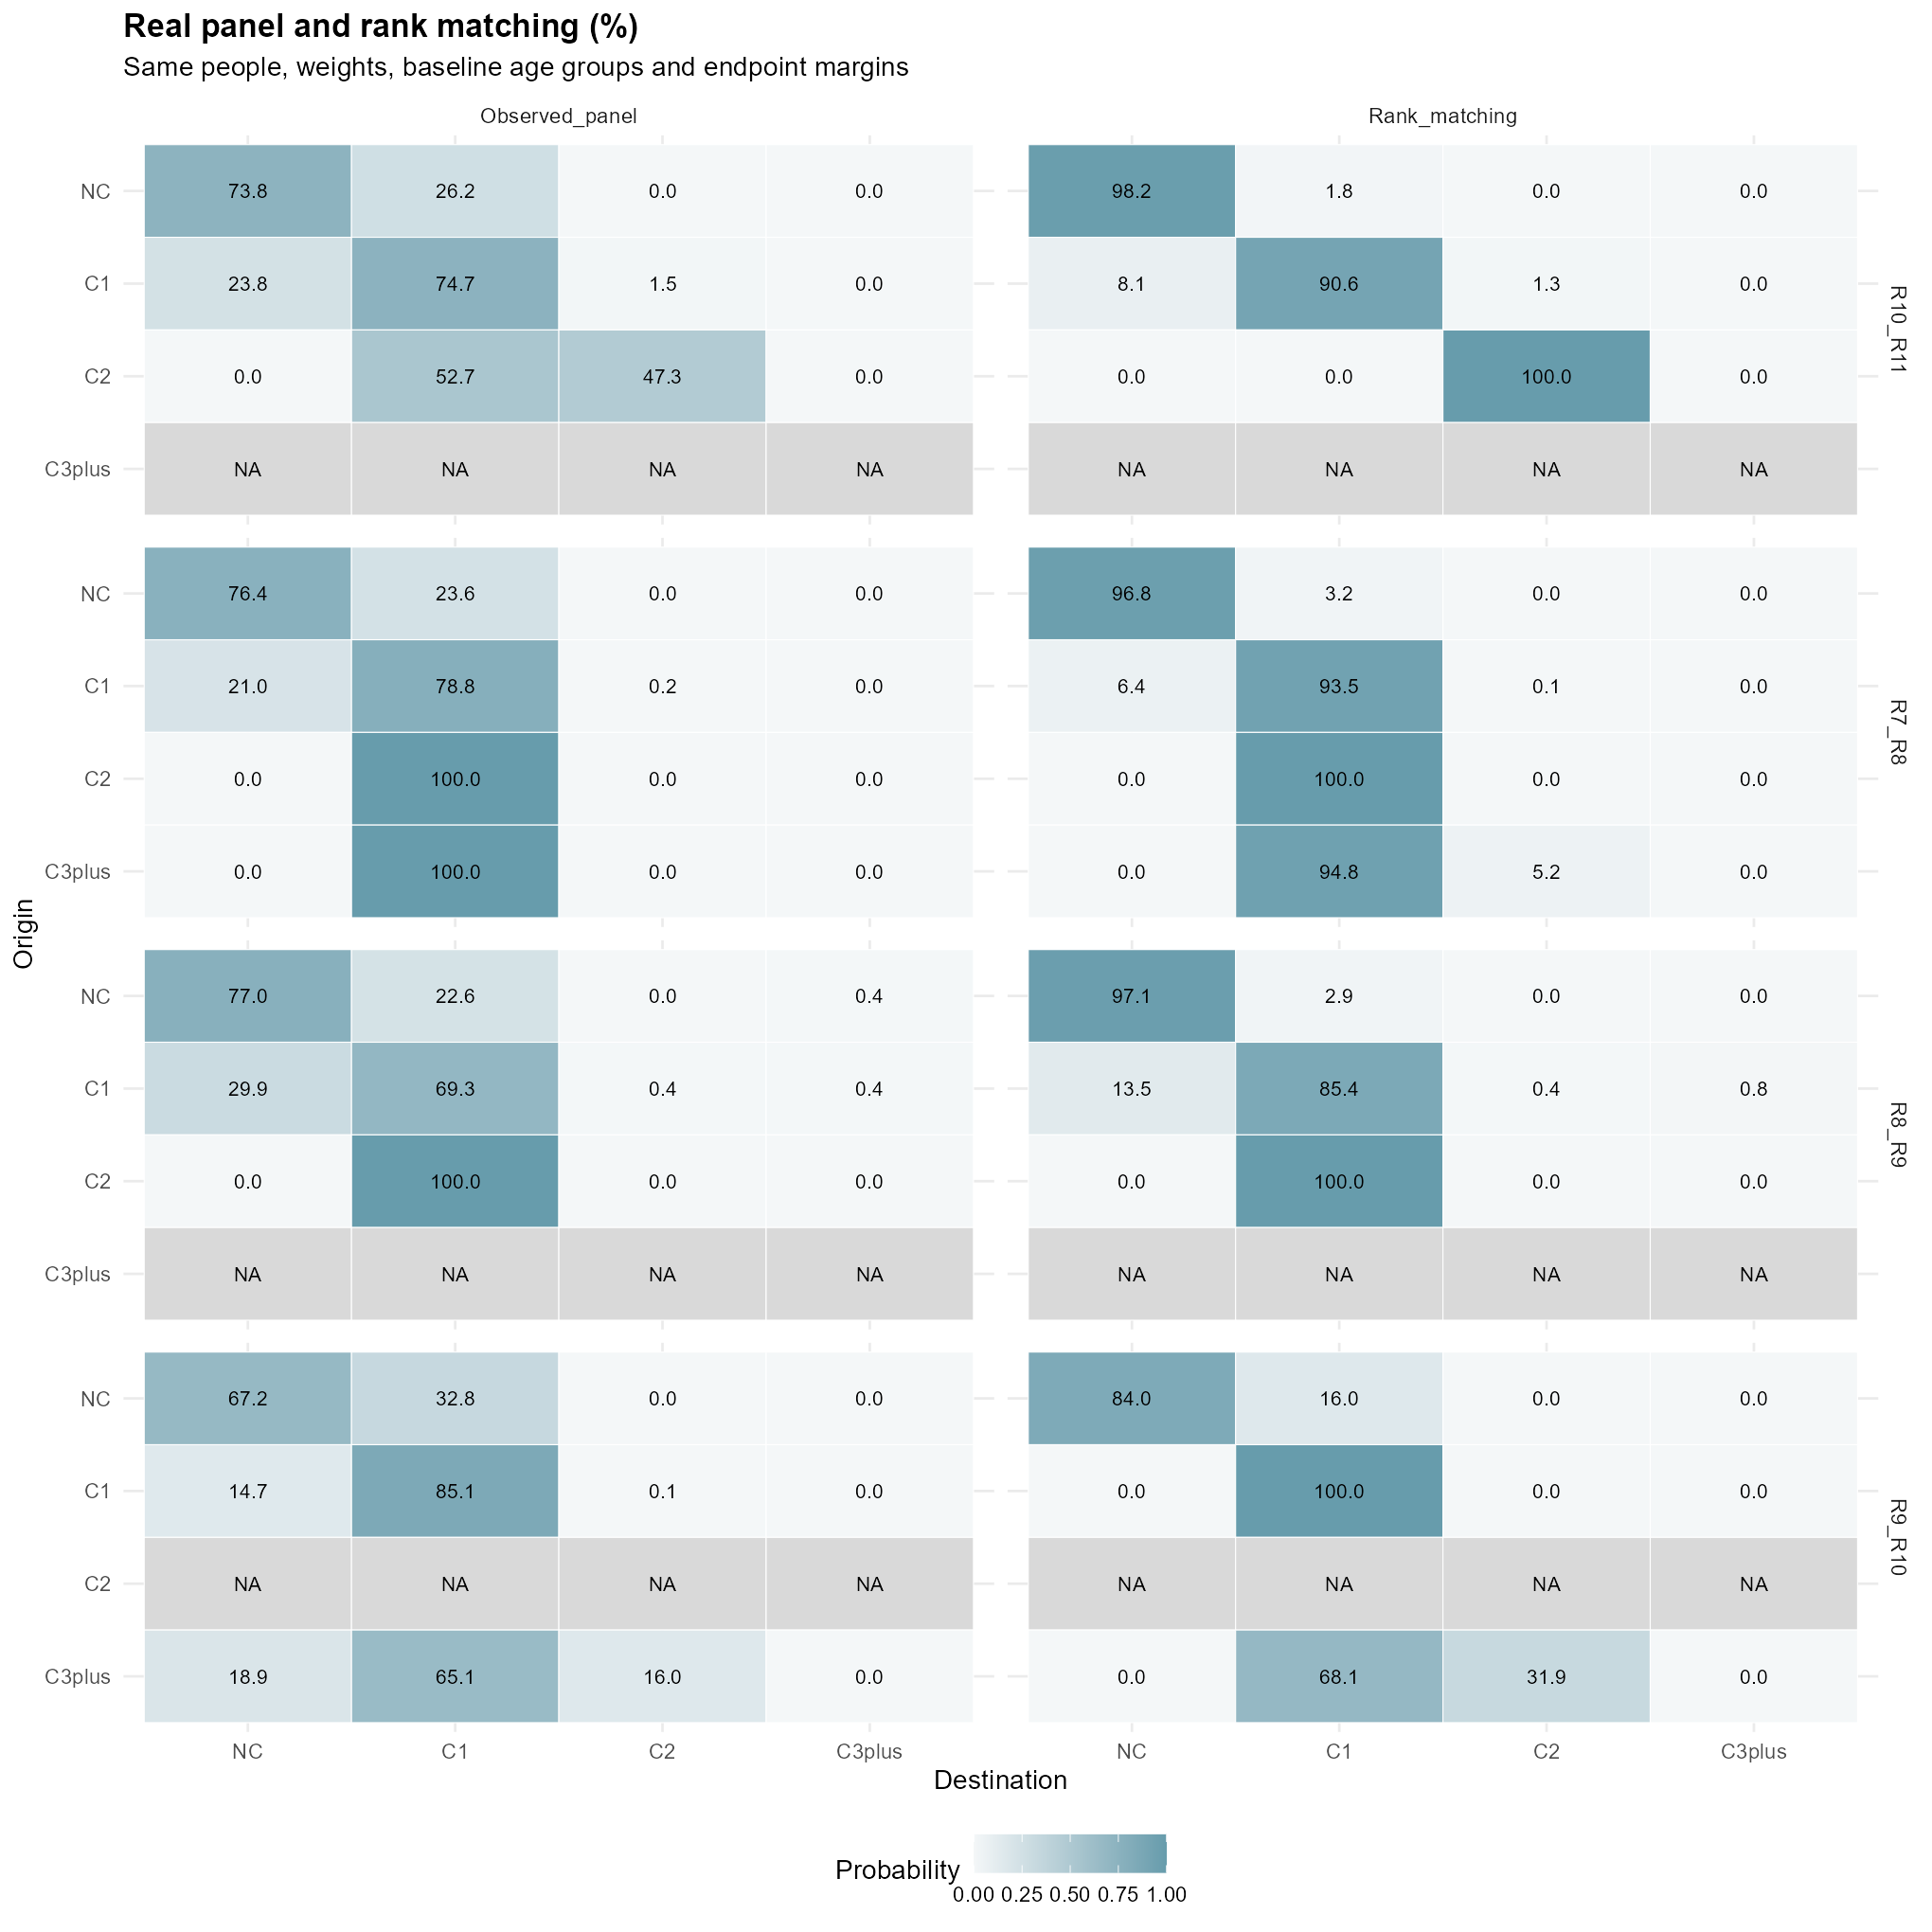

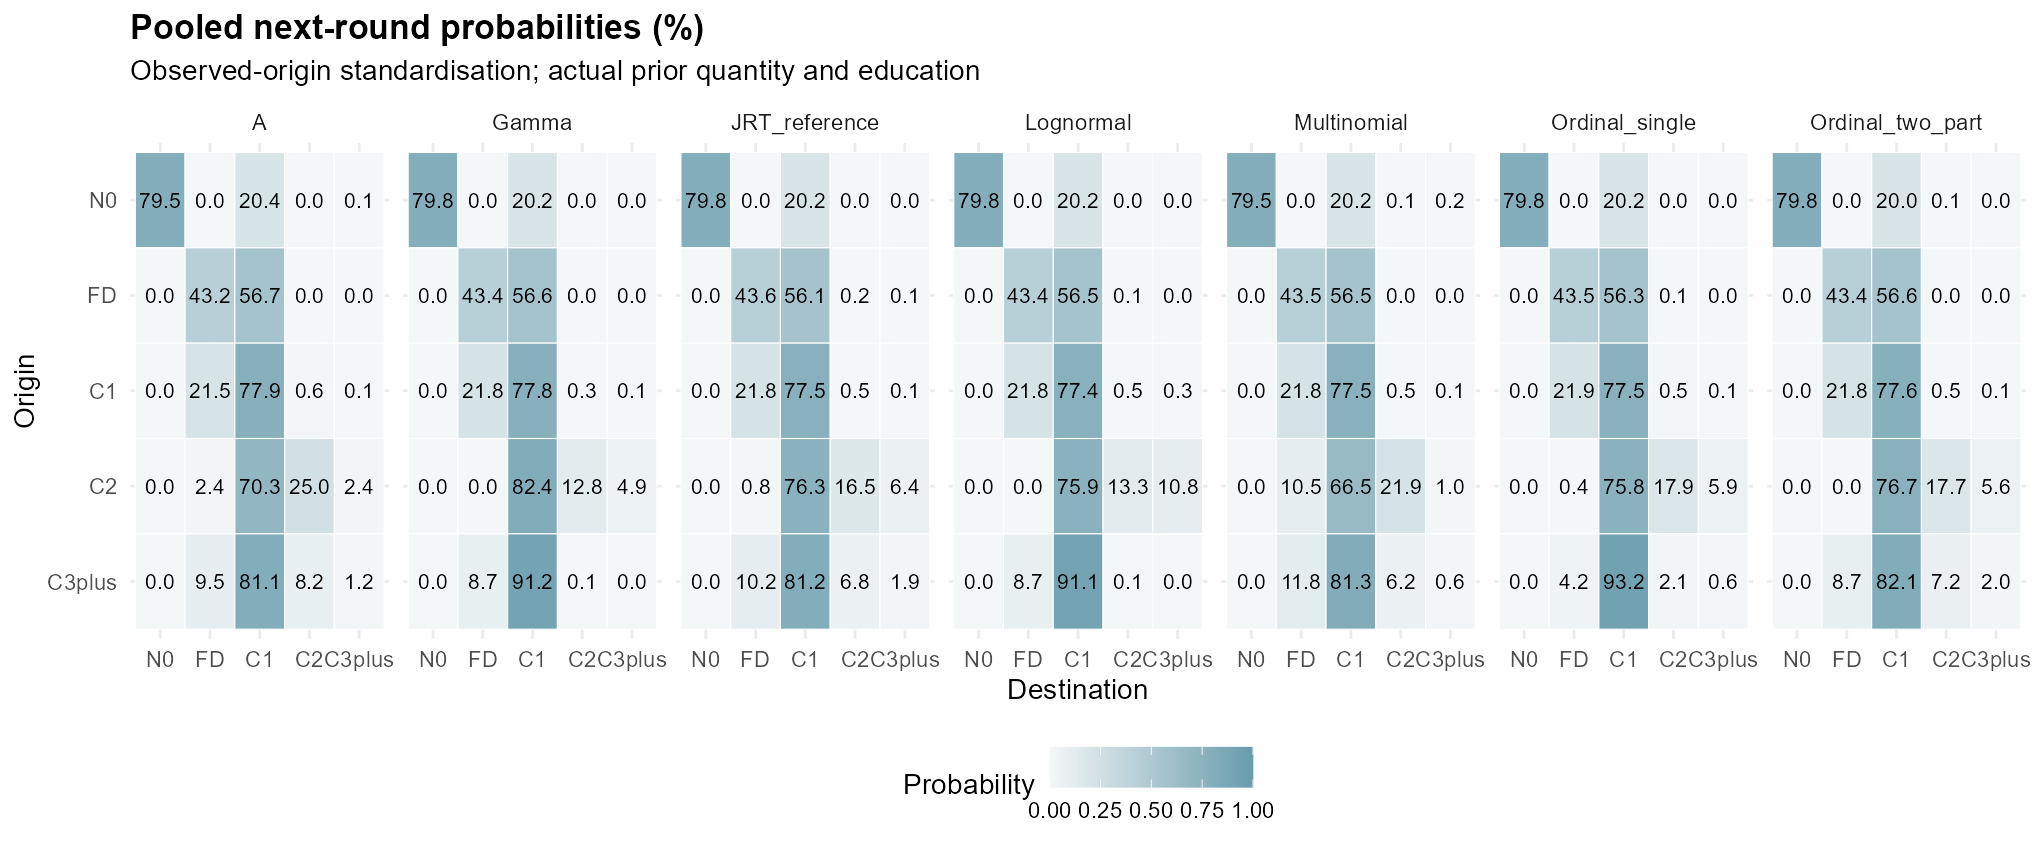

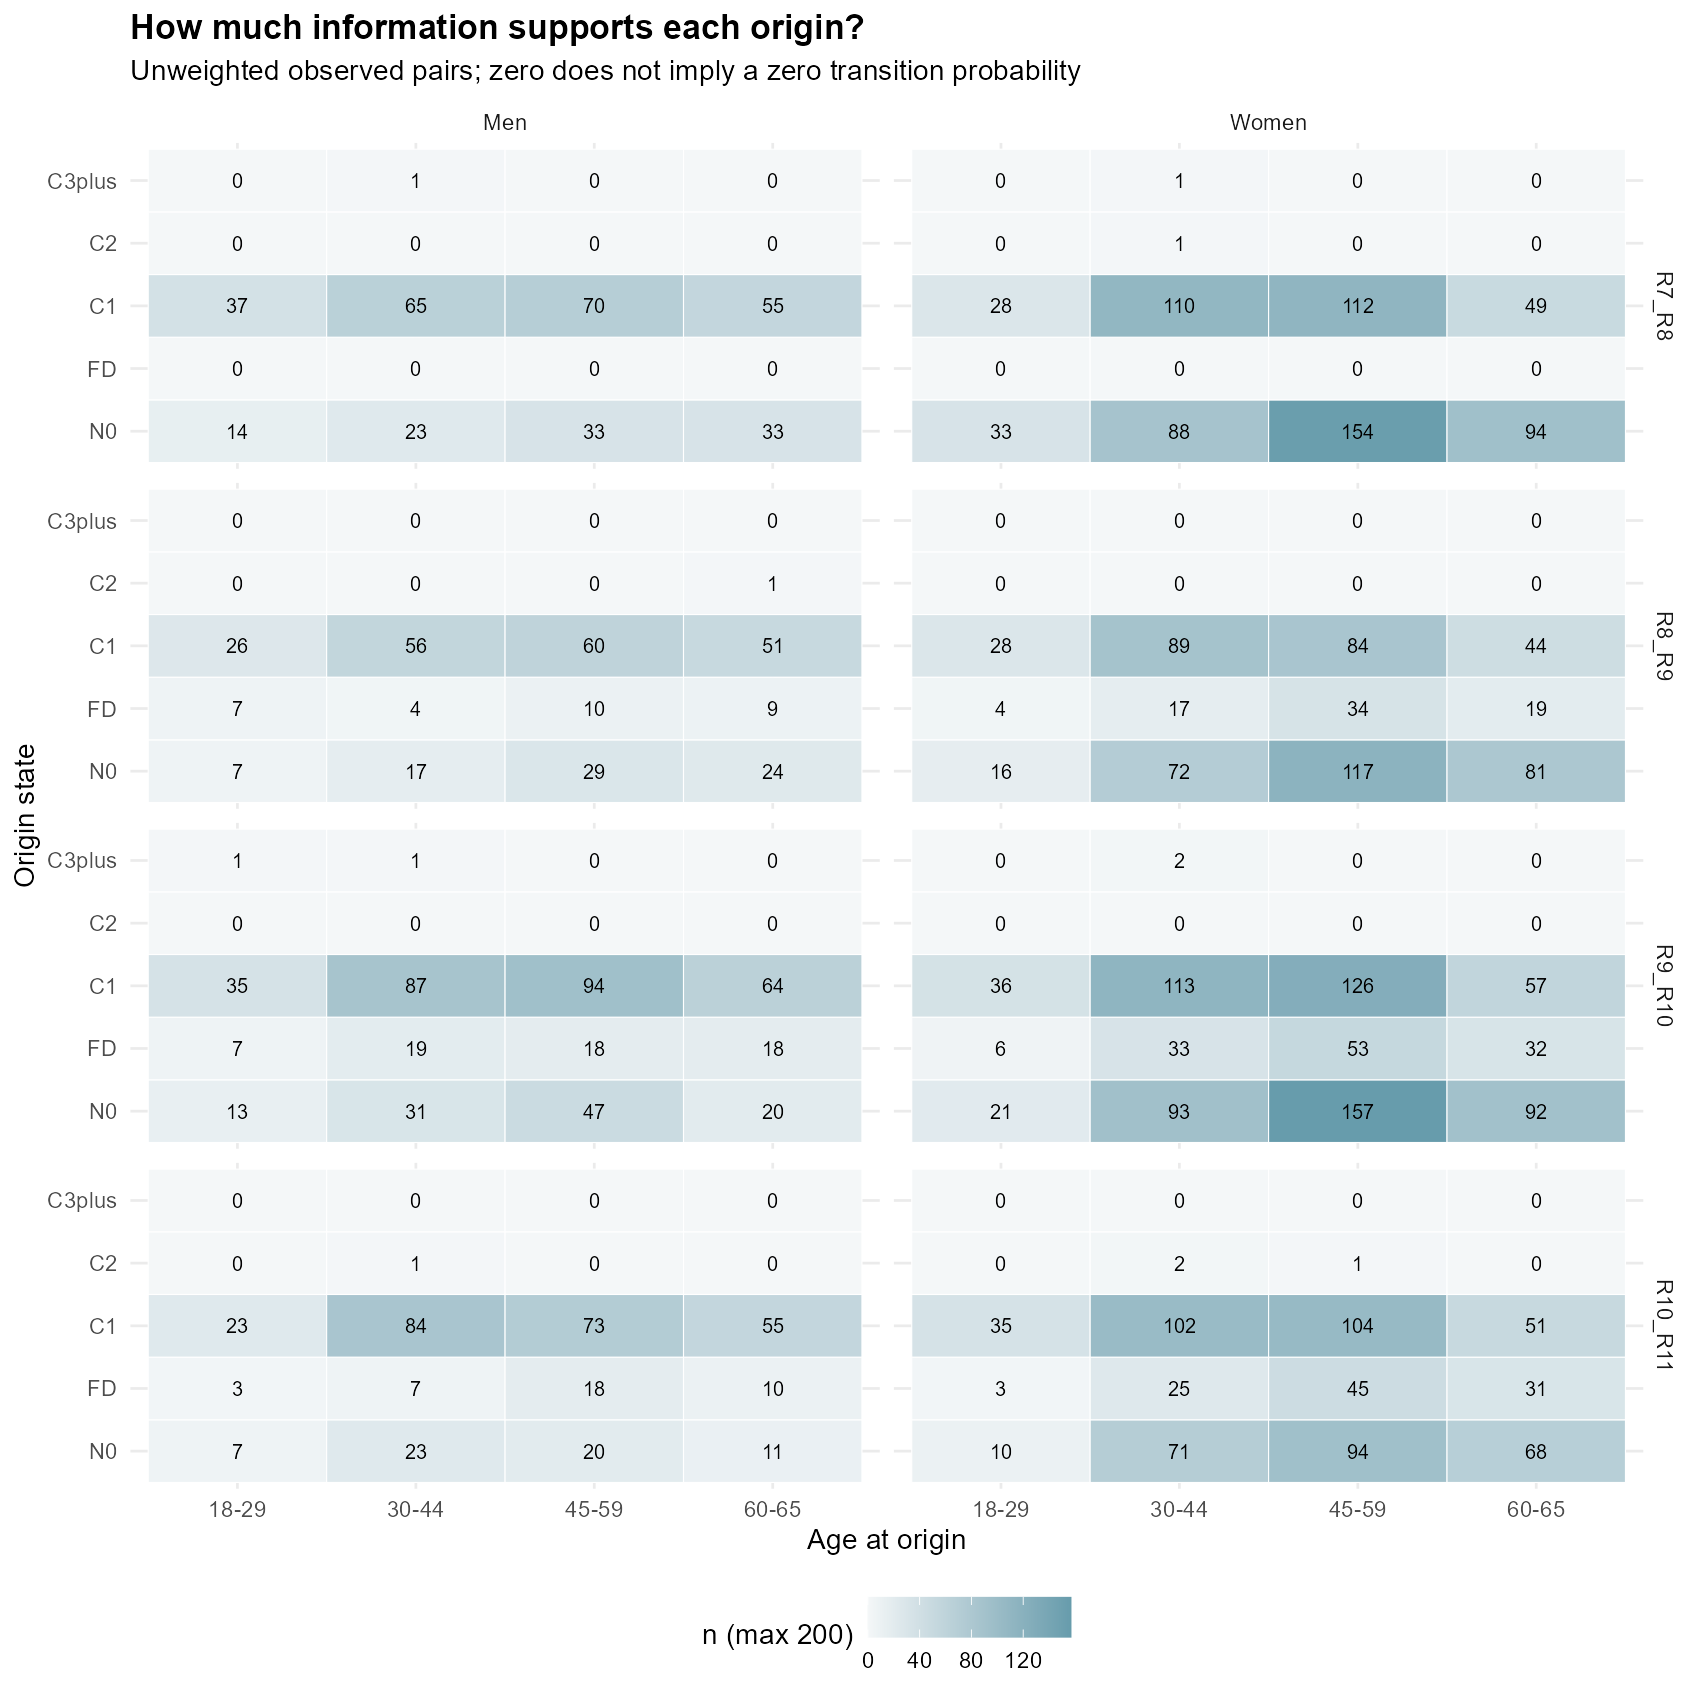

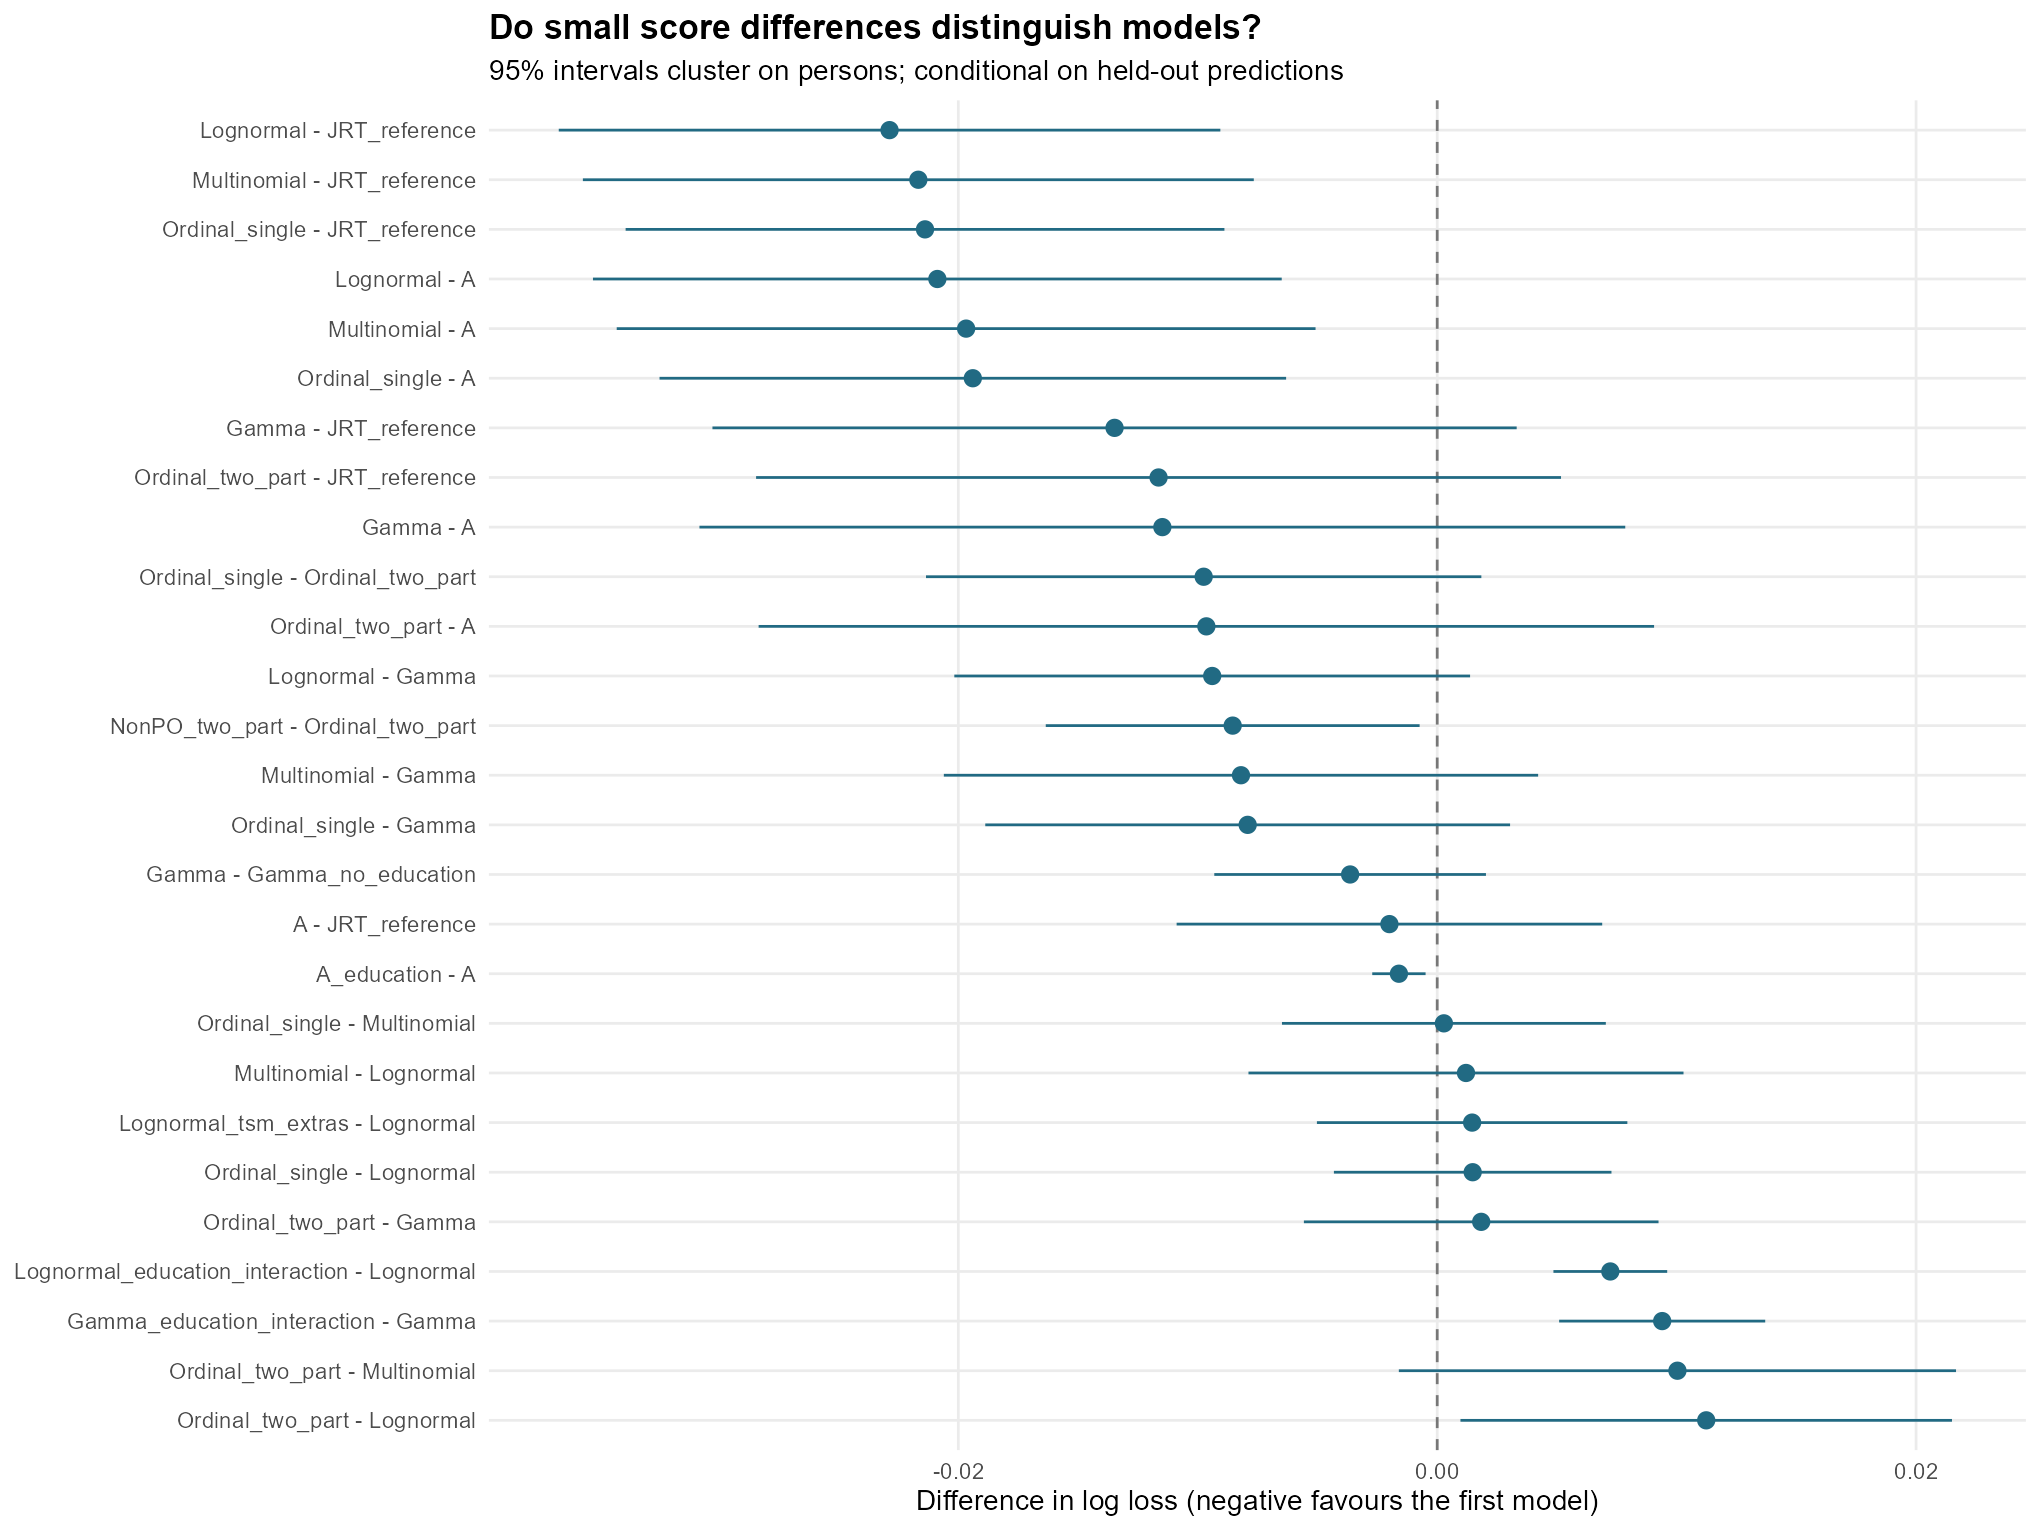

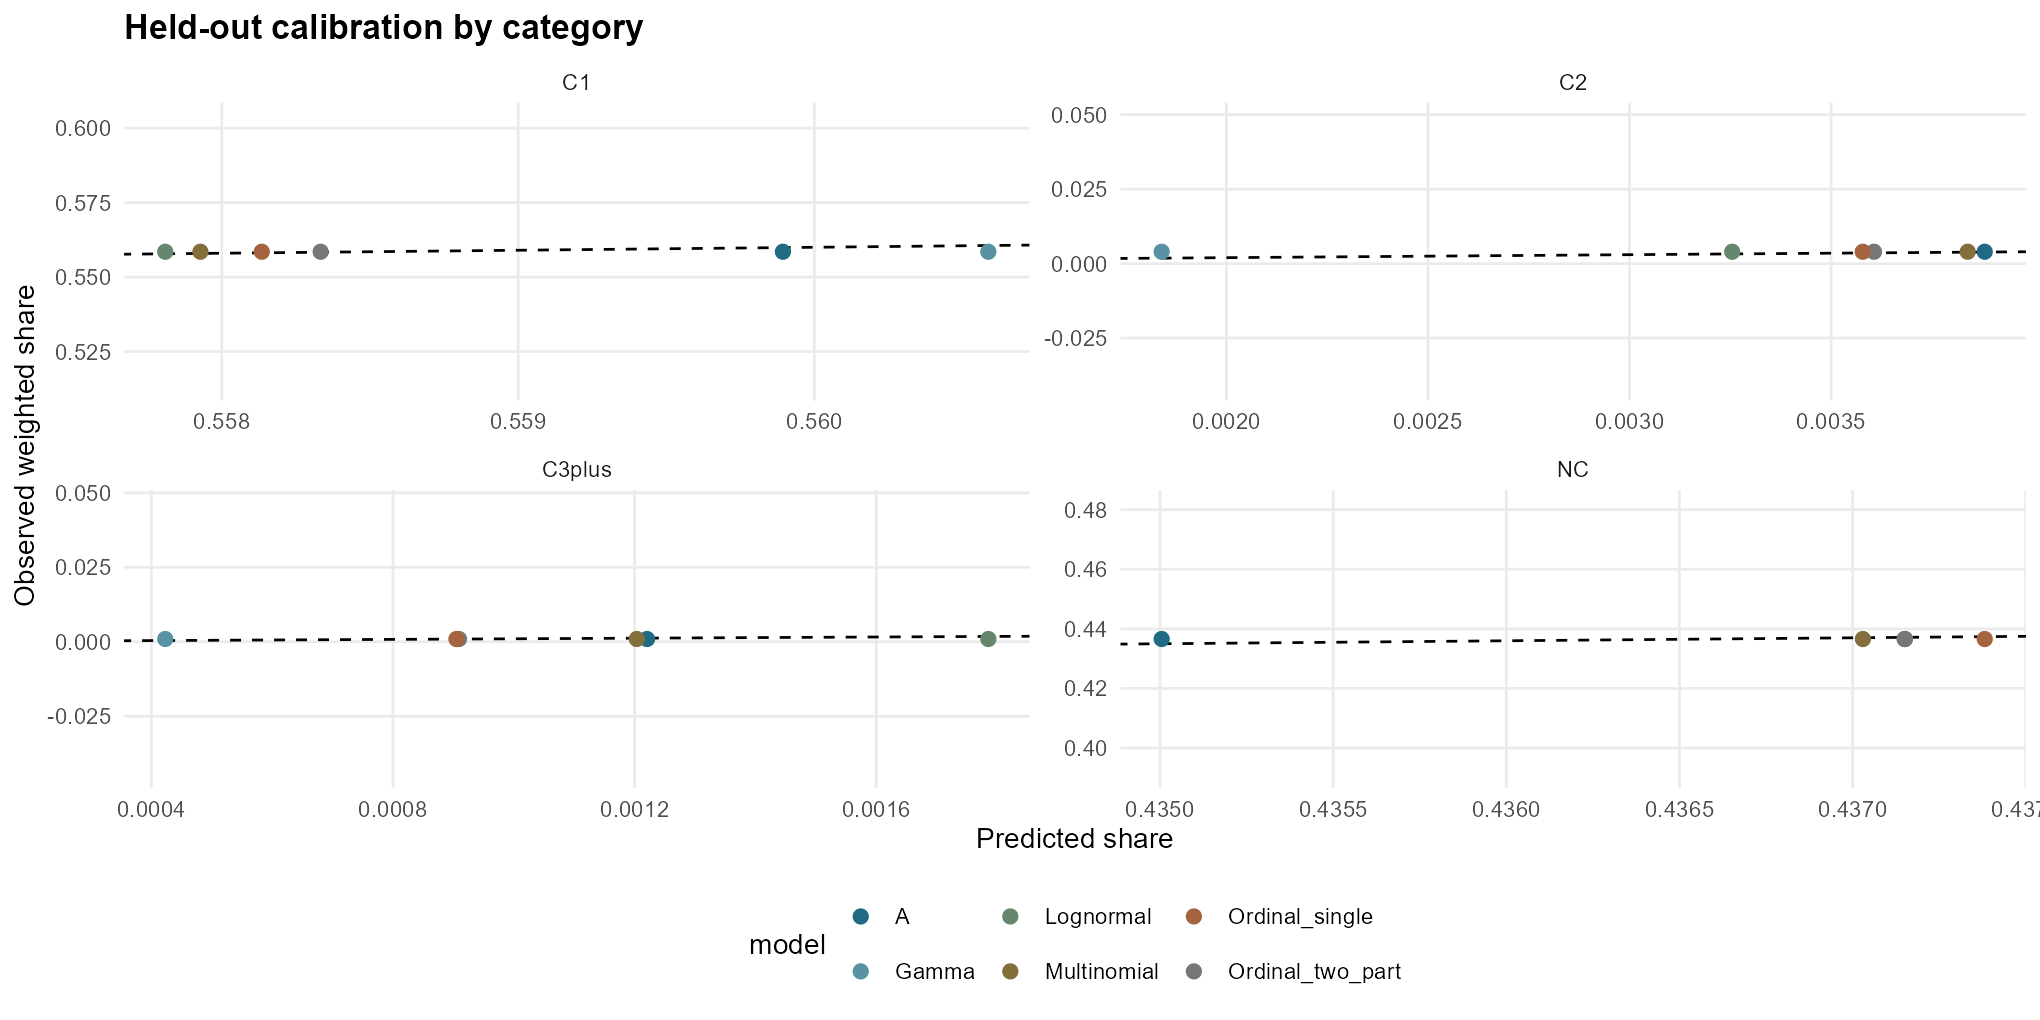

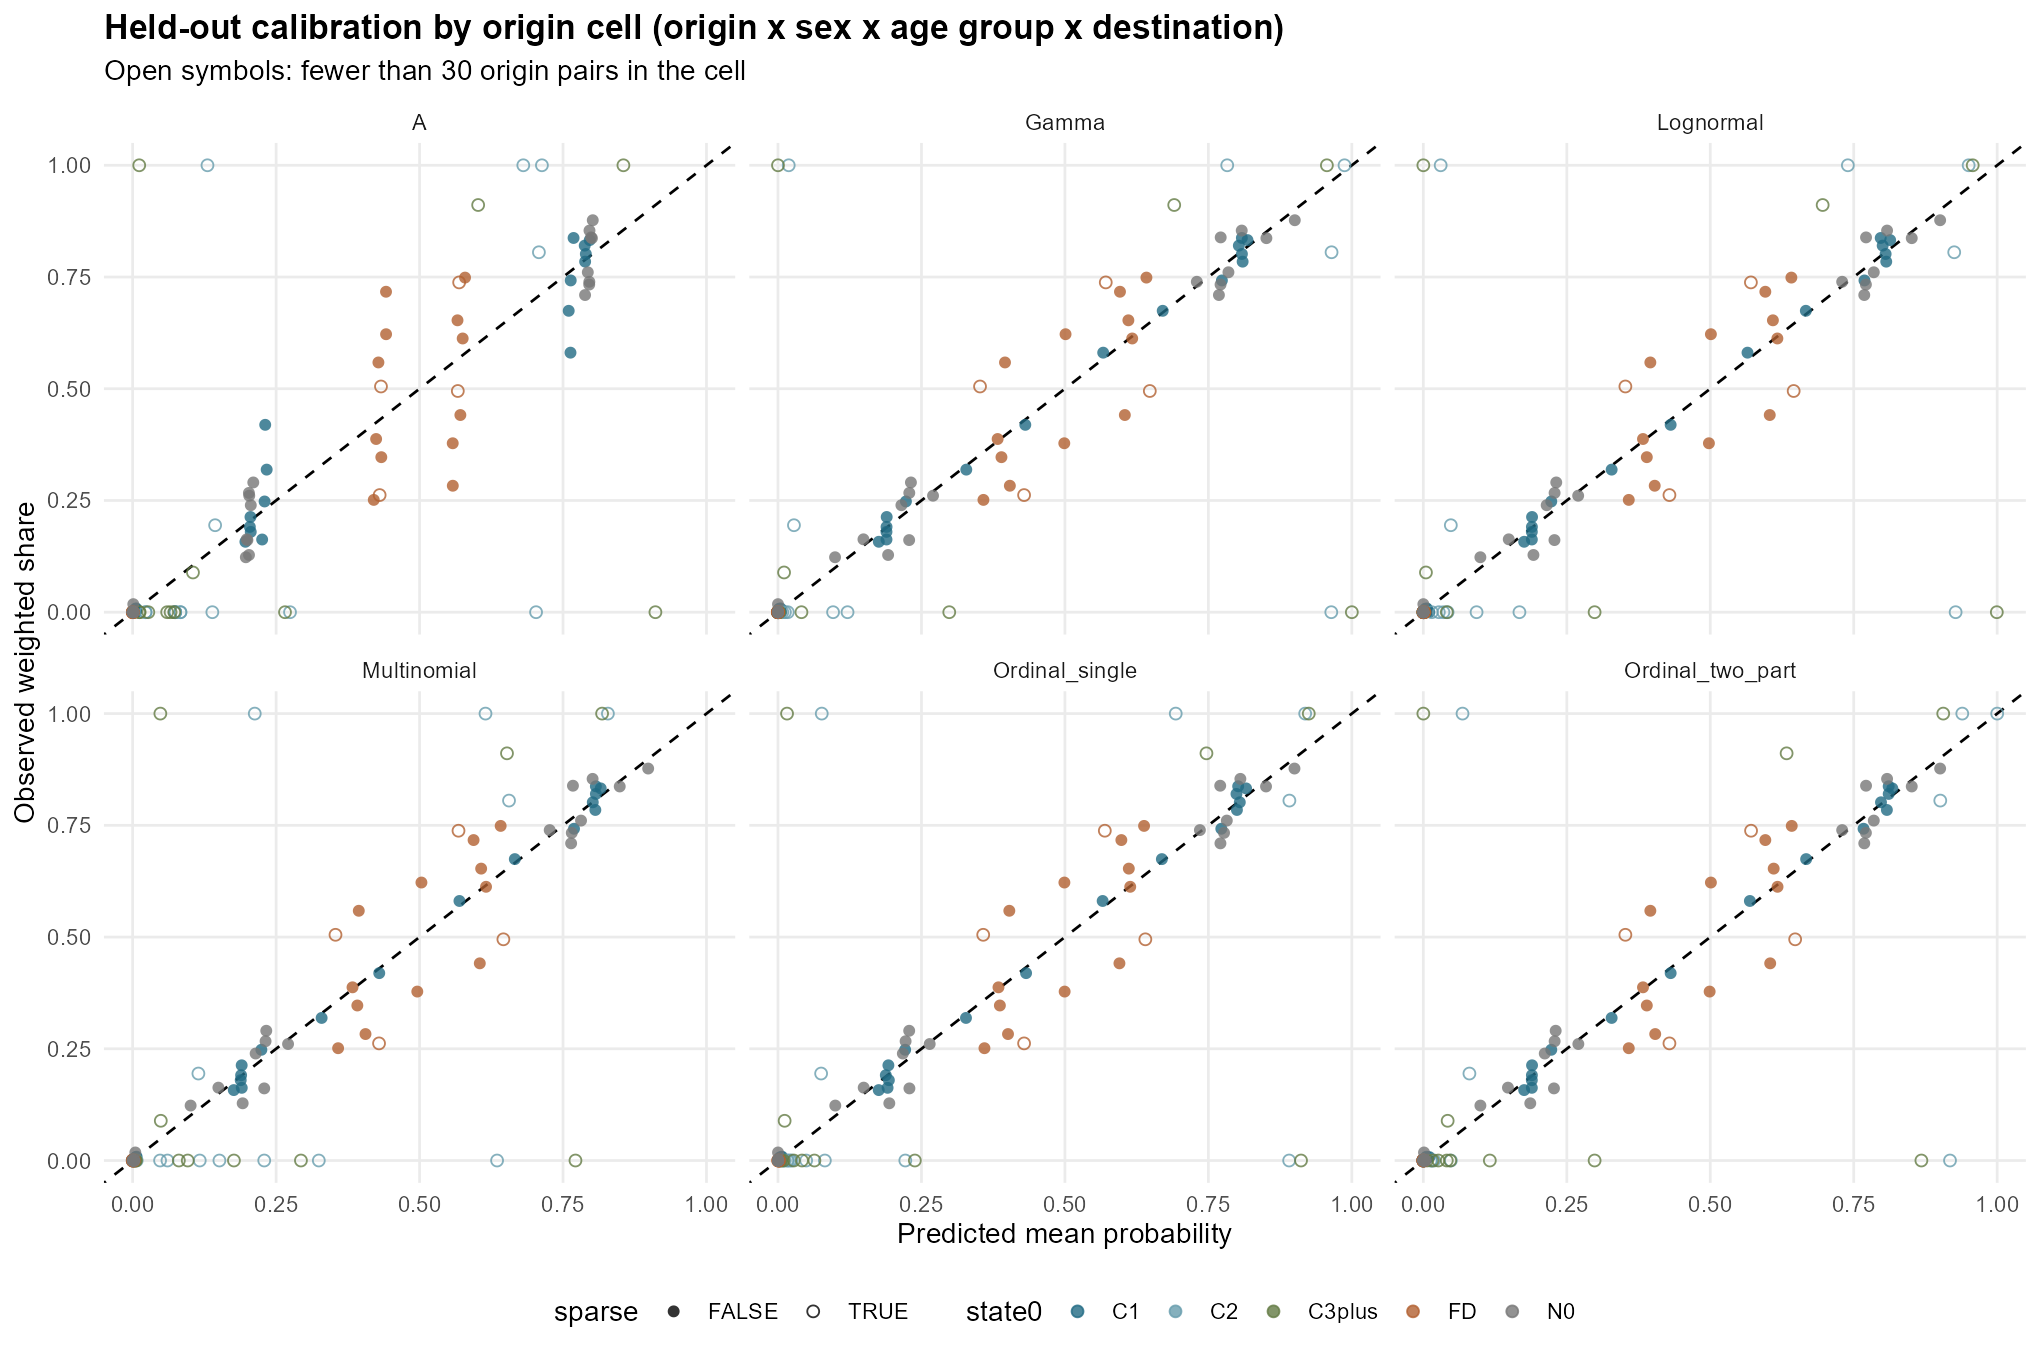

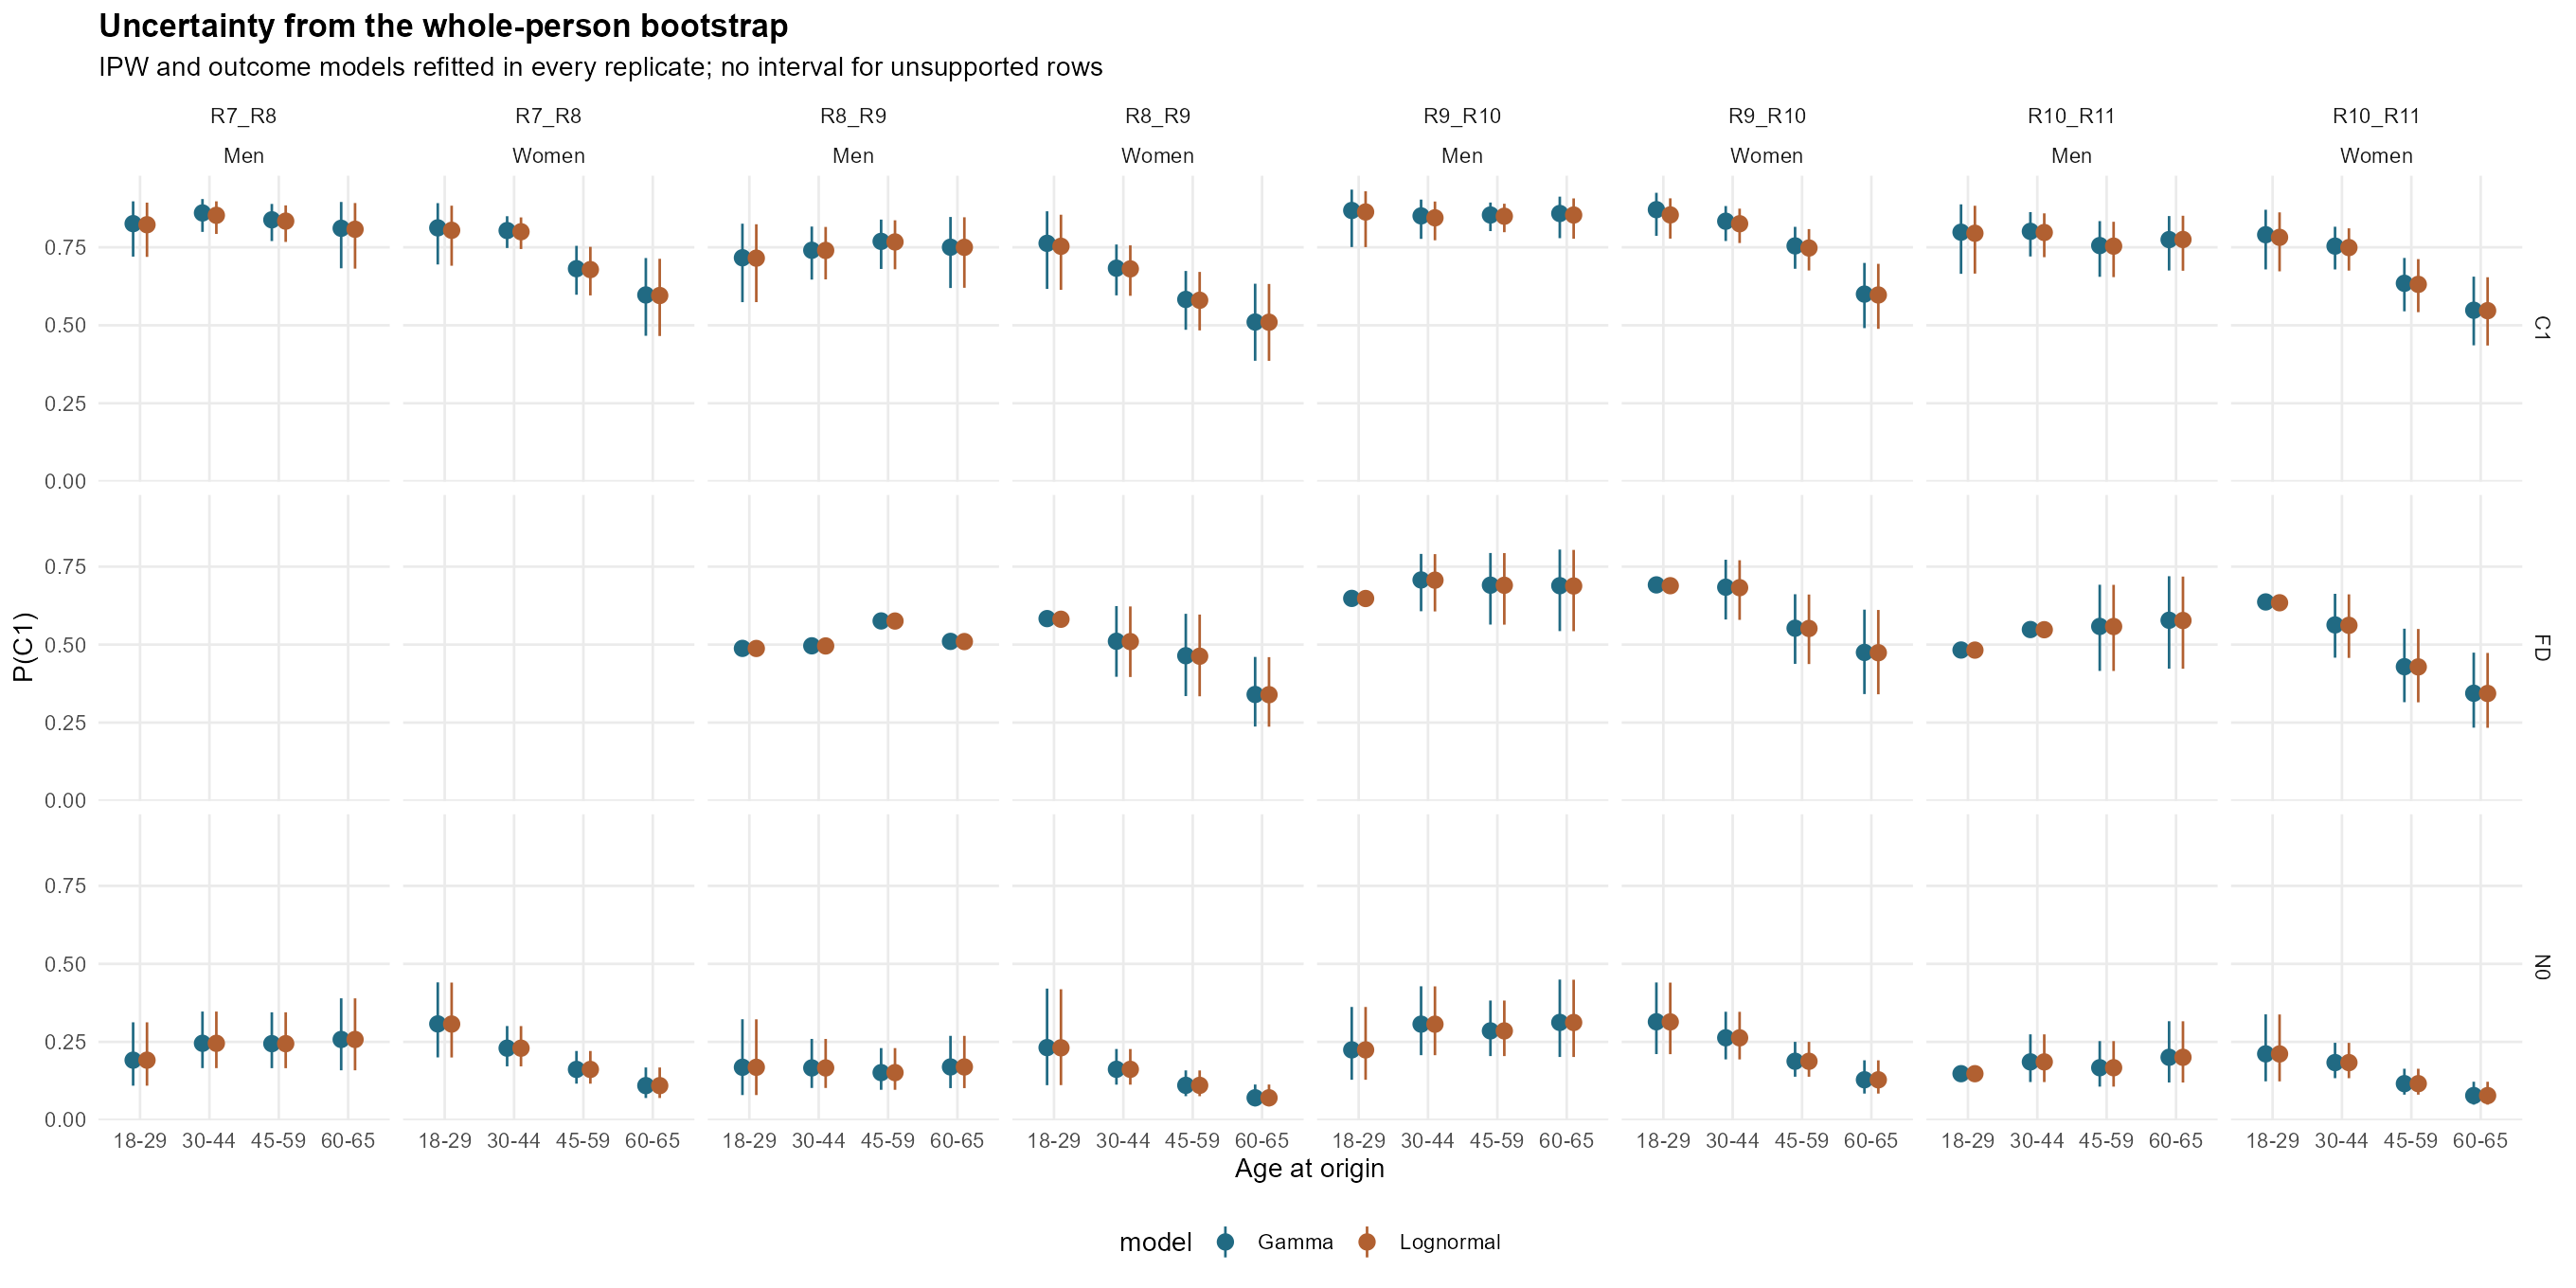

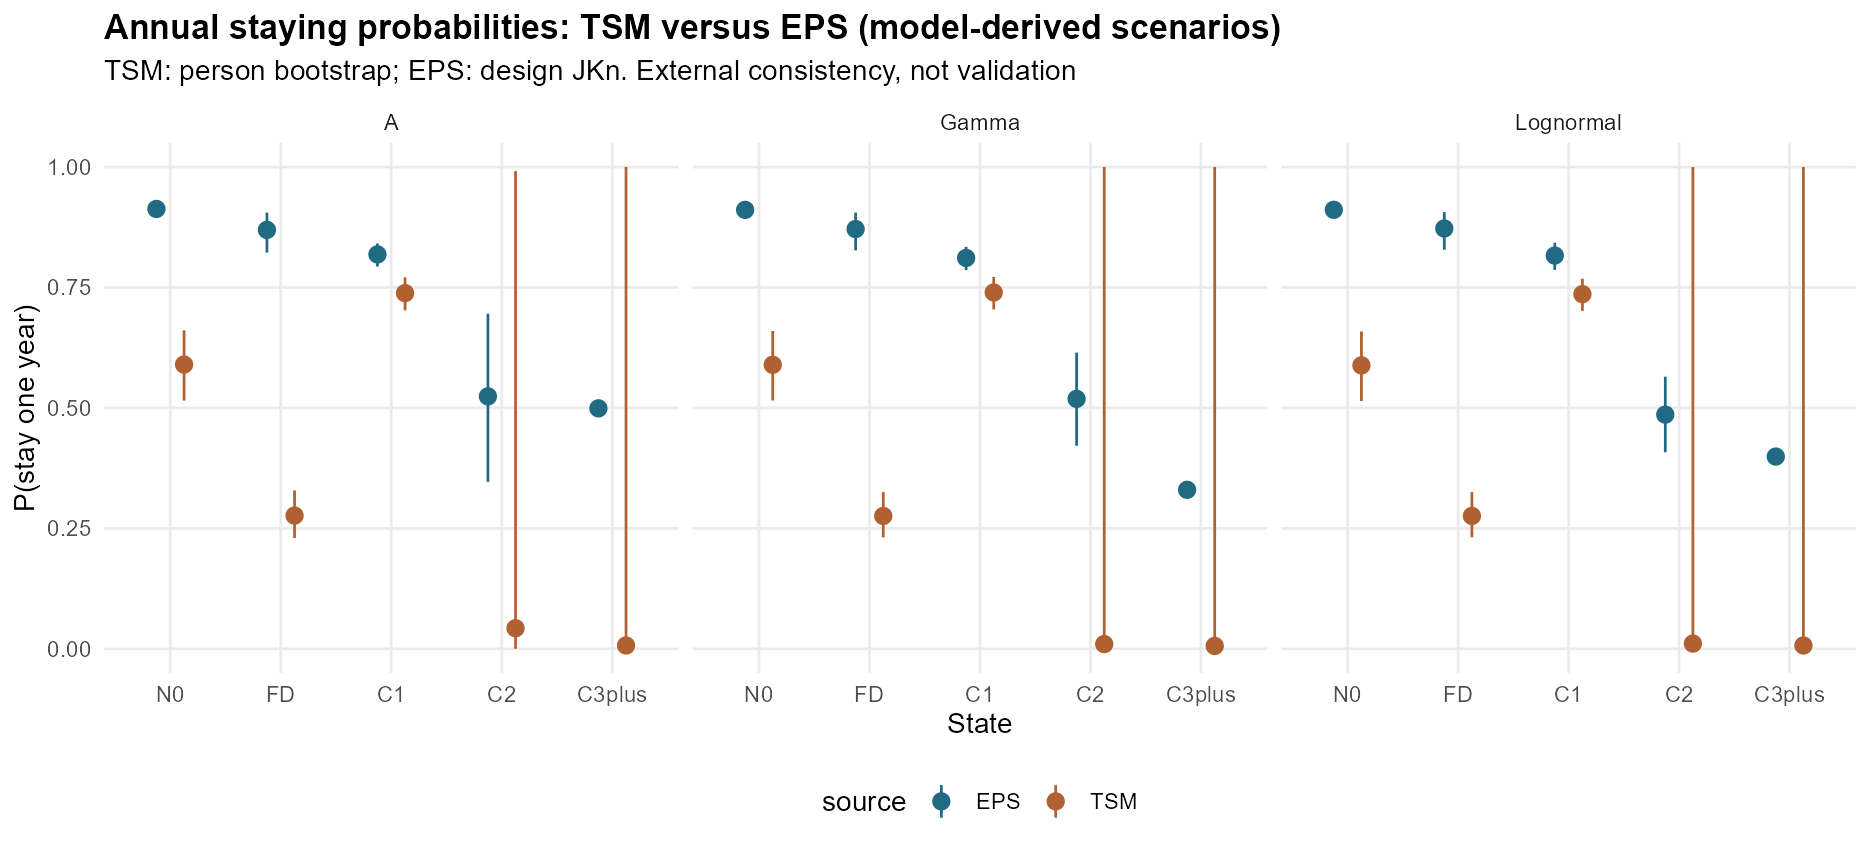

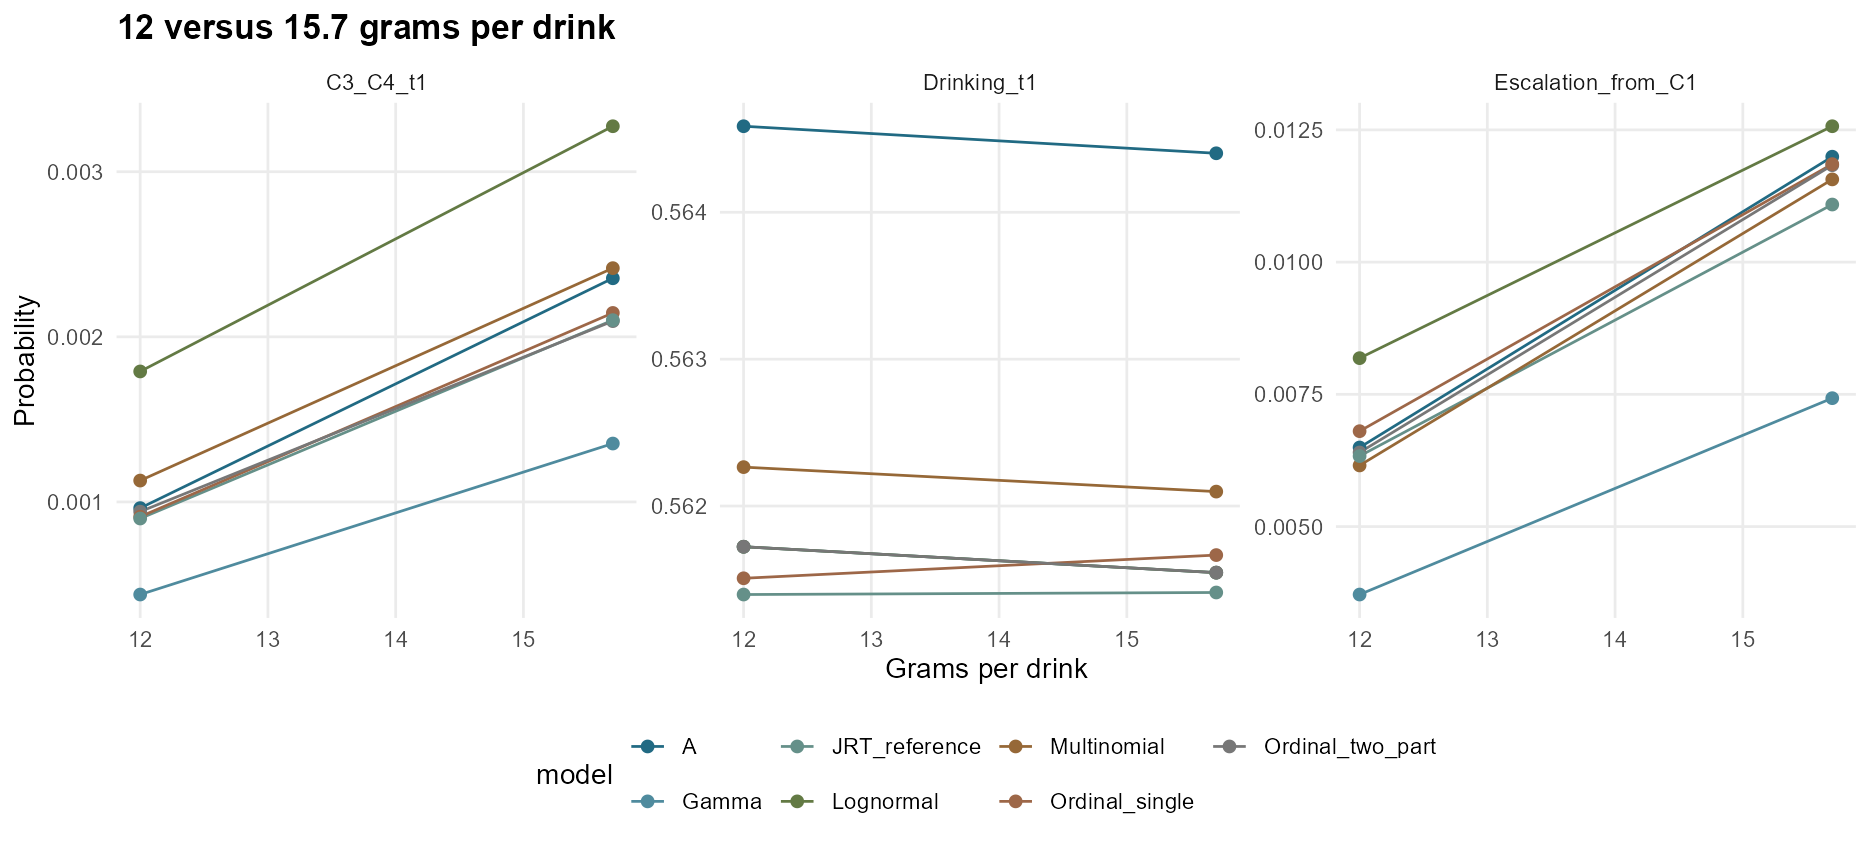

Elapsed: 0.80 minutes


In [27]:
#| label: tsm-sensitivities
.t0 <- Sys.time()
ts_conv <- lapply(c(12, 15.7), function(g) {
 r <- ts_make_risk(ts_waves(g)); d <- ts_ipw_apply(r, ts_ipw_fit(r)); d$pooled <- "All"
 fits <- lapply(stats::setNames(ts_main_models, ts_main_models), function(nm) ts_fit(d, nm, ts_k[1]))
 list(sensitivity = do.call(rbind, lapply(ts_main_models, function(nm) {
  pr <- ts_prob(fits[[nm]], d)
  data.frame(grams_per_drink = g, model = nm, quantity = c("Drinking_t1", "Escalation_from_C1", "C3_C4_t1"),
   probability = c(stats::weighted.mean(1 - pr[, 1], d$wn),
    stats::weighted.mean(rowSums(pr[d$state0 == "C1", 3:ncol(pr), drop = FALSE]), d$wn[d$state0 == "C1"]),
    stats::weighted.mean(rowSums(pr[, 4:ncol(pr), drop = FALSE]), d$wn)))
 })), pooled = if (g == 15.7) do.call(rbind, lapply(ts_main_models, function(nm) ts_matrices(d, ts_prob(fits[[nm]], d), nm, by = "pooled"))))
})
ts_sensitivity <- do.call(rbind, lapply(ts_conv, function(x) x$sensitivity))
ts_save(ts_sensitivity, "conversion_sensitivity")
ts_save(ts_conv[[2]]$pooled, "transition_matrices_15_7g")
ts_upper <- ts_upper_band_sensitivity()
ts_save(ts_upper$summary, "upper_band_sensitivity"); ts_save(ts_upper$pooled, "upper_band_pooled_matrices")
# Four weighting scenarios separate the inverse-probability correction from the trimming of extreme expansion factors.
ts_weight_sens <- do.call(rbind, lapply(c("base_only", "base_trimmed", "IPW_untrimmed", "base_plus_IPW"), function(s) {
 d <- ts_d
 for (p in ts_periods) {
  ii <- d$period == p
  w <- switch(s, base_only = d$wbase[ii],
   base_trimmed = { cap <- ts_wquant(d$wbase[ii], d$mult[ii], c(.01, .99)); pmin(pmax(d$wbase[ii], cap[1]), cap[2]) },
   IPW_untrimmed = d$untrimmed[ii], base_plus_IPW = d$wn[ii])
  d$wn[ii] <- w / sum(w) * ts_period_mass[[p]]
 }
 pr <- ts_prob(ts_fit(d, "Gamma", ts_k[1]), d)
 data.frame(scenario = s, current_t1 = stats::weighted.mean(1 - pr[, 1], d$wn), C3_C4_t1 = stats::weighted.mean(pr[, 4], d$wn),
  weight_ESS = sum(d$wn)^2 / sum(d$wn^2))
}))
ts_save(ts_weight_sens, "weight_refit_sensitivity")
ts_edu_sens <- ts_education_sensitivity()
ts_save(ts_edu_sens$summary, "education_sensitivity"); ts_save(ts_edu_sens$pooled, "education_sensitivity_pooled_matrices")
# Held-out scores of alternative risk sets (one CV repeat): the period masses follow each variant's own complete pairs.
ts_variant_cv <- function(r, label, models = c("A", "Lognormal")) {
 old_mass <- ts_period_mass
 ts_period_mass <<- stats::setNames(vapply(ts_periods, function(p) sum(r$period == p & r$complete), 1), ts_periods)
 on.exit(ts_period_mass <<- old_mass, add = TRUE)
 d <- ts_ipw_apply(r, ts_ipw_fit(r))
 tab <- ts_cv_tables(ts_cv(r, model_names = models, repeats = 1, d = d), d = d)$summary
 cbind(variant = label, tab, pairs = nrow(d), persons = length(unique(d$id)), row.names = NULL)
}
ts_edu_cv <- rbind(ts_variant_cv(ts_risk, "lenient"),
 ts_variant_cv(ts_make_risk(ts_waves(education_rule = "strict")), "strict"),
 ts_variant_cv(ts_make_risk(ts_waves(education_rule = "reached")), "reached"))
ts_save(ts_edu_cv, "education_sensitivity_cv")
# Link rule sensitivity: the strict EPS age bounds (tolerance 0) instead of the primary bounds widened by ts_link_tolerance years.
ts_W_strict <- ts_waves(tolerance = 0); ts_risk_strict <- ts_make_risk(ts_W_strict, tolerance = 0)
ts_save(ts_link_audit(ts_W_strict, ts_risk_strict, tolerance = 0), "link_audit_strict_bounds")
ts_link_primary <- paste0("primary_bounds_tolerance_", ts_link_tolerance)
ts_link_cv <- rbind(ts_variant_cv(ts_risk, ts_link_primary), ts_variant_cv(ts_risk_strict, "strict_EPS_bounds"))
ts_link_pooled <- ts_point_sensitivity(stats::setNames(list(ts_risk, ts_risk_strict), c(ts_link_primary, "strict_EPS_bounds")), c("A", "Lognormal"), "variant")
ts_save(ts_link_cv, "link_bounds_sensitivity_cv"); ts_save(ts_link_pooled$summary, "link_bounds_sensitivity")
ts_save(ts_link_pooled$pooled, "link_bounds_pooled_matrices")
ts_hed_result <- ts_hed(); ts_save(ts_hed_result$coef, "typical_quantity_signal_coefficients")
ts_save(ts_hed_result$proportions, "typical_quantity_signal_by_category")
z1 <- ts_d[!is.na(ts_d$hed6_1), ]; z0 <- ts_d[!is.na(ts_d$hed6_0), ]
ts_hed6 <- rbind(
 do.call(rbind, lapply(split(z1, ts_key(z1, c("y1", "sex"))), function(z) data.frame(level = "destination", category = as.character(z$y1[1]),
  sex = as.character(z$sex[1]), n = nrow(z), share_hed6 = stats::weighted.mean(z$hed6_1, z$wn)))),
 do.call(rbind, lapply(split(z0, z0$state0, drop = TRUE), function(z) data.frame(level = "origin", category = as.character(z$state0[1]),
  sex = "All", n = nrow(z), share_hed6 = stats::weighted.mean(z$hed6_0, z$wn)))))
rownames(ts_hed6) <- NULL
ts_save(ts_hed6, "hed6_item_by_category")
ts_show(ts_sensitivity, "Conversion sensitivity, refitted main models at 12 and 15.7 g per drink", 4)
ts_show(ts_upper$summary, "Upper band 16 drinks instead of 10; point estimates", 4)
ts_show(ts_weight_sens, "Refitted weight sensitivity: base, trimmed base, untrimmed IPW and primary weights", 4)
ts_show(ts_edu_sens$summary, "Education rule sensitivity: strict and reached-level variants; point estimates", 4)
ts_show(ts_edu_cv, "Education rule sensitivity: held-out scores, one CV repeat", 5)
ts_show(ts_link_cv, "Link rule sensitivity: pairs retained and held-out scores under the strict EPS age bounds", 5)
ts_show(ts_link_pooled$summary, "Link rule sensitivity: pooled point estimates", 4)
ts_show(ts_hed6, "Weighted share reporting the 6+ item by destination category and by origin state", 3)
ts_plots()
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


## HED persistence beyond volume (exploratory)

**Why this section exists.** The microsimulation engine assigns heavy episodic drinking (HED) every year with a logistic model on volume, one intercept per sex × age cell plus a slope on log(1 + g/day), and a personal latent tendency `z_hed` whose yearly correlation is set to 0.8 by assumption. This section asks what the TSM panel supports instead. It answers three questions: whether previous HED adds information once volume is known; how large the dependence is on the engine's own scale; and which combinations of strength and duration of that dependence the data can and cannot tell apart. It uses the version 4 data layer unchanged and does not touch the engine.

**Definitions.** HED is the 6+ item already used above (`hed6`: at least one occasion with six or more drinks, any answer other than "never"), defined for current drinkers only. Volume is g/day at 12 g per drink. The main analysis uses drinkers at both ends of the adjacent pairs, with the version 4 IPW weights.

**Tables and transition logistic.** The first two tables show how often HED repeats, overall and within volume bands at the next round. The logistic adds previous HED to models that already contain sex × age and volume, either at the origin (pure prediction) or at the next round (as the engine does); odds ratios have person-clustered intervals, and person-blocked cross-validation shows whether previous HED improves held-out predictions.

**The engine's parameter.** In the engine, HED = 1 when Φ(Z) < p, with p from the volume logistic. For two interviews of the same drinker, the probability of HED at both is

$$
P(\text{HED}_t=1,\ \text{HED}_{t'}=1)=\Phi_2\!\left(\Phi^{-1}(p_t),\ \Phi^{-1}(p_{t'});\ \rho\right),
$$

a Gaussian copula with logistic margins. Estimating ρ with the engine's margin, stacked over both interviews, recovers the parameter the engine assumes, after volume is taken into account. Variants: no IPW; a saturated margin with one level per frequency × typical-quantity band, which bounds how much of ρ is margin misfit; drinkers two or more times a month at both rounds; and HED defined as six or more drinks monthly or more often. A joint likelihood of margin and ρ, the core of a GJRM bivariate binary model, checks the two-step estimate.

**Strength versus duration.** Two quantities must not be confused:

- r(1), the effective correlation between two consecutive years, which is what the engine calls ρ today;
- φ, the share of the persistent part that survives each year.

If a persistent part explains a share R of the latent variance and an occasion component does not carry over, the correlation at d years is R·φ^d, so r(1) = R·φ and R = r(1)/φ ≤ 1. The engine's yearly innovation feeds the persistent part only, so today R = 1 and r(1) = φ = 0.8. TSM pairs span 4 to 24 months. The latent correlation is estimated at five distances, and the curve R·φ^(months/12) is fitted to them by minimum distance, with the covariance of the five estimates taken from the whole-person bootstrap because people appear at several distances. Sub-annual distances enter as months/12, which assumes exponential decay inside the year; the engine itself only has yearly steps. The 95% region collects the combinations whose distance exceeds the minimum by at most the 95% quantile of a chi-square with two degrees of freedom. Separating stable differences between people from change within people is a known problem in longitudinal models (Hamaker et al., 2015); here a stable part cannot be told apart from one that decays slowly within two years.

**How to read the results.** The region shows which values of r(1) the data support. φ is weakly identified, and every correlation beyond 24 months, at 5 or 10 years, is an extrapolation: a scenario, not an estimate. The 24-month distance rests on a single pair of rounds (R7–R11), the most selected by retention and the one with the least certain fieldwork date, so the fit is repeated without it; the goodness-of-fit row says whether one curve describes all distances at once. The scenario table labels each candidate as inside or outside the region and lists its implied correlations; it is the input for later engine and DIR sensitivity work, not a calibrated value. Bootstrap intervals use the version 4 replicate count and refit IPW in every replicate; the multi-round pairs have no IPW, so they are unweighted, and a row reports how much IPW moves the adjacent estimate. Transport to the engine is not automatic: the 6+ item has no recall window, while the engine's margin comes from the ENPG 30-day item (5+ drinks for men, 4+ for women), and the TSM volume comes from bands with a different slope. Any change in the engine would apply to `z_hed` only, because one ρ currently drives the participation, amount and HED latents together.


TSM bootstrap (HED persistence) 100/1000; IPW refitted
TSM bootstrap (HED persistence) 200/1000; IPW refitted
TSM bootstrap (HED persistence) 300/1000; IPW refitted
TSM bootstrap (HED persistence) 400/1000; IPW refitted
TSM bootstrap (HED persistence) 500/1000; IPW refitted
TSM bootstrap (HED persistence) 600/1000; IPW refitted
TSM bootstrap (HED persistence) 700/1000; IPW refitted
TSM bootstrap (HED persistence) 800/1000; IPW refitted
TSM bootstrap (HED persistence) 900/1000; IPW refitted
TSM bootstrap (HED persistence) 1000/1000; IPW refitted


origin,pairs,pct_does_not_drink,pct_drinks_no_HED,pct_drinks_HED
Does not drink,2045,72.9,20.4,6.7
"Drinks, HED",619,15.8,39.9,44.3
"Drinks, no HED",1496,24.4,59.2,16.4


group,pairs,HED_at_t,pct_HED_t1_if_HED_t,pct_HED_t1_if_no_HED_t
Volume at t+1 <=2 g/day,1113,278,41.1,14.7
Volume at t+1 2-10 g/day,401,181,65.3,40.2
Volume at t+1 >10 g/day,85,53,61.0,45.4
Men,777,303,56.8,26.8
Women,822,209,43.8,16.0
All drinker pairs,1599,512,52.6,21.7


model,OR_previous_HED,lower,upper
previous_volume_plus_HED,3.00,1.92,4.70
same_round_volume_plus_HED,2.96,1.91,4.59
both_volumes_plus_HED,2.84,1.78,4.53


model,AUC,logloss
both_volumes_plus_HED,0.7331,0.5403
previous_volume,0.6491,0.5888
previous_volume_plus_HED,0.6815,0.5708
same_round_volume,0.7054,0.5575
same_round_volume_plus_HED,0.7320,0.5400


...

estimate,description,pairs,rho,lower,upper
adjacent_IPW,"Adjacent pairs, engine margin, IPW (primary)",1599,0.327,0.143,0.460
adjacent_unweighted,"Adjacent pairs, engine margin, no IPW",1599,0.267,0.157,0.353
adjacent_bands,"Adjacent pairs, saturated frequency x quantity margin, IPW",1599,0.284,0.092,0.411
adjacent_frequent,"Adjacent pairs, drinkers 2+ times a month at both rounds, IPW",599,0.371,0.143,0.523
adjacent_monthly,"Adjacent pairs, 6+ drinks monthly or more often (prevalence about 9%), IPW",1599,0.003,-0.247,0.197
IPW_minus_unweighted,Effect of the IPW weights on the adjacent estimate,1599,0.060,-0.084,0.170
joint_ML,"Margin and rho in one likelihood (GJRM-type core), point only",1599,0.335,NA,NA


bin,rounds,mean_months,pairs,persons,rho,lower,upper
4-5,R8-R9;R10-R11,4.565,717,588,0.242,0.087,0.367
7-8,R7-R8;R9-R10,7.429,882,723,0.283,0.148,0.383
11-12,R7-R9;R8-R10;R9-R11,11.706,1197,787,0.336,0.233,0.423
16-19,R7-R10;R8-R11,17.950,734,589,0.350,0.218,0.445
24,R7-R11,24.000,369,369,0.082,-0.152,0.244


moments,minimum_distance,n_moments,parameters,p_value,best_r1,best_phi,bootstrap_replicates
all five distances,7.252,5,2,0.064,0.30,0.95,1000
without the 24-month pair,2.156,4,2,0.340,0.31,1.00,1000


moments,quantity,lower,upper,read_as
all five distances,r1 (profile 95%),0.240,0.360,supported by the data
all five distances,phi (profile 95%),0.670,1.000,weakly identified
all five distances,R inside the 95% region,0.220,0.493,supported by the data
all five distances,correlation at 5 years inside the region,0.035,0.380,assumption (extrapolation)
all five distances,correlation at 10 years inside the region,0.003,0.380,assumption (extrapolation)
without the 24-month pair,r1 (profile 95%),0.250,0.380,supported by the data
without the 24-month pair,phi (profile 95%),0.790,1.000,weakly identified
without the 24-month pair,R inside the 95% region,0.230,0.443,supported by the data
without the 24-month pair,correlation at 5 years inside the region,0.075,0.400,assumption (extrapolation)
without the 24-month pair,correlation at 10 years inside the region,0.015,0.400,assumption (extrapolation)


scenario,r1,phi,R,distance,delta,fixed_point_p,corr_4_months,corr_1_year,corr_2_years,corr_5_years,corr_10_years,TSM_support,beyond_24_months,TSM_support_without_24_months
TSM best fit (minimum distance),0.30,0.95,0.316,7.252,0.000,0.203,0.310,0.30,0.285,0.244,0.189,inside the 95% region (4-24 months),assumption: TSM observes 4 to 24 months only,inside
"Stable trait (phi = 1), best",0.30,1.00,0.300,7.331,0.079,0.197,0.300,0.30,0.300,0.300,0.300,inside the 95% region (4-24 months),assumption: TSM observes 4 to 24 months only,inside
"Stable trait, lowest supported r1",0.22,1.00,0.220,12.383,5.131,0.030,0.220,0.22,0.220,0.220,0.220,inside the 95% region (4-24 months),assumption: TSM observes 4 to 24 months only,outside
"Stable trait, highest supported r1",0.38,1.00,0.380,13.088,5.836,0.023,0.380,0.38,0.380,0.380,0.380,inside the 95% region (4-24 months),assumption: TSM observes 4 to 24 months only,inside
Fastest decay inside the 95% region,0.27,0.60,0.450,13.169,5.917,0.022,0.380,0.27,0.162,0.035,0.003,inside the 95% region (4-24 months),assumption: TSM observes 4 to 24 months only,outside
"Pure AR(1) without an occasion component (R = 1), best",0.23,0.23,1.000,52.195,44.943,0.000,0.613,0.23,0.053,0.001,0.000,outside the 95% region,assumption: TSM observes 4 to 24 months only,outside
"Illustration: R = 0.4, phi = 0.8",0.32,0.80,0.400,8.821,1.569,0.116,0.371,0.32,0.256,0.131,0.043,inside the 95% region (4-24 months),assumption: TSM observes 4 to 24 months only,inside
"Current engine (AR(1), 0.8)",0.80,0.80,1.000,229.241,221.989,0.000,0.928,0.80,0.640,0.328,0.107,outside the 95% region,assumption: TSM observes 4 to 24 months only,outside


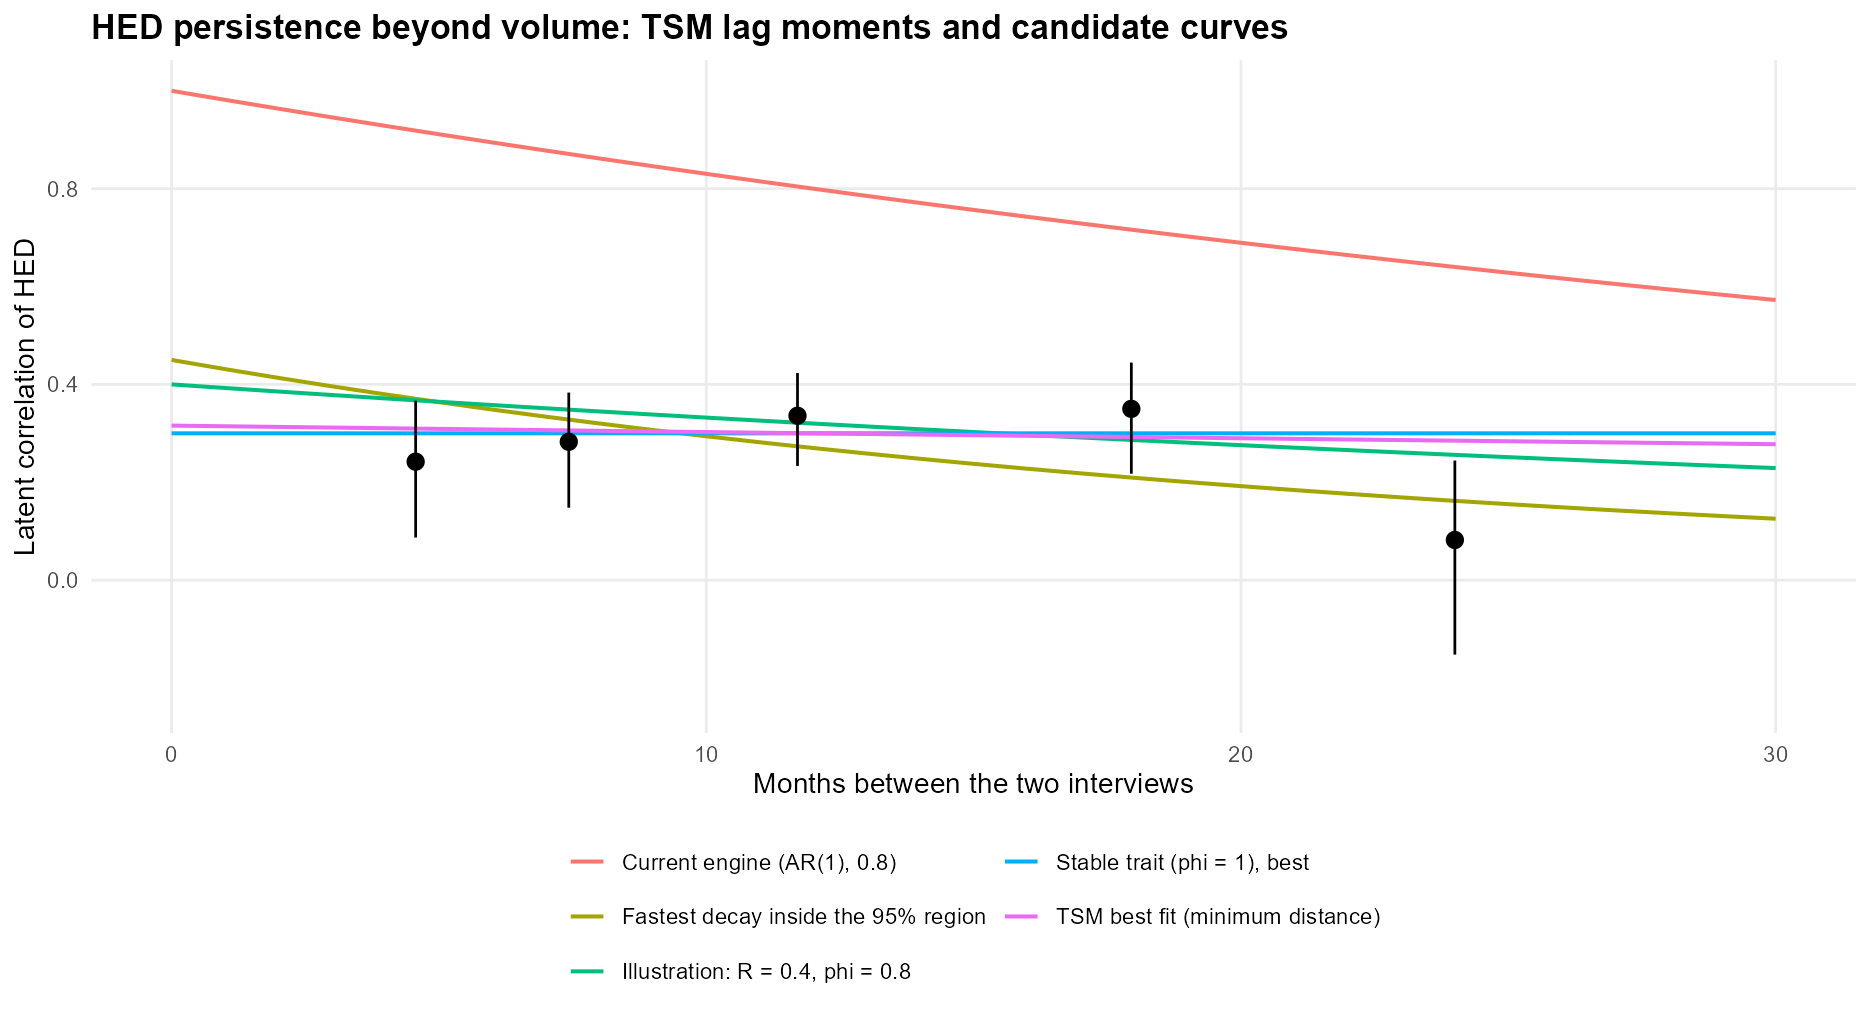

Warning message:
"Removed 4095 rows containing non-finite outside the scale range
(`stat_contour()`)."


Warning message:
"Removed 4095 rows containing non-finite outside the scale range
(`stat_contour()`)."


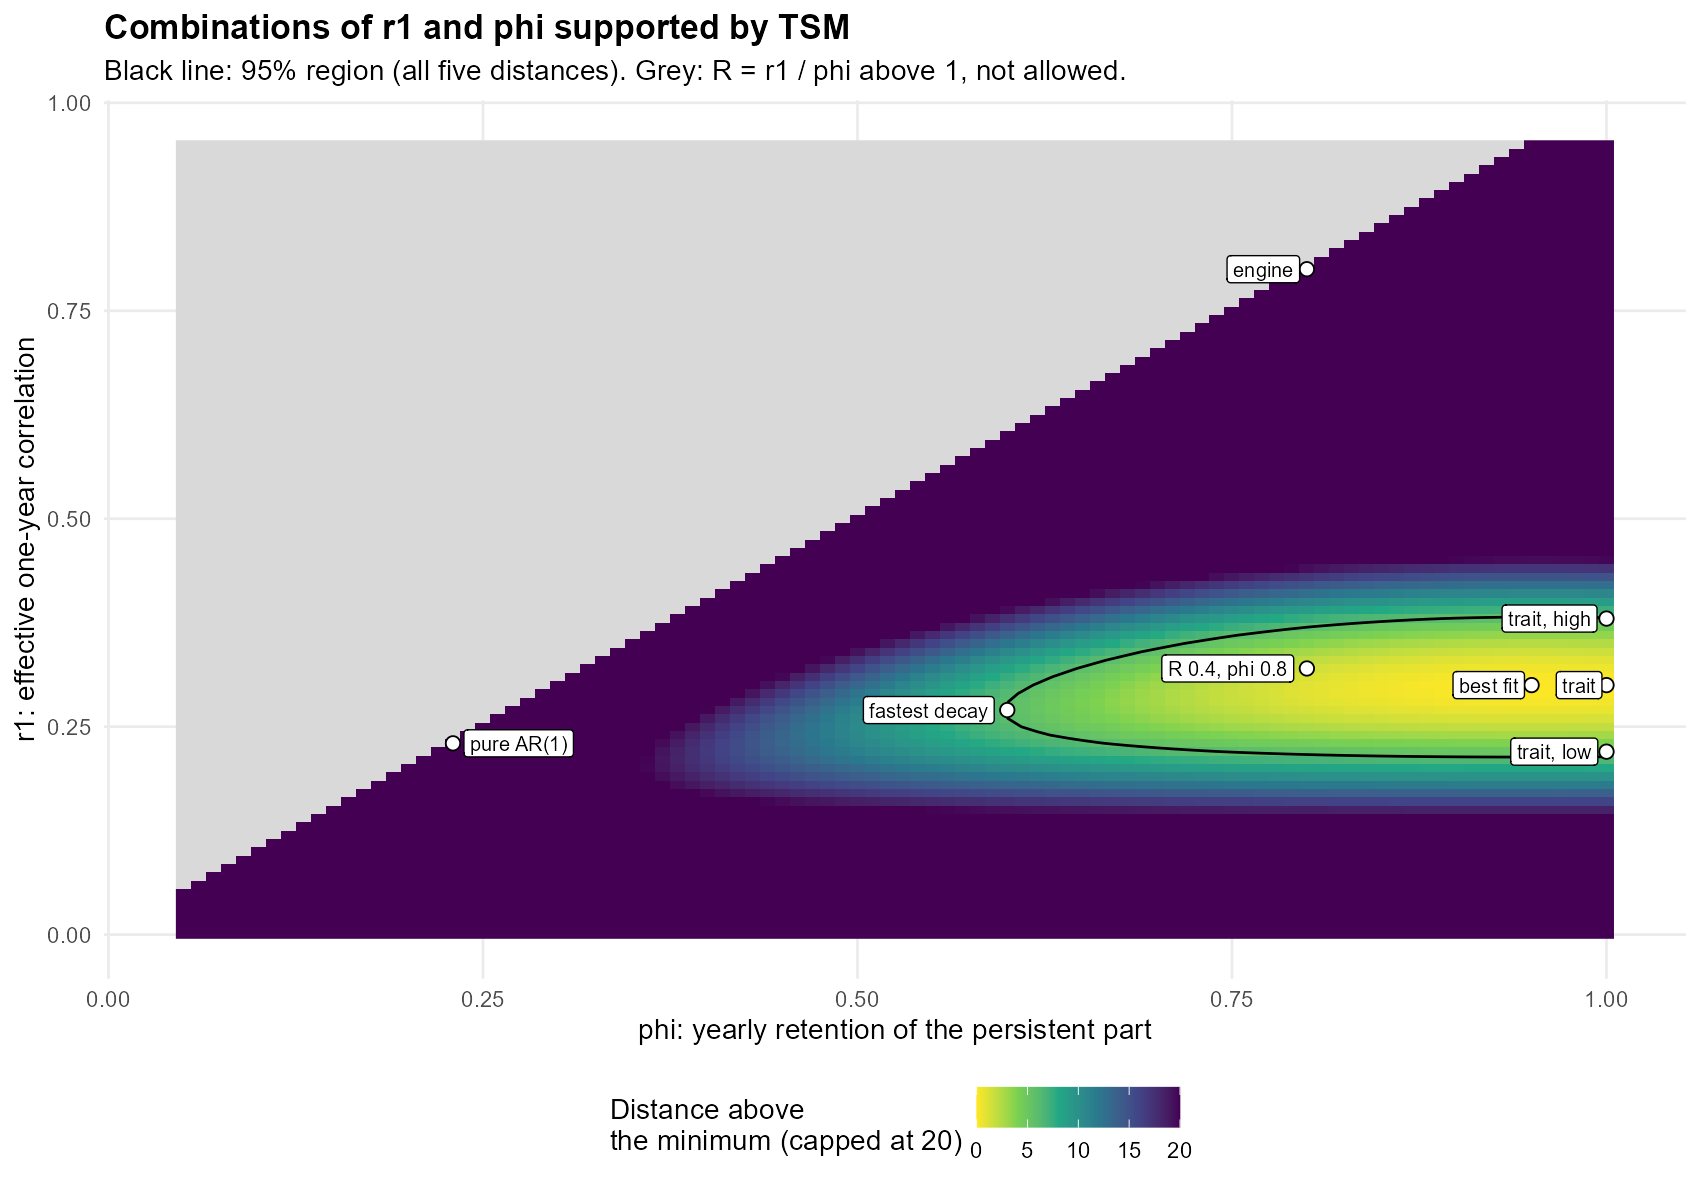

Elapsed: 17.80 minutes


In [28]:
#| label: tsm-hed-persistence
.t0 <- Sys.time()
# HED persistence beyond volume (added 2026-10-27; exploratory). Engine rule: HED_t = 1{g > 0} 1{Phi(Z_t) < p_t} with
# logit p_t = cell(sex x age) + b log1p(g_t) and an AR(1) latent Z whose yearly correlation is assumed to be 0.8. With the
# same margins, the latent correlation between two interviews of a drinker is the parameter of a Gaussian copula.
# Candidate curves: corr(d years) = R phi^d, R = r1 / phi <= 1 (r1 effective one-year correlation, phi yearly retention of
# the persistent part, R its share of the latent variance); months enter as d = months / 12, an explicit assumption.
ts_hedp_gl <- local({ n <- 64; i <- 1:(n - 1); b <- i / sqrt(4 * i^2 - 1); J <- matrix(0, n, n)
  J[cbind(i, i + 1)] <- b; J[cbind(i + 1, i)] <- b; e <- eigen(J, symmetric = TRUE)
  list(x = (e$values + 1) / 2, w = e$vectors[1, ]^2) })   # Gauss-Legendre nodes and weights on (0, 1)
# P(X < h, Y < k) of a standard bivariate normal with correlation rho: the integral over u in (0, Phi(h)) of
# Phi((k - rho qnorm(u)) / sqrt(1 - rho^2)). The nodes depend on h only, so each fit prepares them once.
ts_hedp_prep <- function(h) { ph <- stats::pnorm(h)
  list(ph = ph, q = stats::qnorm(pmin(pmax(outer(ph, ts_hedp_gl$x), 1e-300), 1 - 1e-16))) }
ts_hedp_bvn <- function(pr, k, rho) as.numeric(stats::pnorm((k - rho * pr$q) / sqrt(1 - rho^2)) %*% ts_hedp_gl$w) * pr$ph
ts_hedp_r <- c(-.5, 0, .3, .6, .9); ts_hedp_h <- c(-1.2, .4, 1.5); ts_hedp_k <- c(.7, -.9, 0)
ts_check(max(abs(ts_hedp_bvn(ts_hedp_prep(rep(0, 5)), rep(0, 5), ts_hedp_r) - (.25 + asin(ts_hedp_r) / (2 * pi)))) < 1e-5,
 "HED copula: bivariate normal quadrature matches the closed form at the origin")
ts_check(max(abs(ts_hedp_bvn(ts_hedp_prep(ts_hedp_h), ts_hedp_k, 0) - stats::pnorm(ts_hedp_h) * stats::pnorm(ts_hedp_k))) < 1e-6,
 "HED copula: bivariate normal quadrature factorizes at zero correlation")
ts_check(max(abs(ts_hedp_bvn(ts_hedp_prep(ts_hedp_h), ts_hedp_k, .6) - ts_hedp_bvn(ts_hedp_prep(ts_hedp_k), ts_hedp_h, .6))) < 5e-5,
 "HED copula: bivariate normal quadrature is symmetric in its two limits")
ts_hedp_ll <- function(rho, pr, b, y0, y1, w) {
 p11 <- ts_hedp_bvn(pr, b, rho); pa <- pr$ph; pb <- stats::pnorm(b)
 p <- ifelse(y0 == 1, ifelse(y1 == 1, p11, pa - p11), ifelse(y1 == 1, pb - p11, 1 - pa - pb + p11))
 sum(w * log(pmax(p, 1e-12)))
}
# One stationary margin stacked over both interviews, as in the engine ("volume": cell + log1p g; "bands": cell plus one
# level per frequency x typical-quantity band, which bounds how much of rho is margin misfit), then rho by maximum likelihood.
ts_hedp_fit <- function(z, margin = "volume") {
 z <- z[z$w > 0, ]; n <- nrow(z); cell <- droplevels(z$cell)
 s <- data.frame(y = c(z$y0, z$y1), cell = c(cell, cell), lg = c(z$g0, z$g1), fq = factor(c(z$fq0, z$fq1)), w = rep(z$w, 2))
 f <- if (margin == "volume") y ~ 0 + cell + lg else y ~ 0 + cell + fq
 # Separated bands in the saturated margin only warn about fitted 0/1 probabilities; they are clamped below.
 m <- suppressWarnings(stats::glm(f, data = s, family = stats::quasibinomial(), weights = w / mean(w)))
 p <- pmin(pmax(stats::fitted(m), 1e-6), 1 - 1e-6); b <- stats::qnorm(p[n + 1:n]); pr <- ts_hedp_prep(stats::qnorm(p[1:n]))
 tanh(stats::optimize(function(t) -ts_hedp_ll(tanh(t), pr, b, z$y0, z$y1, z$w), c(-3, 3))$minimum)
}
# Drinkers at both ends of the v4 adjacent pairs; y = 6+ item (hed6), m = 6+ monthly or more often, f = frequency code.
ts_hedp_key <- paste(ts_W$id, ts_W$wave)
ts_hedp_adjacent <- function(d) {
 z <- d[d$current0 == 1 & d$state1 %in% ts_ST[3:5] & d$mult > 0, ]
 k <- match(z$period, ts_time$period); k0 <- match(paste(z$id, ts_time$from[k]), ts_hedp_key)
 k1 <- match(paste(z$id, ts_time$to[k]), ts_hedp_key)
 data.frame(id = z$id, period = z$period, months = ts_time$months[k], sex = z$sex, age_group = z$age_group,
  cell = interaction(z$sex, z$age_group, drop = TRUE), y0 = z$hed6_0, y1 = z$hed6_1,
  m0 = as.numeric(ts_W$e3a3[k0] %in% 3:5), m1 = as.numeric(ts_W$e3a3[k1] %in% 3:5), f0 = ts_W$freq[k0], f1 = ts_W$freq[k1],
  g0 = log1p(z$grams0), g1 = log1p(z$grams1), fq0 = paste(ts_W$freq[k0], ts_W$qty[k0]),
  fq1 = paste(ts_W$freq[k1], ts_W$qty[k1]), w = z$wn, mult = z$mult, stringsAsFactors = FALSE)
}
# Every compatible pair of rounds (4 to 24 months), drinkers at both; no IPW exists for non-adjacent pairs, so w = 1.
ts_hedp_bins <- c("4-5", "7-8", "11-12", "16-19", "24")
ts_hedp_lag <- do.call(rbind, lapply(7:10, function(f) do.call(rbind, lapply((f + 1):11, function(t) {
 a <- ts_W[ts_W$wave == f & ts_W$age >= 18 & ts_W$age <= 65, ]; b <- ts_W[ts_W$wave == t, ]; j <- match(a$id, b$id); z <- b[j, ]
 ok <- !is.na(j) & ts_compatible(a$sex, z$sex, a$age, z$age, ts_months(f, t)) & a$current %in% 1 & z$current %in% 1
 data.frame(id = a$id[ok], from = f, to = t, months = ts_months(f, t), cell = interaction(a$sex[ok], ts_age(a$age[ok]), drop = TRUE),
  y0 = a$hed6[ok], y1 = z$hed6[ok], g0 = log1p(a$grams[ok]), g1 = log1p(z$grams[ok]), fq0 = paste(a$freq[ok], a$qty[ok]),
  fq1 = paste(z$freq[ok], z$qty[ok]), w = 1, stringsAsFactors = FALSE)
}))))
ts_hedp_lag$bin <- as.character(cut(ts_hedp_lag$months, c(0, 6, 9, 14, 21, 30), labels = ts_hedp_bins))
ts_hedp_adj <- ts_hedp_adjacent(ts_d)
ts_check(all(ts_hedp_lag$id %in% ts_risk$id), "HED persistence: every multi-round pair belongs to the person bootstrap frame")
ts_check(sum(ts_hedp_lag$months %in% ts_time$months & ts_hedp_lag$to == ts_hedp_lag$from + 1) == nrow(ts_hedp_adj),
 "HED persistence: adjacent pairs rebuilt from the waves equal the v4 adjacent drinker pairs")
ts_hedp_estimates <- function(adj, lag) {
 c(adjacent_IPW = ts_hedp_fit(adj), adjacent_unweighted = ts_hedp_fit(transform(adj, w = mult)),
  adjacent_bands = ts_hedp_fit(adj, "bands"), adjacent_frequent = ts_hedp_fit(adj[adj$f0 >= 3 & adj$f1 >= 3, ]),
  adjacent_monthly = ts_hedp_fit(transform(adj, y0 = m0, y1 = m1)),
  stats::setNames(vapply(ts_hedp_bins, function(b) ts_hedp_fit(lag[lag$bin == b, ]), 1), paste0("lag_", ts_hedp_bins)))
}
# Whole-person bootstrap with refitted IPW (as the v4 matrices); one multiplicity vector per replicate serves the adjacent
# variants and the multi-round pairs, so the covariance of the lag moments includes people who appear at several lags.
ts_hedp_boot <- function(B = ts_B) {
 set.seed(ts_seed + 800L); master <- sort(unique(ts_risk$id)); reps <- vector("list", B); audit <- vector("list", B)
 for (b in seq_len(B)) {
  m <- as.numeric(ts_person_mult(master)); r <- ts_risk; r$mult <- m[match(r$id, master)]
  lag <- ts_hedp_lag; lag$w <- m[match(lag$id, master)]
  reps[[b]] <- tryCatch(ts_hedp_estimates(ts_hedp_adjacent(ts_ipw_apply(r, ts_ipw_fit(r))), lag), error = function(e) conditionMessage(e))
  audit[[b]] <- data.frame(replicate = b, success = is.numeric(reps[[b]]), error = if (is.numeric(reps[[b]])) "" else reps[[b]])
  if (b %% 100 == 0 || b == B) cat(sprintf("TSM bootstrap (HED persistence) %d/%d; IPW refitted\n", b, B))
 }
 audit <- do.call(rbind, audit); ts_save(audit, "hed_persistence_bootstrap_audit")
 if (!all(audit$success)) stop("HED persistence bootstrap failures: inspect hed_persistence_bootstrap_audit.csv")
 do.call(rbind, reps)
}
ts_hedp_point <- ts_hedp_estimates(ts_hedp_adj, ts_hedp_lag)
ts_hedp_reps <- ts_hedp_boot()
ts_hedp_ci <- function(v) c(lower = unname(stats::quantile(ts_hedp_reps[, v], .025)), upper = unname(stats::quantile(ts_hedp_reps[, v], .975)))
# Joint maximum likelihood of margin and rho: the core of a GJRM bivariate binary model (logit margins, Gaussian copula).
ts_hedp_joint <- local({
 z <- ts_hedp_adj; z$cell <- droplevels(z$cell); X <- stats::model.matrix(~ 0 + cell, z); nb <- ncol(X); w <- z$w / mean(z$w)
 s <- data.frame(y = c(z$y0, z$y1), cell = c(z$cell, z$cell), lg = c(z$g0, z$g1), w = rep(w, 2))
 st <- c(stats::coef(stats::glm(y ~ 0 + cell + lg, data = s, family = stats::quasibinomial(), weights = w)), atanh(ts_hedp_point[["adjacent_IPW"]]))
 nll <- function(th) {
  q <- function(g) stats::qnorm(pmin(pmax(stats::plogis(as.numeric(X %*% th[1:nb] + th[nb + 1] * g)), 1e-6), 1 - 1e-6))
  -ts_hedp_ll(tanh(th[nb + 2]), ts_hedp_prep(q(z$g0)), q(z$g1), z$y0, z$y1, w)
 }
 o <- stats::optim(st, nll, method = "BFGS", control = list(maxit = 500))
 c(rho = tanh(o$par[[nb + 2]]), slope = o$par[[nb + 1]], slope_two_step = st[[nb + 1]], converged = o$convergence == 0)
})
ts_check(isTRUE(as.logical(ts_hedp_joint[["converged"]])), "HED persistence: joint margin and copula likelihood converged")

# Tables: transitions of all adjacent pairs, and repetition of HED within volume bands at t+1 (weighted, IPW).
ts_hedp_lab <- function(cur, h) ifelse(cur == 1, ifelse(h == 1, "Drinks, HED", "Drinks, no HED"), "Does not drink")
ts_hedp_t <- data.frame(origin = ts_hedp_lab(ts_d$current0, ts_d$hed6_0),
 destination = ts_hedp_lab(as.numeric(ts_d$state1 %in% ts_ST[3:5]), ts_d$hed6_1), wn = ts_d$wn)
ts_hedp_trans <- do.call(rbind, lapply(split(ts_hedp_t, ts_hedp_t$origin), function(z) {
 lv <- c("Does not drink", "Drinks, no HED", "Drinks, HED")
 data.frame(origin = z$origin[1], pairs = nrow(z), t(stats::setNames(vapply(lv, function(l) 100 * sum(z$wn[z$destination == l]) / sum(z$wn), 1),
  paste0("pct_", c("does_not_drink", "drinks_no_HED", "drinks_HED")))))
}))
ts_hedp_rep <- local({
 z <- ts_hedp_adj; z$volume_t1 <- as.character(cut(expm1(z$g1), c(0, 2, 10, Inf), labels = c("<=2 g/day", "2-10 g/day", ">10 g/day")))
 one <- function(x, group) data.frame(group = group, pairs = nrow(x), HED_at_t = sum(x$y0),
  pct_HED_t1_if_HED_t = 100 * stats::weighted.mean(x$y1[x$y0 == 1], x$w[x$y0 == 1]),
  pct_HED_t1_if_no_HED_t = 100 * stats::weighted.mean(x$y1[x$y0 == 0], x$w[x$y0 == 0]))
 rbind(do.call(rbind, lapply(c("<=2 g/day", "2-10 g/day", ">10 g/day"), function(v) one(z[z$volume_t1 == v, ], paste("Volume at t+1", v)))),
  do.call(rbind, lapply(c("Men", "Women"), function(s) one(z[z$sex == s, ], s))), one(z, "All drinker pairs"))
})
# Transition logistic: odds ratio of previous HED, person-clustered, IPW; and person-blocked CV of the added information.
ts_hedp_des <- survey::svydesign(ids = ~id, weights = ~w, data = ts_hedp_adj)
ts_hedp_forms <- list(previous_volume = y1 ~ sex * age_group + g0, previous_volume_plus_HED = y1 ~ sex * age_group + g0 + y0,
 same_round_volume = y1 ~ sex * age_group + g1, same_round_volume_plus_HED = y1 ~ sex * age_group + g1 + y0,
 both_volumes_plus_HED = y1 ~ sex * age_group + g0 + g1 + y0)
ts_hedp_or <- do.call(rbind, lapply(grep("plus_HED$", names(ts_hedp_forms), value = TRUE), function(k) {
 m <- survey::svyglm(ts_hedp_forms[[k]], ts_hedp_des, family = stats::quasibinomial()); ci <- suppressMessages(stats::confint(m))["y0", ]
 data.frame(model = k, OR_previous_HED = exp(stats::coef(m)[["y0"]]), lower = exp(ci[[1]]), upper = exp(ci[[2]]))
}))
ts_hedp_auc <- function(y, p) { r <- rank(p); n1 <- sum(y); (sum(r[y == 1]) - n1 * (n1 + 1) / 2) / (n1 * (length(y) - n1)) }
ts_hedp_cvfolds <- do.call(rbind, lapply(seq_len(ts_repeats), function(rp) {
 fold <- ts_fold(ts_hedp_adj$id, ts_K, ts_seed + 810L + rp); te_all <- fold[ts_hedp_adj$id]
 do.call(rbind, lapply(seq_len(ts_K), function(k) {
  tr <- ts_hedp_adj[te_all != k, ]; te <- ts_hedp_adj[te_all == k, ]
  do.call(rbind, lapply(names(ts_hedp_forms), function(nm) {
   m <- stats::glm(ts_hedp_forms[[nm]], data = tr, family = stats::quasibinomial(), weights = w / mean(w))
   p <- pmin(pmax(stats::predict(m, te, type = "response"), 1e-6), 1 - 1e-6)
   data.frame(repetition = rp, fold = k, model = nm, AUC = ts_hedp_auc(te$y1, p), logloss = -mean(te$y1 * log(p) + (1 - te$y1) * log(1 - p)))
  }))
 }))
}))
ts_hedp_cv <- stats::aggregate(cbind(AUC, logloss) ~ model, ts_hedp_cvfolds, mean)
ts_hedp_cvgain <- do.call(rbind, lapply(c("previous_volume", "same_round_volume"), function(base) {
 a <- ts_hedp_cvfolds[ts_hedp_cvfolds$model == base, ]; b <- ts_hedp_cvfolds[ts_hedp_cvfolds$model == paste0(base, "_plus_HED"), ]
 data.frame(comparison = paste0(base, "_plus_HED minus ", base), mean_logloss_difference = mean(b$logloss - a$logloss),
  mean_AUC_difference = mean(b$AUC - a$AUC), folds_with_lower_logloss = sum(b$logloss < a$logloss), folds = nrow(a))
}))

# Latent correlations: adjacent variants and the five lag moments, with whole-person bootstrap intervals.
ts_hedp_variants <- data.frame(estimate = names(ts_hedp_point)[1:5],
 description = c("Adjacent pairs, engine margin, IPW (primary)", "Adjacent pairs, engine margin, no IPW",
  "Adjacent pairs, saturated frequency x quantity margin, IPW", "Adjacent pairs, drinkers 2+ times a month at both rounds, IPW",
  "Adjacent pairs, 6+ drinks monthly or more often (prevalence about 9%), IPW"),
 pairs = c(rep(nrow(ts_hedp_adj), 3), sum(ts_hedp_adj$f0 >= 3 & ts_hedp_adj$f1 >= 3), nrow(ts_hedp_adj)),
 rho = unname(ts_hedp_point[1:5]), t(vapply(names(ts_hedp_point)[1:5], ts_hedp_ci, numeric(2))), row.names = NULL)
ts_hedp_shift <- ts_hedp_reps[, "adjacent_IPW"] - ts_hedp_reps[, "adjacent_unweighted"]
ts_hedp_variants <- rbind(ts_hedp_variants, data.frame(estimate = c("IPW_minus_unweighted", "joint_ML"),
 description = c("Effect of the IPW weights on the adjacent estimate", "Margin and rho in one likelihood (GJRM-type core), point only"),
 pairs = nrow(ts_hedp_adj), rho = c(ts_hedp_point[["adjacent_IPW"]] - ts_hedp_point[["adjacent_unweighted"]], ts_hedp_joint[["rho"]]),
 lower = c(unname(stats::quantile(ts_hedp_shift, .025)), NA), upper = c(unname(stats::quantile(ts_hedp_shift, .975)), NA)))
ts_hedp_mix <- stats::aggregate(n ~ bin + months, transform(ts_hedp_lag, n = 1), sum)
ts_hedp_moments <- data.frame(bin = ts_hedp_bins,
 rounds = vapply(ts_hedp_bins, function(b) paste(unique(paste0("R", ts_hedp_lag$from, "-R", ts_hedp_lag$to)[ts_hedp_lag$bin == b]), collapse = ";"), ""),
 mean_months = vapply(ts_hedp_bins, function(b) mean(ts_hedp_lag$months[ts_hedp_lag$bin == b]), 1),
 pairs = vapply(ts_hedp_bins, function(b) sum(ts_hedp_lag$bin == b), 1),
 persons = vapply(ts_hedp_bins, function(b) length(unique(ts_hedp_lag$id[ts_hedp_lag$bin == b])), 1),
 rho = unname(ts_hedp_point[paste0("lag_", ts_hedp_bins)]), t(vapply(paste0("lag_", ts_hedp_bins), ts_hedp_ci, numeric(2))), row.names = NULL)

# Which (r1, phi) does TSM support? Minimum distance between the five lag moments and the curve R phi^(months/12), with the
# whole-person bootstrap covariance (people repeat across lags). 95% joint region: distance within qchisq(.95, 2) of the minimum.
ts_hedp_S <- stats::cov(ts_hedp_reps[, paste0("lag_", ts_hedp_bins)])
ts_hedp_shape <- function(phi) matrix(sapply(ts_hedp_bins, function(b) { k <- ts_hedp_mix[ts_hedp_mix$bin == b, ]
 vapply(phi, function(p) sum(k$n * p^(k$months / 12)) / sum(k$n), 1) }), nrow = length(phi))   # rows phi, columns bins
ts_hedp_distance <- function(r1, phi, keep = seq_along(ts_hedp_bins)) {
 E <- matrix(ts_hedp_moments$rho[keep], length(r1), length(keep), byrow = TRUE) - (r1 / phi) * ts_hedp_shape(phi)[, keep, drop = FALSE]
 rowSums((E %*% solve(ts_hedp_S[keep, keep])) * E)
}
ts_hedp_grid <- expand.grid(r1 = round(seq(0, .95, .01), 2), phi = round(seq(.05, 1, .01), 2))
ts_hedp_grid <- ts_hedp_grid[ts_hedp_grid$r1 <= ts_hedp_grid$phi, ]
ts_hedp_grid$R <- ts_hedp_grid$r1 / ts_hedp_grid$phi
# Region, profiles and fit for a set of lag moments; the primary uses all five, the sensitivity drops the single 24-month
# pair (R7-R11: one round pair, the most retention-selected, with the least certain fieldwork date).
ts_hedp_region <- function(keep, label) {
 g <- ts_hedp_grid; g$distance <- ts_hedp_distance(g$r1, g$phi, keep); dmin <- min(g$distance)
 inside <- g[g$distance - dmin <= stats::qchisq(.95, 2), ]
 prof <- function(v) { p <- tapply(g$distance, g[[v]], min); range(as.numeric(names(p))[p - dmin <= stats::qchisq(.95, 1)]) }
 list(grid = g, dmin = dmin, inside = inside,
  fit = data.frame(moments = label, minimum_distance = dmin, n_moments = length(keep), parameters = 2,
   p_value = stats::pchisq(dmin, length(keep) - 2, lower.tail = FALSE), best_r1 = g$r1[which.min(g$distance)],
   best_phi = g$phi[which.min(g$distance)], bootstrap_replicates = nrow(ts_hedp_reps)),
  ranges = data.frame(moments = label, quantity = c("r1 (profile 95%)", "phi (profile 95%)", "R inside the 95% region",
   "correlation at 5 years inside the region", "correlation at 10 years inside the region"),
   lower = c(prof("r1")[1], prof("phi")[1], min(inside$R), min(inside$R * inside$phi^5), min(inside$R * inside$phi^10)),
   upper = c(prof("r1")[2], prof("phi")[2], max(inside$R), max(inside$R * inside$phi^5), max(inside$R * inside$phi^10)),
   read_as = c("supported by the data", "weakly identified", "supported by the data", "assumption (extrapolation)", "assumption (extrapolation)")))
}
ts_hedp_main <- ts_hedp_region(seq_along(ts_hedp_bins), "all five distances")
ts_hedp_no24 <- ts_hedp_region(seq_len(length(ts_hedp_bins) - 1), "without the 24-month pair")
ts_hedp_grid <- ts_hedp_main$grid
ts_hedp_dmin <- ts_hedp_main$dmin
ts_hedp_grid$delta <- ts_hedp_grid$distance - ts_hedp_dmin
ts_hedp_grid$supported_95 <- ts_hedp_grid$delta <= stats::qchisq(.95, 2)
ts_hedp_in <- ts_hedp_grid[ts_hedp_grid$supported_95, ]
ts_check(nrow(ts_hedp_in) > 0, "HED persistence: the 95% region of (r1, phi) is not empty")
ts_hedp_best <- ts_hedp_grid[which.min(ts_hedp_grid$distance), ]
ts_hedp_on <- function(rows) rows[which.min(rows$distance), c("r1", "phi")]
ts_hedp_fast <- ts_hedp_in[ts_hedp_in$phi == min(ts_hedp_in$phi), ]
ts_hedp_trait <- ts_hedp_in[ts_hedp_in$phi == 1, ]
ts_hedp_named <- rbind(
 data.frame(scenario = "TSM best fit (minimum distance)", ts_hedp_best[c("r1", "phi")]),
 data.frame(scenario = "Stable trait (phi = 1), best", ts_hedp_on(ts_hedp_grid[ts_hedp_grid$phi == 1, ])),
 if (nrow(ts_hedp_trait)) data.frame(scenario = c("Stable trait, lowest supported r1", "Stable trait, highest supported r1"),
  r1 = range(ts_hedp_trait$r1), phi = 1),
 data.frame(scenario = "Fastest decay inside the 95% region", ts_hedp_on(ts_hedp_fast)),
 data.frame(scenario = "Pure AR(1) without an occasion component (R = 1), best", ts_hedp_on(ts_hedp_grid[abs(ts_hedp_grid$R - 1) < 1e-9, ])),
 data.frame(scenario = c("Illustration: R = 0.4, phi = 0.8", "Current engine (AR(1), 0.8)"), r1 = c(.32, .8), phi = c(.8, .8)))
ts_hedp_named$R <- ts_hedp_named$r1 / ts_hedp_named$phi
ts_hedp_named$distance <- ts_hedp_distance(ts_hedp_named$r1, ts_hedp_named$phi)
ts_hedp_named$delta <- ts_hedp_named$distance - ts_hedp_dmin
ts_hedp_named$fixed_point_p <- stats::pchisq(ts_hedp_named$distance, length(ts_hedp_bins), lower.tail = FALSE)
for (y in c(4 / 12, 1, 2, 5, 10)) ts_hedp_named[[c("corr_4_months", "corr_1_year", "corr_2_years", "corr_5_years",
 "corr_10_years")[match(y, c(4 / 12, 1, 2, 5, 10))]]] <- ts_hedp_named$R * ts_hedp_named$phi^y
ts_hedp_named$TSM_support <- ifelse(ts_hedp_named$delta <= stats::qchisq(.95, 2), "inside the 95% region (4-24 months)", "outside the 95% region")
ts_hedp_named$beyond_24_months <- "assumption: TSM observes 4 to 24 months only"
ts_hedp_named$TSM_support_without_24_months <- ifelse(ts_hedp_distance(ts_hedp_named$r1, ts_hedp_named$phi, 1:4) - ts_hedp_no24$dmin <=
 stats::qchisq(.95, 2), "inside", "outside")
ts_hedp_ranges <- rbind(ts_hedp_main$ranges, ts_hedp_no24$ranges)
ts_hedp_gof <- rbind(ts_hedp_main$fit, ts_hedp_no24$fit)
ts_save(ts_hedp_trans, "hed_persistence_transitions"); ts_save(ts_hedp_rep, "hed_persistence_repeat")
ts_save(ts_hedp_or, "hed_persistence_logistic"); ts_save(ts_hedp_cv, "hed_persistence_logistic_cv")
ts_save(ts_hedp_cvgain, "hed_persistence_logistic_cv_gain"); ts_save(ts_hedp_variants, "hed_persistence_adjacent")
ts_save(ts_hedp_moments, "hed_persistence_lag_moments")
ts_save(data.frame(bin = ts_hedp_bins, ts_hedp_S, row.names = NULL), "hed_persistence_moment_covariance")
ts_save(ts_hedp_grid, "hed_persistence_grid"); ts_save(ts_hedp_named, "hed_persistence_scenarios")
ts_save(ts_hedp_ranges, "hed_persistence_ranges"); ts_save(ts_hedp_gof, "hed_persistence_fit")
ts_show(ts_hedp_trans, "All adjacent pairs: drinking and the 6+ item at the next round, weighted row percentages", 1)
ts_show(ts_hedp_rep, "Drinkers at both rounds: HED at t+1 by HED at t, within volume bands at t+1 and by sex (IPW)", 1)
ts_show(ts_hedp_or, "Transition logistic: odds ratio of previous HED, person-clustered intervals, IPW", 2)
ts_show(ts_hedp_cv, "Person-blocked CV (5 folds x repeats): held-out AUC and log loss without and with previous HED", 4)
ts_show(ts_hedp_cvgain, "Held-out gain from previous HED", 4)
ts_show(ts_hedp_variants, "Latent correlation of HED between adjacent rounds, engine-type copula, whole-person bootstrap intervals", 3)
ts_show(ts_hedp_moments, "Latent correlation by distance between rounds, all compatible pairs of drinkers (no IPW)", 3)
ts_show(ts_hedp_gof, "Minimum-distance fit of R phi^(months/12): all five distances, and without the 24-month pair", 3)
ts_show(ts_hedp_ranges, "What TSM supports and what remains an assumption, with and without the 24-month pair", 3)
ts_show(ts_hedp_named, "Named scenarios for later engine and DIR work: support by TSM and implied correlations", 3)
ts_hedp_pick <- match(c("TSM best fit (minimum distance)", "Stable trait (phi = 1), best", "Fastest decay inside the 95% region",
 "Illustration: R = 0.4, phi = 0.8", "Current engine (AR(1), 0.8)"), ts_hedp_named$scenario)
ts_hedp_pick <- ts_hedp_pick[!duplicated(paste(ts_hedp_named$r1, ts_hedp_named$phi)[ts_hedp_pick])]   # identical curves drawn once
ts_hedp_curves <- do.call(rbind, lapply(ts_hedp_pick, function(i)
 data.frame(scenario = ts_hedp_named$scenario[i], months = 0:30, corr = ts_hedp_named$R[i] * ts_hedp_named$phi[i]^((0:30) / 12))))
ts_hedp_named$label <- c("best fit", "trait", "trait, low", "trait, high", "fastest decay", "pure AR(1)", "R 0.4, phi 0.8", "engine")[
 match(ts_hedp_named$scenario, c("TSM best fit (minimum distance)", "Stable trait (phi = 1), best", "Stable trait, lowest supported r1",
  "Stable trait, highest supported r1", "Fastest decay inside the 95% region", "Pure AR(1) without an occasion component (R = 1), best",
  "Illustration: R = 0.4, phi = 0.8", "Current engine (AR(1), 0.8)"))]
ts_hedp_labels <- ts_hedp_named[!duplicated(paste(ts_hedp_named$r1, ts_hedp_named$phi)), ]
ts_hedp_plotgrid <- expand.grid(r1 = round(seq(0, .95, .01), 2), phi = round(seq(.05, 1, .01), 2))
ts_hedp_plotgrid$delta <- ts_hedp_grid$delta[match(paste(ts_hedp_plotgrid$r1, ts_hedp_plotgrid$phi), paste(ts_hedp_grid$r1, ts_hedp_grid$phi))]
ts_fig(ggplot2::ggplot(ts_hedp_moments, ggplot2::aes(mean_months, rho)) +
 ggplot2::geom_line(data = ts_hedp_curves, ggplot2::aes(months, corr, colour = scenario), linewidth = .8) +
 ggplot2::geom_pointrange(ggplot2::aes(ymin = lower, ymax = upper)) +
 ggplot2::coord_cartesian(ylim = c(-.25, 1)) + ggplot2::labs(x = "Months between the two interviews", y = "Latent correlation of HED",
  colour = NULL, title = "HED persistence beyond volume: TSM lag moments and candidate curves") + ts_theme() +
 ggplot2::guides(colour = ggplot2::guide_legend(ncol = 2)), "fig_hed_persistence_lags", 11, 6)
ts_fig(ggplot2::ggplot(ts_hedp_plotgrid, ggplot2::aes(phi, r1)) + ggplot2::geom_raster(ggplot2::aes(fill = pmin(delta, 20))) +
 ggplot2::geom_contour(ggplot2::aes(z = delta), breaks = stats::qchisq(.95, 2), colour = "black") +
 ggplot2::geom_point(data = ts_hedp_labels, shape = 21, fill = "white", size = 2.5) +
 ggplot2::geom_label(data = ts_hedp_labels, ggplot2::aes(label = label, hjust = ifelse(phi < .5, -.1, 1.1)), size = 3, fill = "white") +
 ggplot2::scale_fill_viridis_c(name = "Distance above\nthe minimum (capped at 20)", direction = -1, na.value = "grey85") +
 ggplot2::labs(x = "phi: yearly retention of the persistent part", y = "r1: effective one-year correlation",
  title = "Combinations of r1 and phi supported by TSM", subtitle = "Black line: 95% region (all five distances). Grey: R = r1 / phi above 1, not allowed.") + ts_theme(),
 "fig_hed_persistence_region", 10, 7)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


## Limitations, review and reproducibility

- The TSM alcohol items have no recall window, so "current drinking", FD and the quantity signals are proxies, not ENPG 30-day constructs.
- No primary sampling units or strata are released; `Fact_Exp` is cross-sectional, and the whole-person bootstrap is the only uncertainty computed. It does not reconstruct the original design variance.
- Round dates are approximate fieldwork months, and the date of round 11 is unverified; the elapsed months, and with them the link rule and the annual layer, inherit this approximation.
- At 12 g per drink C3plus is nearly empty with the primary lookup; its probabilities come mostly from model tails and from the conversion sensitivities.
- TSM intervals are short compared with the multi-year EPS intervals; short intervals observe fewer changes and make the annual layer depend more on the generator assumptions.
- FD requires observed earlier drinking within the panel; N0 is incomplete history. TSM FD identifies people who drank within the previous year or two, so its relapse rate is a different quantity from the EPS former-drinker row.
- Pooled next-round tables mix four interval lengths; only the annual layer compares with EPS, with the caveat that a generator fitted to months-long windows is a compromise across intervals.
- HED persistence is exploratory: the 6+ item differs from the ENPG 30-day item behind the engine's margin, the panel spans 4 to 24 months so long-run persistence is an assumption, and the multi-round pairs are unweighted.

The checks recorded during execution are listed in the table below and exported together with the configuration, the fit warnings and the session information without machine paths. The notebook is executed in a fresh kernel twice, in the working output folder and in a reproduction folder; an external verifier compares the exported tables byte by byte, records a hash of the notebook code and inserts the quick-reading summary and the reproduction check. Reproducing results does not prove the assumptions true.


In [29]:
#| label: tsm-reproducibility
.t0 <- Sys.time()
ts_checks_table <- data.frame(check = names(ts_checks), passed = unlist(ts_checks), row.names = NULL)
ts_save(ts_checks_table, "analysis_checks")
ts_save(data.frame(seed = ts_seed, person_bootstrap_replicates = ts_B, CV_repetitions = ts_repeats,
 periods = paste(ts_periods, collapse = ";"), grams_primary = 12, education_rule = "lenient"), "analysis_configuration")
ww <- as.data.frame(table(ts_warnings), stringsAsFactors = FALSE); names(ww) <- c("warning", "n")
ts_save(ww, "fit_warnings")
ts_check(all(ts_checks_table$passed), "All recorded checks passed")
ts_show(ts_checks_table, "Executed checks on real TSM data")
si <- utils::capture.output(utils::sessionInfo())
writeLines(si[!grepl("[A-Za-z]:[/\\\\]", si)], file.path(ts_out, "session_info.txt"))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


check,passed
One row per person and interval,TRUE
Positive finite main weights,TRUE
Observed pairs respect the history-state transition map,TRUE
v2 regression quantities match,TRUE
Tolerance evidence matches the primary link count,TRUE
Weight-scale invariance Gamma,TRUE
Weight-scale invariance Lognormal,TRUE
Weight-scale invariance Multinomial,TRUE
Weight-scale invariance Ordinal_two_part,TRUE
Disjoint persons CV 1:1,TRUE


Elapsed: 0.00 minutes


## Reproduction check: PASS

The notebook ran twice in **fresh R kernels**, with 29 completed code cells and no errors. All **74 CSV files (19,213 aggregate rows)** are byte-identical between the main run and the reproduction. They include 1,000 whole-person replicates with refitted IPW.

The external verifier checked that both runs used the same notebook code, the exported results and every recorded R check. This cell reports that subsequent verification; it does not simulate another execution. Figures were inspected separately. Model assumptions and external validity still require assessment.

[Review report](__andres_control/tsm_v3_review.md) · [File comparison](__andres_control/tsm_markov_outputs_v4/reproducibility_check.csv)

## References

- Calvo E, Medina JT, Ornstein KA, Staudinger UM, Fried LP, Keyes KM. Cross-country and historical variation in alcohol consumption among older men and women: leveraging recently harmonized survey data in 21 countries. *Drug and Alcohol Dependence*. 2020;215:108219. DOI [10.1016/j.drugalcdep.2020.108219](https://doi.org/10.1016/j.drugalcdep.2020.108219).
- Kilian C, Buckley C, Lemp JM, Kou X, Kerr WC, Mulia N, Purshouse RC, Rehm J, Probst C. Targeting alcohol use in high-risk population groups: a US microsimulation study of beverage-specific pricing policies. *Lancet Public Health*. 2025. DOI [10.1016/S2468-2667(25)00165-3](https://doi.org/10.1016/S2468-2667(25)00165-3).
- Hamaker EL, Kuiper RM, Grasman RPPP. A critique of the cross-lagged panel model. *Psychological Methods*. 2015;20(1):102–116. DOI [10.1037/a0038889](https://doi.org/10.1037/a0038889).
- Puka K, Buckley C, Mulia N, Purshouse RC, Lasserre AM, Kerr W, Rehm J, Probst C. Behavioral stability of alcohol consumption and socio-demographic correlates of change among a nationally representative cohort of US adults. *Addiction*. 2023;118(1):61–70. DOI [10.1111/add.16024](https://doi.org/10.1111/add.16024).
- SIMAH microsimulation, release 0.1.1. DOI [10.5281/zenodo.15641639](https://doi.org/10.5281/zenodo.15641639). This notebook estimates Chilean transition components; it does not execute SIMAH or import US parameter values.
- EPS engine and notebook: `__andres_control/eps_markov_core.R`, `__andres_control/eps_markov_transitions_EN.ipynb`; harmonization source `__andres_control/eps_alcohol_prevalencia_persistencia.ipynb`.
- TSM version 2 notes and outputs: `_tsm/notes/TSM_ENPG_v2_EN.md`, `_tsm/notes/TSM_ENPG_v2_findings.md`, `_tsm/notes/v2_outputs/`; version 3 contract `__andres_control/tsm_v3_plan_2026-10-19.md`; questionnaires in `_tsm/docs/`.
